# Анализ бизнес-сообществ

## Часть 1. Подготовка

### (1) Импорты и загрузка данных

Импортируем библиотеки, задаём путь к подготовленному датасету и загружаем данные. **Рабочая таблица `df` содержит все бизнесы.**

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

DATA_FILE = Path("data/businesses_clean.csv")
df = pd.read_csv(DATA_FILE)

### (2) Настройка темы графиков

Задаём общую палитру и оформление графиков для всего анализа.

In [2]:
PRIMARY_COLOR = "#0077FF"
SECONDARY_COLOR = "#8024C0"
CHART_PALETTE = [PRIMARY_COLOR, SECONDARY_COLOR, "#17D685", "#FF3985", "#00EAFF"]
SEQUENTIAL_CMAP = sns.blend_palette(["#FFFFFF", PRIMARY_COLOR], as_cmap=True)
DIVERGING_CMAP = sns.blend_palette([SECONDARY_COLOR, "#FFFFFF", PRIMARY_COLOR], as_cmap=True)
sns.set_theme(style="whitegrid", font="DejaVu Sans", palette=CHART_PALETTE, rc={
    "figure.facecolor": "white", "axes.facecolor": "white",
    "text.color": "#212121", "axes.labelcolor": "#212121",
    "xtick.color": "#212121", "ytick.color": "#212121",
    "grid.color": "#DEDEDE", "grid.alpha": .6, "grid.linewidth": .6,
    "axes.edgecolor": "#DEDEDE", "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlepad": 16, "axes.labelpad": 10,
    "legend.frameon": False, "figure.dpi": 120, "savefig.dpi": 160,
})

## Часть 2. Бизнесы с подключённым чекаутом

**Рассматриваем бизнесы с подключённым чекаутом на конец периода** — как с заказами, так и без них. Сравниваем аудиторию, контент, рекламу, инструменты продаж и ассортимент. Для отдельных вопросов используем подгруппы, состав которых указан в соответствующем шаге.

### Шаг 1. Подключение чекаута и наличие заказов

**Вопрос:** Сколько бизнесов с подключённым чекаутом имеют заказы, а сколько — нет?

Оставляем бизнесы с чекаутом на конец периода. Наличие заказов определяем по числу заказов через чекаут за период. Доли считаем внутри этой группы.

In [3]:
df_checkout = df.loc[df["Подключён чекаут"].eq(1)].copy()
order_groups = df_checkout["Заказы через чекаут"].gt(0).value_counts().reindex([True, False], fill_value=0)
order_groups = order_groups.rename(index={True: "Есть заказы", False: "Нет заказов"}).to_frame("Бизнесов")
order_groups.index.name = "Наличие заказов"
order_groups["Доля, %"] = order_groups["Бизнесов"] / len(df_checkout) * 100
order_groups.loc["Всего с чекаутом"] = {"Бизнесов": len(df_checkout), "Доля, %": 100}
order_groups["Бизнесов"] = order_groups["Бизнесов"].astype(int)
display(order_groups.round(2))

,Бизнесов,"Доля, %"
Наличие заказов,,
Есть заказы,284,4.95
Нет заказов,5453,95.05
Всего с чекаутом,5737,100.00


**Вывод:** у подавляющего большинства бизнесов с подключённым чекаутом — **95,05% (5 453 из 5 737)** — нет заказов через него за рассматриваемый период. Это **существенный разрыв** между подключением инструмента и получением заказов: одного подключения недостаточно. Поэтому важно разобраться, что отличает бизнесы с заказами от остальных и что может мешать получать результат.

**Гипотеза 1. Недоверие покупателей.** У части бизнесов с подключённым чекаутом может не быть заказов из-за недоверия покупателей к оформлению покупки через ВКонтакте. Покупатели могут предпочитать другие способы заказа.

**Как проверить:** нужны опросы покупателей и данные об отказах на этапах оформления заказа. Текущий датасет не позволяет установить, связано ли отсутствие заказов именно с недоверием.

**Гипотеза 2. Низкий ожидаемый спрос мешает подключению.** Бизнесы могут не подключать чекаут, поскольку считают, что покупатели редко пользуются этим способом заказа, и не видят достаточных перспектив продаж через него.

**Как проверить:** в анализе бизнесов без чекаута посмотрим на признаки покупательского интереса — просмотры товаров и открытия карточек. Они помогут выделить группы для проверки гипотезы, но мотивы неподключения нужно уточнять у самих продавцов. Результат шага 1 служит поводом для этой гипотезы, а не её подтверждением.

**Переход к следующему шагу:** У большинства бизнесов с чекаутом нет заказов. Отличается ли размер аудитории у бизнесов с заказами и без них?

### Шаг 2. Размер аудитории и наличие заказов

**Вопрос:** Отличается ли число подписчиков у бизнесов с заказами и без заказов?

Сравниваем бизнесы с подключённым чекаутом.

In [4]:
df_checkout["Группа заказов"] = df_checkout["Заказы через чекаут"].gt(0).map({True: "Есть заказы", False: "Нет заказов"})
audience_summary = df_checkout.groupby("Группа заказов")["Число подписчиков"].describe()[["count", "25%", "50%", "75%"]]
audience_summary.columns = ["Бизнесов", "25-й процентиль", "Медиана подписчиков", "75-й процентиль"]
audience_summary = audience_summary.reindex(["Есть заказы", "Нет заказов"]).astype({"Бизнесов": int})
display(audience_summary.round(2))

,Бизнесов,25-й процентиль,Медиана подписчиков,75-й процентиль
Группа заказов,,,,
Есть заказы,284,957.5,3150.0,9800.0
Нет заказов,5453,120.0,490.0,1600.0


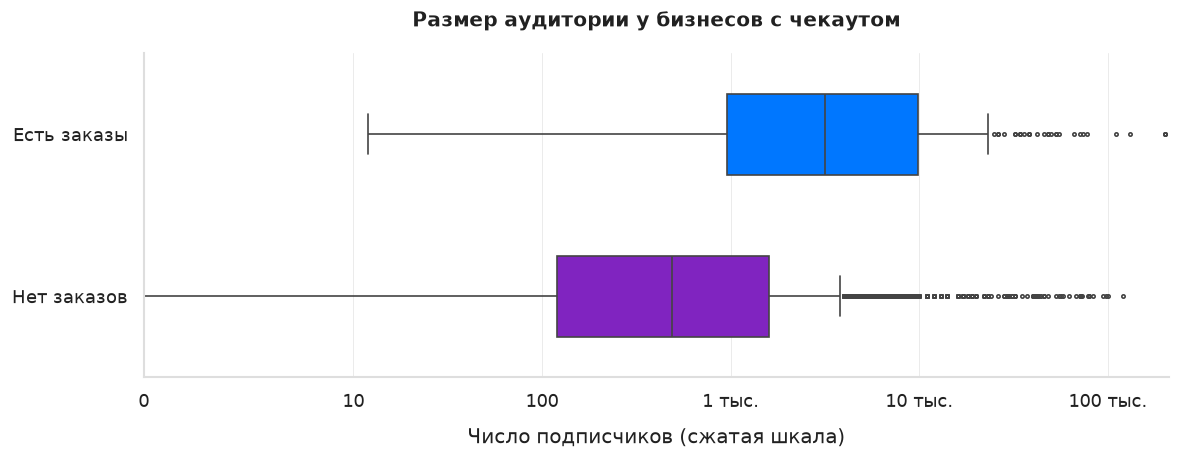

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=df_checkout, x="Число подписчиков", y="Группа заказов",
            order=["Есть заказы", "Нет заказов"], hue="Группа заказов",
            palette={"Есть заказы": PRIMARY_COLOR, "Нет заказов": SECONDARY_COLOR},
            legend=False, saturation=1, width=.5, fliersize=2, linewidth=1, ax=ax)
ax.set_xscale("symlog", linthresh=10)
ax.set_xlim(left=0)
ax.set_xticks([0, 10, 100, 1000, 10000, 100000], ["0", "10", "100", "1 тыс.", "10 тыс.", "100 тыс."])
ax.set(title="Размер аудитории у бизнесов с чекаутом", xlabel="Число подписчиков (сжатая шкала)", ylabel="")
plt.tight_layout()
plt.show()

**Численность групп разная, поэтому сравниваем распределения, а не суммарное число подписчиков.**

**Вывод:** у бизнесов с заказами медиана аудитории — **3 150 подписчиков**, без заказов — **490**. Центральная половина продающих бизнесов имеет от 957,50 до 9 800 подписчиков; у бизнесов без заказов этот диапазон — от 120 до 1 600.

**Что это означает:** группы различаются по размеру аудитории. Поэтому, сравнивая дальше контент и другие признаки, нужно учитывать число подписчиков: иначе преимущество большой аудитории можно ошибочно приписать другому признаку.

В группе без заказов также есть выбросы в сторону большой аудитории: даже сообщества с большим числом подписчиков могут не получать заказы через чекаут. **Большая аудитория не гарантирует наличие заказов.**

**Переход к следующему шагу:** У бизнесов с заказами аудитория обычно больше. А как меняется доля бизнесов с заказами среди небольших, средних и крупных сообществ?

### Шаг 3. Доля бизнесов с заказами при разном размере аудитории

**Вопрос:** Как меняется доля бизнесов с заказами среди сообществ разного размера?

**Выборка: только бизнесы с подключённым чекаутом — как с заказами, так и без них.**

Для обзора условно разделяем сообщества на три группы по размеру аудитории:

- **Малая аудитория** — до 1 000 подписчиков.
- **Средняя аудитория** — от 1 000 до 9 999 подписчиков.
- **Большая аудитория** — от 10 000 подписчиков.

Эти границы выбраны для удобства анализа и не являются универсальной классификацией бизнеса.

**В каждой группе делим число бизнесов с заказами на общее число бизнесов этой группы**, а не сравниваем абсолютное число продавцов.

In [6]:
df_checkout["Размер аудитории"] = pd.cut(
    df_checkout["Число подписчиков"], bins=[0, 1000, 10000, float("inf")], right=False,
    labels=["До 1 000", "1 000–9 999", "От 10 000"])
df_checkout["Есть заказы"] = df_checkout["Заказы через чекаут"].gt(0)
audience_orders = df_checkout.groupby("Размер аудитории", observed=False).agg(**{
    "Бизнесов": ("ID бизнеса", "size"),
    "С заказами": ("Есть заказы", "sum"),
})
audience_orders["Доля с заказами, %"] = audience_orders["С заказами"] / audience_orders["Бизнесов"] * 100
display(audience_orders.round(2))

,Бизнесов,С заказами,"Доля с заказами, %"
Размер аудитории,,,
До 1 000,3628,73,2.01
1 000–9 999,1855,141,7.60
От 10 000,254,70,27.56


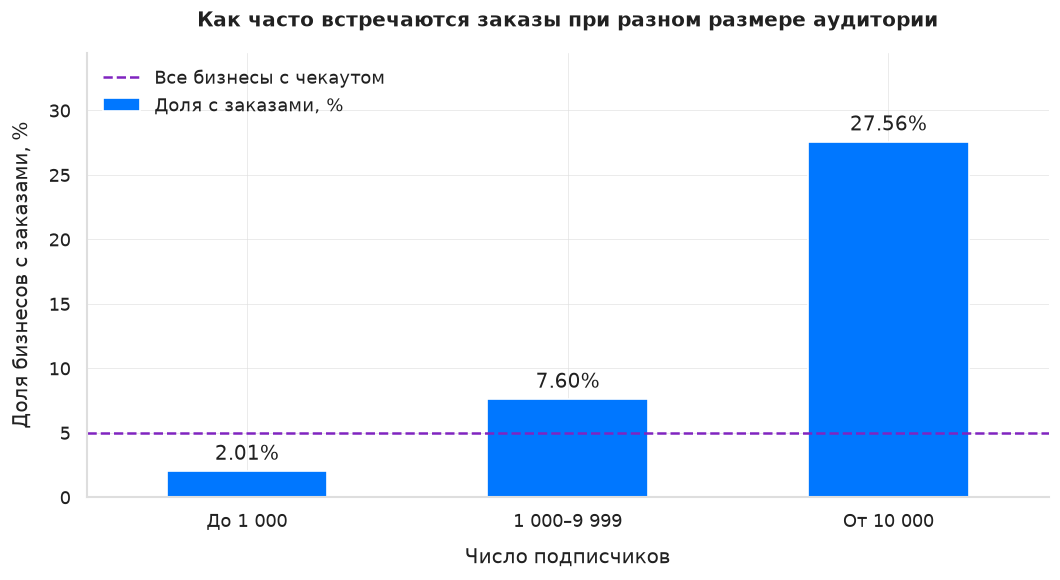

In [7]:
ax = audience_orders["Доля с заказами, %"].plot.bar(
    figsize=(9, 5), color="#0077FF", rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.axhline(df_checkout["Есть заказы"].mean() * 100, color="#8024C0", linestyle="--", label="Все бизнесы с чекаутом")
ax.set(title="Как часто встречаются заказы при разном размере аудитории",
       xlabel="Число подписчиков", ylabel="Доля бизнесов с заказами, %")
ax.set_ylim(0, audience_orders["Доля с заказами, %"].max() * 1.25)
ax.legend()
plt.tight_layout()
plt.show()

**Выводы:** среди бизнесов с подключённым чекаутом доля с заказами выше в группах с большей аудиторией: **2,01%** — до 1 000 подписчиков, **7,60%** — от 1 000 до 9 999, **27,56%** — от 10 000. В группе от 10 000 подписчиков заказы встречаются чаще, чем в целом среди бизнесов с чекаутом (**4,95%**).

**Что это означает:** в данных наблюдается связь размера аудитории с наличием заказов. Поэтому при дальнейшем сравнении контента и других признаков учитываем число подписчиков: иначе различия, связанные с аудиторией, можно ошибочно приписать другому признаку.

**Переход к следующему шагу:** В группах с большей аудиторией заказы встречаются чаще. Поэтому дальше сравниваем бизнесы внутри групп по размеру аудитории: отличается ли публикационная активность у бизнесов с заказами и без них?

### Шаг 4. Публикационная активность при похожем размере аудитории

**Вопрос:** Публикуют ли бизнесы с заказами больше постов и клипов, чем бизнесы без заказов, внутри групп по размеру аудитории?

**Выборка: только бизнесы с подключённым чекаутом — как с заказами, так и без них.**

Считаем все новые публикации за месяц: обычные и товарные посты и клипы. По описанию данных эти категории не пересекаются. Нули сохраняем. В таблице — число бизнесов, медиана, 25-й и 75-й процентили публикаций и доля бизнесов хотя бы с одной публикацией.

In [8]:
publication_columns = ["Посты за 30 дней", "Клипы за 30 дней",
                       "Посты с товаром за 30 дней", "Клипы с товаром за 30 дней"]
df_checkout["Публикаций за месяц"] = df_checkout[publication_columns].sum(axis=1)
publication_summary = df_checkout.groupby(["Размер аудитории", "Группа заказов"], observed=True).agg(**{
    "Бизнесов": ("ID бизнеса", "size"),
    "25-й процентиль публикаций": ("Публикаций за месяц", lambda x: x.quantile(.25)),
    "Медиана публикаций": ("Публикаций за месяц", "median"),
    "75-й процентиль публикаций": ("Публикаций за месяц", lambda x: x.quantile(.75)),
    "Публикуют, %": ("Публикаций за месяц", lambda x: x.gt(0).mean() * 100),
})
display(publication_summary.round(2))

Бизнесов  25-й процентиль публикаций  \
Размер аудитории Группа заказов                                         
До 1 000         Есть заказы           73                         1.0   
                 Нет заказов         3555                         0.0   
1 000–9 999      Есть заказы          141                         2.0   
                 Нет заказов         1714                         1.0   
От 10 000        Есть заказы           70                         9.0   
                 Нет заказов          184                         4.0   

                                 Медиана публикаций  \
Размер аудитории Группа заказов                       
До 1 000         Есть заказы                    3.0   
                 Нет заказов                    2.0   
1 000–9 999      Есть заказы                    8.0   
                 Нет заказов                    6.0   
От 10 000        Есть заказы                   31.0   
                 Нет заказов                   18.0   

                                 75-й процентиль публикаций  Публикуют, %  
Размер аудитории Группа заказов                                            
До 1 000         Есть заказы                          10.00         76.71  
                 Нет заказов                           8.00         73.61  
1 000–9 999      Есть заказы                          23.00         85.82  
                 Нет заказов                          16.00         76.66  
От 10 000        Есть заказы                          93.25         92.86  
                 Нет заказов                          53.00         87.50

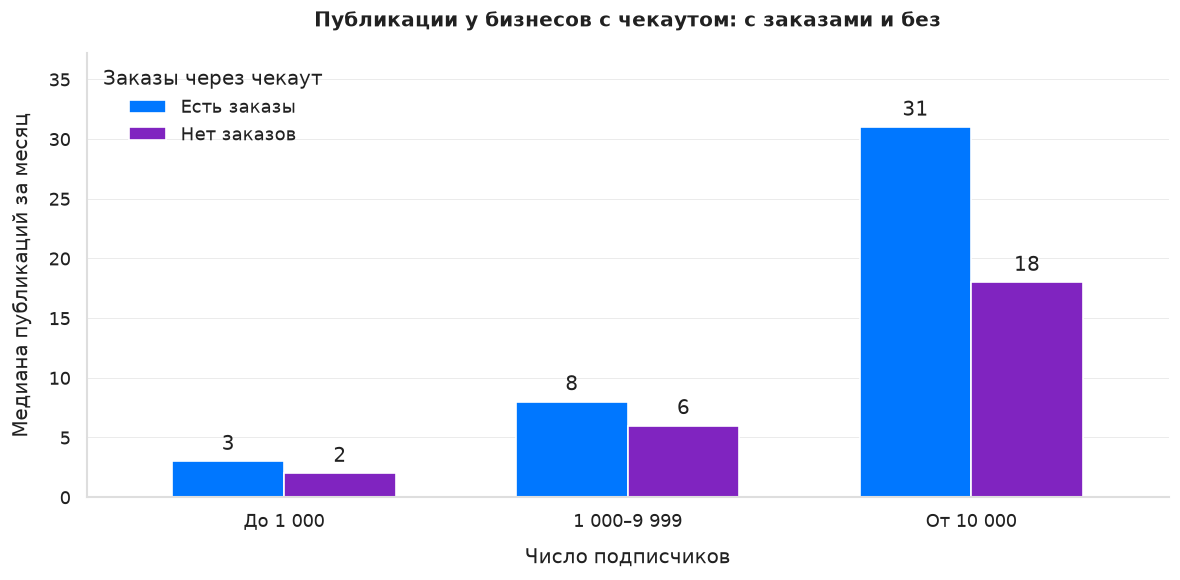

In [9]:
publication_medians = publication_summary["Медиана публикаций"].unstack("Группа заказов")
ax = publication_medians[["Есть заказы", "Нет заказов"]].plot.bar(
    figsize=(10, 5), rot=0, color=[PRIMARY_COLOR, SECONDARY_COLOR], width=.65)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f", padding=4)
ax.set(title="Публикации у бизнесов с чекаутом: с заказами и без",
       xlabel="Число подписчиков", ylabel="Медиана публикаций за месяц")
ax.set_ylim(0, publication_medians.max().max() * 1.2)
ax.legend(title="Заказы через чекаут")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Выводы:** во всех трёх группах по размеру аудитории бизнесы с заказами имеют более высокую медиану публикаций за месяц, чем бизнесы без заказов. У сообществ с малой аудиторией — **3 против 2 публикаций**, со средней — **8 против 6**, с большой — **31 против 18**.

**В группах с большей аудиторией выше доля бизнесов, опубликовавших хотя бы один пост или клип за месяц.** Среди бизнесов с заказами она составляет **76,71%** при малой аудитории, **85,82%** при средней и **92,86%** при большой. Среди бизнесов без заказов — **73,61%, 76,66% и 87,50%** соответственно. Это доля бизнесов с публикациями за месяц, а не частота публикаций.

**Что это означает:** например, берём только сообщества со средней аудиторией. У бизнесов с заказами медиана — 8 публикаций за месяц, без заказов — 6. Такое же направление различий видим среди малых и больших сообществ: **бизнесы с заказами обычно публикуют больше**. Поэтому дальше разберёмся, какие именно публикации дают это различие — обычные или товарные. Пока это наблюдение: оно не означает, что увеличение числа публикаций само по себе приведёт к заказам.

**Переход к следующему шагу:** Общая активность объединяет разные виды контента. Чем группы различаются отдельно по обычным и товарным публикациям?

### Шаг 5. Обычные и товарные публикации

**Вопрос:** Чем различаются группы по обычным и товарным публикациям?

Среди бизнесов с чекаутом сравниваем тех, у кого есть заказы, и тех, у кого их нет, отдельно в каждой группе по размеру аудитории. Публикации за месяц разделяем на **обычные посты и клипы** и **посты и клипы с товаром**.

Для каждого вида контента считаем медианное число публикаций. Но товарные публикации есть у небольшой части бизнесов, поэтому их медиана может быть нулевой и у бизнесов с заказами, и без них. Чтобы увидеть различия, дополнительно считаем **сколько бизнесов и какая их доля опубликовали хотя бы один пост или клип с товаром за месяц**.

In [10]:
df_checkout["Обычные публикации"] = df_checkout["Посты за 30 дней"] + df_checkout["Клипы за 30 дней"]
df_checkout["Товарные публикации"] = df_checkout["Посты с товаром за 30 дней"] + df_checkout["Клипы с товаром за 30 дней"]
format_summary = df_checkout.groupby(["Размер аудитории", "Группа заказов"], observed=True).agg(**{
    "Бизнесов": ("ID бизнеса", "size"),
    "Обычные публикации, медиана": ("Обычные публикации", "median"),
    "Товарные публикации, медиана": ("Товарные публикации", "median"),
    "Публикуют товарный контент": ("Товарные публикации", lambda x: x.gt(0).sum()),
})
format_summary["Публикуют товарный контент, %"] = format_summary["Публикуют товарный контент"] / format_summary["Бизнесов"] * 100
display(format_summary.round(2))

Бизнесов  Обычные публикации, медиана  \
Размер аудитории Группа заказов                                          
До 1 000         Есть заказы           73                          3.0   
                 Нет заказов         3555                          2.0   
1 000–9 999      Есть заказы          141                          8.0   
                 Нет заказов         1714                          5.0   
От 10 000        Есть заказы           70                         27.5   
                 Нет заказов          184                         18.0   

                                 Товарные публикации, медиана  \
Размер аудитории Группа заказов                                 
До 1 000         Есть заказы                              0.0   
                 Нет заказов                              0.0   
1 000–9 999      Есть заказы                              0.0   
                 Нет заказов                              0.0   
От 10 000        Есть заказы                              0.0   
                 Нет заказов                              0.0   

                                 Публикуют товарный контент  \
Размер аудитории Группа заказов                               
До 1 000         Есть заказы                              9   
                 Нет заказов                            102   
1 000–9 999      Есть заказы                             18   
                 Нет заказов                             72   
От 10 000        Есть заказы                             15   
                 Нет заказов                             12   

                                 Публикуют товарный контент, %  
Размер аудитории Группа заказов                                 
До 1 000         Есть заказы                             12.33  
                 Нет заказов                              2.87  
1 000–9 999      Есть заказы                             12.77  
                 Нет заказов                              4.20  
От 10 000        Есть заказы                             21.43  
                 Нет заказов                              6.52

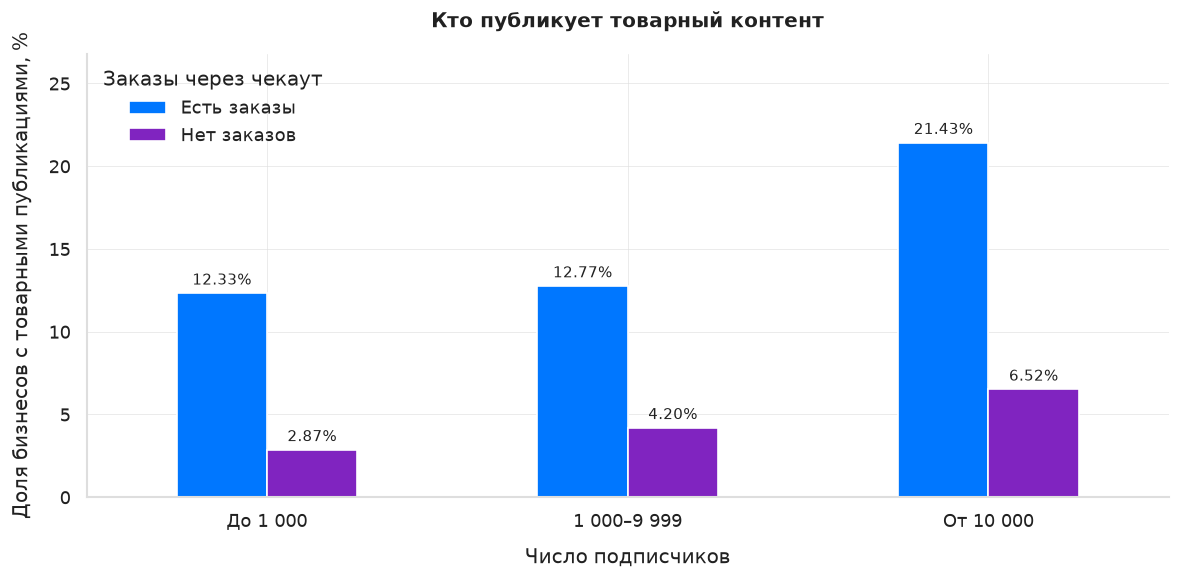

In [11]:
format_rates = format_summary["Публикуют товарный контент, %"].unstack("Группа заказов")
ax = format_rates[["Есть заказы", "Нет заказов"]].plot.bar(
    figsize=(10, 5), rot=0, color=["#0077FF", "#8024C0"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=9)
ax.set(title="Кто публикует товарный контент", xlabel="Число подписчиков",
       ylabel="Доля бизнесов с товарными публикациями, %")
ax.set_ylim(0, format_rates.max().max() * 1.25)
ax.legend(title="Заказы через чекаут")
plt.tight_layout()
plt.show()

**Выводы:**

- **Большинство бизнесов не публиковало новый товарный контент за месяц.** Медиана товарных публикаций равна нулю во всех группах. По долям публикующих видно, что хотя бы одну товарную публикацию сделали лишь 2,87–21,43% бизнесов в зависимости от группы.
- **Самая высокая медиана обычных публикаций — у крупных сообществ с заказами: 27,5 за месяц.** Среди крупных сообществ без заказов она составляет 18. У бизнесов с заказами медиана обычных публикаций выше и в двух остальных группах по аудитории.
- **Среди бизнесов с заказами выше доля тех, кто публиковал товарный контент.** При малой аудитории — 12,33% с заказами и 2,87% без заказов; при средней — 12,77% и 4,20%; при большой — 21,43% и 6,52%. Это доля бизнесов хотя бы с одной товарной публикацией, а не доля товарных постов и не число публикаций.

**Что это означает:** у бизнесов с заказами больше обычных публикаций, и среди них выше доля тех, кто размещал хотя бы одну товарную публикацию за месяц. Это наблюдаем отдельно среди сообществ с малой, средней и большой аудиторией.

**Пока мы видим различия между бизнесами, но не знаем, появились ли заказы благодаря публикациям.** Следующий шаг — посмотреть, сколько просмотров получает обычный и товарный контент: само наличие публикации ещё не означает, что её увидели.

**Переход к следующему шагу:** Число публикаций ещё не показывает, сколько внимания получает контент. Как различаются просмотры обычного и товарного контента?

### Шаг 6. Просмотры обычного и товарного контента

**Вопрос:** Как различаются просмотры обычного и товарного контента у одного и того же бизнеса?

Продолжаем исследовать бизнесы с чекаутом. Сначала отдельно учитываем отсутствие товарных просмотров. Затем сравниваем пары положительных значений — обычные и товарные просмотры одного сообщества. Это условная группа, а не вся выборка.

**Просмотры не равны уникальному охвату.** Они учитывают старый контент, поэтому не делим их на число новых публикаций. Различия суммарных просмотров могут быть связаны с количеством и возрастом публикаций, а не только с их качеством.

In [12]:
ORDINARY_VIEWS = "Просмотры обычного контента"
PRODUCT_VIEWS = "Просмотры товарного контента"
view_presence = df_checkout.assign(
    Обычные=df_checkout[ORDINARY_VIEWS].gt(0), Товарные=df_checkout[PRODUCT_VIEWS].gt(0),
).groupby(["Обычные", "Товарные"]).size().rename("Бизнесов").to_frame()
view_presence["Доля бизнесов с чекаутом, %"] = view_presence["Бизнесов"] / len(df_checkout) * 100
view_presence = view_presence.rename(index={True: "Есть просмотры", False: "Нет просмотров"})
view_presence.index.names = ["Обычный контент", "Товарный контент"]
display(view_presence.round(2))

Бизнесов  Доля бизнесов с чекаутом, %
Обычный контент Товарный контент                                       
Нет просмотров  Нет просмотров          86                         1.50
                Есть просмотры           2                         0.03
Есть просмотры  Нет просмотров        4563                        79.54
                Есть просмотры        1086                        18.93

**Вывод:** у **79,54% бизнесов с чекаутом (4 563)** есть просмотры обычного контента, но нет товарных просмотров. Таким образом, у большинства бизнесов внимание к обычному контенту не сопровождается просмотрами товарного.

В следующей таблице остаются только бизнесы с просмотрами обоих видов контента. Для каждого бизнеса считаем отношение товарных просмотров к обычным, затем берём медиану внутри группы. **100% означает одинаковое число просмотров, 10% — товарных просмотров в десять раз меньше.** Это отношение двух показателей, а не доля людей или заказов.

In [13]:
paired_views = df_checkout.loc[df_checkout[ORDINARY_VIEWS].gt(0) & df_checkout[PRODUCT_VIEWS].gt(0)].copy()
paired_views["Товарные к обычным, %"] = paired_views[PRODUCT_VIEWS] / paired_views[ORDINARY_VIEWS] * 100
view_comparison = paired_views.groupby(["Размер аудитории", "Группа заказов"], observed=True).agg(**{
    "Бизнесов": ("ID бизнеса", "size"),
    "Обычные просмотры, медиана": (ORDINARY_VIEWS, "median"),
    "Товарные просмотры, медиана": (PRODUCT_VIEWS, "median"),
    "Товарные к обычным, медиана, %": ("Товарные к обычным, %", "median"),
})
display(view_comparison.round(2))

Бизнесов  Обычные просмотры, медиана  \
Размер аудитории Группа заказов                                         
До 1 000         Есть заказы           30                      2450.0   
                 Нет заказов          573                      1200.0   
1 000–9 999      Есть заказы           78                     12000.0   
                 Нет заказов          321                      6100.0   
От 10 000        Есть заказы           39                     91000.0   
                 Нет заказов           45                     66000.0   

                                 Товарные просмотры, медиана  \
Размер аудитории Группа заказов                                
До 1 000         Есть заказы                           305.0   
                 Нет заказов                            63.0   
1 000–9 999      Есть заказы                           265.0   
                 Нет заказов                            75.0   
От 10 000        Есть заказы                          1500.0   
                 Нет заказов                           130.0   

                                 Товарные к обычным, медиана, %  
Размер аудитории Группа заказов                                  
До 1 000         Есть заказы                              12.17  
                 Нет заказов                               6.91  
1 000–9 999      Есть заказы                               4.84  
                 Нет заказов                               2.20  
От 10 000        Есть заказы                               5.77  
                 Нет заказов                               0.58

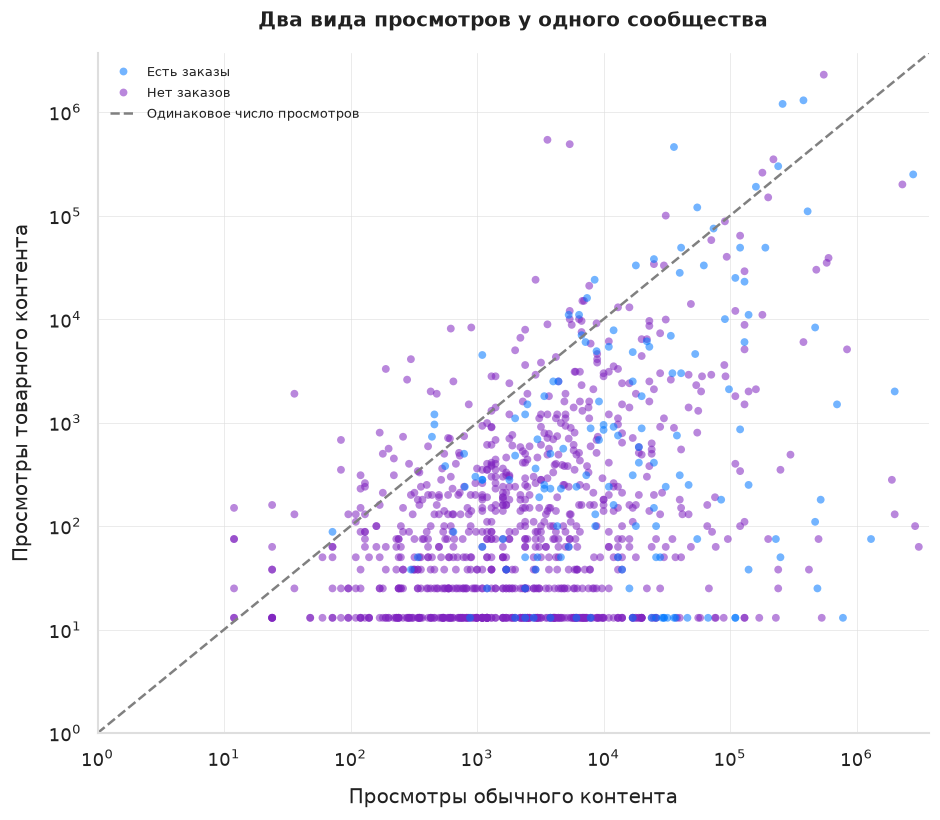

In [14]:
fig, ax = plt.subplots(figsize=(8, 7))
sns.scatterplot(data=paired_views.sort_values("Группа заказов", ascending=False),
                x=ORDINARY_VIEWS, y=PRODUCT_VIEWS, hue="Группа заказов",
                hue_order=["Есть заказы", "Нет заказов"], palette=["#0077FF", "#8024C0"],
                alpha=.55, s=22, linewidth=0, ax=ax)
upper = paired_views[[ORDINARY_VIEWS, PRODUCT_VIEWS]].max().max() * 1.2
ax.plot([1, upper], [1, upper], linestyle="--", color="gray", label="Одинаковое число просмотров")
ax.set(xscale="log", yscale="log", xlim=(1, upper), ylim=(1, upper),
       title="Два вида просмотров у одного сообщества")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Ниже пунктира товарных просмотров меньше, чем обычных; выше пунктира — больше.**

**Выводы:** на графике большинство точек находится ниже пунктирной линии. Это означает, что **у большинства показанных бизнесов товарных просмотров меньше, чем обычных**. Здесь рассматриваем только бизнесы с чекаутом, у которых есть просмотры обоих видов контента.

Медианное отношение товарных просмотров к обычным:

- **До 1 000 подписчиков:** 12,17% у бизнесов с заказами и 6,91% без заказов.
- **1 000–9 999 подписчиков:** 4,84% у бизнесов с заказами и 2,20% без заказов.
- **От 10 000 подписчиков:** 5,77% у бизнесов с заказами и 0,58% без заказов.

**Во всех группах по аудитории — как с заказами, так и без них — медианное отношение товарных просмотров к обычным ниже 100%. То есть в каждой группе товарные просмотры обычно уступают обычным; это не означает, что так у каждого бизнеса.**

**Что это означает:** обычный контент обычно получает больше просмотров, чем товарный. Но **по этим данным нельзя сказать, какой контент лучше приводит к заказам**: мы не знаем, какие публикации покупатели смотрели перед покупкой. Меньшее число товарных просмотров само по себе не означает, что товарный контент хуже помогает продавать.

Поэтому дальше проверим, чаще ли встречаются заказы у бизнесов, у которых вообще есть товарные просмотры.

**Гипотеза:** товарный контент может быть недостаточно заметным или привлекательным для покупателей, поэтому получать меньше просмотров, чем обычный.

**Что нужно для проверки:** данные о том, какие товарные публикации доступны покупателям, сколько раз и где они им показываются, как часто покупатели их открывают; для проверки привлекательности — сравнение разных вариантов контента при сопоставимых условиях показа. Это позволит отделить недостаток показов от слабого интереса к увиденному контенту.

**В текущем датасете нет необходимых данных для такой проверки.** Есть суммарные просмотры и число новых публикаций за месяц, но нет показов и действий покупателей по отдельным публикациям, а также полного объёма старого контента. Поэтому гипотеза остаётся непроверенной; товарных просмотров также может быть мало из-за отсутствия или малого объёма товарного контента.

**Переход к следующему шагу:** Мы описали просмотры двух видов контента. Чаще ли встречаются заказы у бизнесов, у которых есть товарные просмотры?

### Шаг 7. Товарные просмотры и наличие заказов

**Вопрос:** Чаще ли встречаются заказы у бизнесов с товарными просмотрами при похожем размере аудитории?

Берём всех бизнесов с чекаутом, включая сообщества без товарных просмотров. Сравниваем внутри трёх групп по аудитории. **Наличие товарных просмотров не означает, что заказы пришли именно из этого контента.** Дополнительно показываем медиану активного каталога, чтобы увидеть ещё одно возможное различие групп.

In [15]:
df_checkout["Товарные просмотры"] = df_checkout["Просмотры товарного контента"].gt(0).map({True: "Есть", False: "Нет"})
view_order_summary = df_checkout.groupby(["Размер аудитории", "Товарные просмотры"], observed=True).agg(**{
    "Бизнесов": ("ID бизнеса", "size"),
    "С заказами": ("Есть заказы", "sum"),
    "Активные товары, медиана": ("Число активных товаров в каталоге", "median"),
})
view_order_summary["Доля с заказами, %"] = view_order_summary["С заказами"] / view_order_summary["Бизнесов"] * 100
display(view_order_summary.round(2))

Бизнесов  С заказами  \
Размер аудитории Товарные просмотры                         
До 1 000         Есть                     605          30   
                 Нет                     3023          43   
1 000–9 999      Есть                     399          78   
                 Нет                     1456          63   
От 10 000        Есть                      84          39   
                 Нет                      170          31   

                                     Активные товары, медиана  \
Размер аудитории Товарные просмотры                             
До 1 000         Есть                                    15.0   
                 Нет                                      1.0   
1 000–9 999      Есть                                    24.0   
                 Нет                                      6.0   
От 10 000        Есть                                    52.0   
                 Нет                                      9.0   

                                     Доля с заказами, %  
Размер аудитории Товарные просмотры                      
До 1 000         Есть                              4.96  
                 Нет                               1.42  
1 000–9 999      Есть                             19.55  
                 Нет                               4.33  
От 10 000        Есть                             46.43  
                 Нет                              18.24

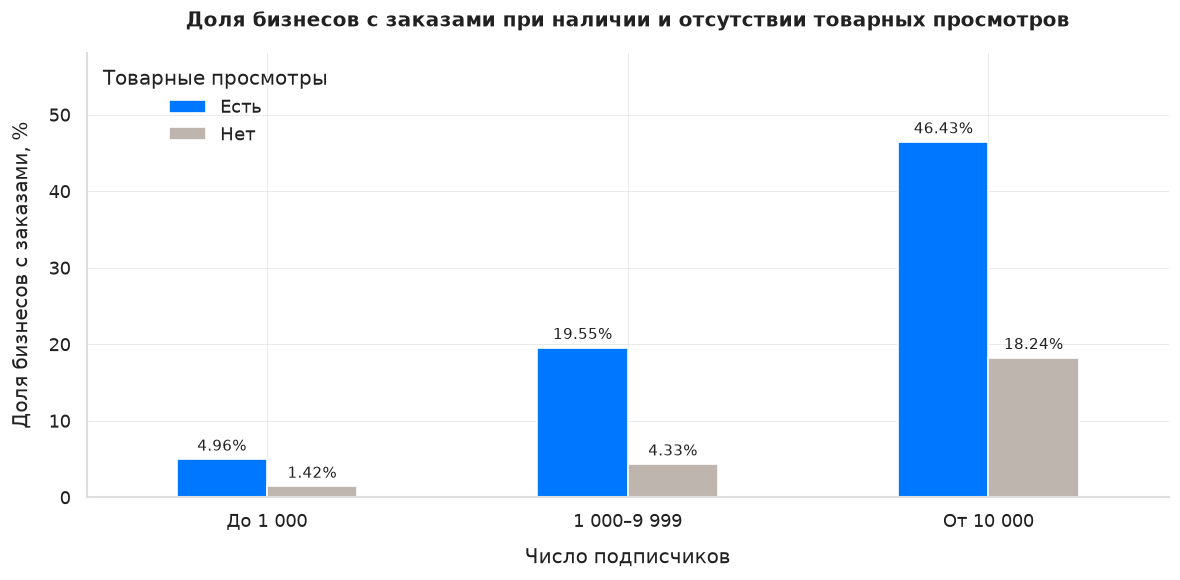

In [16]:
view_order_rates = view_order_summary["Доля с заказами, %"].unstack("Товарные просмотры")
ax = view_order_rates[["Есть", "Нет"]].plot.bar(figsize=(10, 5), rot=0, color=["#0077FF", "#BEB6AE"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=9)
ax.set(title="Доля бизнесов с заказами при наличии и отсутствии товарных просмотров",
       xlabel="Число подписчиков", ylabel="Доля бизнесов с заказами, %")
ax.set_ylim(0, view_order_rates.max().max() * 1.25)
ax.legend(title="Товарные просмотры")
plt.tight_layout()
plt.show()

**Выводы:**

- **Внутри каждой группы по аудитории у бизнесов с товарными просмотрами заказы встречаются чаще.** При малой аудитории доля бизнесов с заказами составляет 4,96% при наличии товарных просмотров и 1,42% без них; при средней — 19,55% и 4,33%; при большой — 46,43% и 18,24%.
- **В группах с большей аудиторией выше доля бизнесов с заказами.** Среди бизнесов с товарными просмотрами она растёт от 4,96% до 19,55% и 46,43%. Среди бизнесов без товарных просмотров — от 1,42% до 4,33% и 18,24%.
- **У бизнесов с товарными просмотрами также больше активных товаров в каталоге.** Медиана при малой аудитории — 15 товаров против 1 у бизнесов без товарных просмотров; при средней — 24 против 6; при большой — 52 против 9.

**Что это означает:** товарные просмотры чаще встречаются вместе с заказами, даже когда сравниваем бизнесы внутри групп по аудитории. Но эти бизнесы различаются ещё и размером каталога. Поэтому дальше сравним бизнесы с похожими аудиторией и количеством активных товаров, чтобы проверить, сохранится ли различие в доле бизнесов с заказами. Пока нельзя утверждать, что заказы появились именно благодаря товарным просмотрам.

**Переход к следующему шагу:** Связь просмотров с заказами может зависеть от ассортимента. Сохраняется ли она при похожих аудитории и размере активного каталога?

### Шаг 8. Учитываем размер активного каталога

**Вопрос:** Сохраняется ли различие в наличии заказов при учёте аудитории и размера активного каталога?

В каждой группе по аудитории дополнительно выделяем каталоги: без активных товаров, 1–10, 11–50 и от 51 товара. Например, теперь сравниваем бизнесы с аудиторией до 1 000 и каталогом 11–50 товаров между собой. Это более близкие условия, хотя внутри интервалов бизнесы всё ещё различаются.

Каждая строка — бизнесы из одной группы по числу подписчиков и размеру каталога. Внутри строки отдельно показаны бизнесы **с товарными просмотрами** и **без них**.

Например, «**51 из 135 (37,78%)**» в столбце «Есть товарные просмотры» означает: товарные просмотры есть у 135 бизнесов этой строки, из них у 51 есть заказы. То есть заказы есть у 37,78% этих бизнесов. Соседний столбец читается так же, но для бизнесов без товарных просмотров.

**«Разница, п.п.»** — доля бизнесов с заказами в столбце «Есть товарные просмотры» минус доля в столбце «Нет товарных просмотров». Например, 37,78% − 14,83% = **22,95 процентного пункта**. Положительная разница означает, что заказы чаще встречаются у бизнесов с товарными просмотрами.

In [17]:
MIN_PER_SIDE = 30
df_checkout["Размер каталога"] = pd.cut(
    df_checkout["Число активных товаров в каталоге"], bins=[0, 1, 11, 51, float("inf")], right=False,
    labels=["Нет активных товаров", "1–10", "11–50", "От 51"])
catalog_groups = df_checkout.groupby(["Размер аудитории", "Размер каталога", "Товарные просмотры"], observed=True).agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "С заказами": ("Есть заказы", "sum"),
})
catalog_groups["Доля с заказами, %"] = catalog_groups["С заказами"] / catalog_groups["Бизнесов"] * 100
catalog_table = catalog_groups.unstack("Товарные просмотры")
catalog_table[("Разница, п.п.", "")] = catalog_table[("Доля с заказами, %", "Есть")] - catalog_table[("Доля с заказами, %", "Нет")]
catalog_table[("Не менее 30 с каждой стороны", "")] = (
    catalog_table[("Бизнесов", "Есть")].ge(MIN_PER_SIDE) & catalog_table[("Бизнесов", "Нет")].ge(MIN_PER_SIDE))
catalog_readable = pd.DataFrame(index=catalog_table.index)
for status in ["Есть", "Нет"]:
    values = catalog_table.xs(status, axis=1, level="Товарные просмотры")
    catalog_readable["Есть товарные просмотры" if status == "Есть" else "Нет товарных просмотров"] = [
        f"{int(orders)} из {int(total)} ({rate:.2f}%)".replace(".", ",")
        for orders, total, rate in values[["С заказами", "Бизнесов", "Доля с заказами, %"]].itertuples(index=False, name=None)]
catalog_readable["Разница, п.п."] = catalog_table[("Разница, п.п.", "")].round(2)
catalog_readable = catalog_readable.reset_index().rename(
    columns={"Размер аудитории": "Подписчиков", "Размер каталога": "Активных товаров"})
display(catalog_readable)

,Подписчиков,Активных товаров,Есть товарные просмотры,Нет товарных просмотров,"Разница, п.п."
0,До 1 000,Нет активных товаров,"1 из 54 (1,85%)","4 из 1494 (0,27%)",1.58
1,До 1 000,1–10,"9 из 207 (4,35%)","14 из 918 (1,53%)",2.82
2,До 1 000,11–50,"9 из 227 (3,96%)","10 из 418 (2,39%)",1.57
3,До 1 000,От 51,"11 из 117 (9,40%)","15 из 193 (7,77%)",1.63
4,1 000–9 999,Нет активных товаров,"0 из 40 (0,00%)","1 из 462 (0,22%)",-0.22
5,1 000–9 999,1–10,"4 из 104 (3,85%)","8 из 463 (1,73%)",2.12
6,1 000–9 999,11–50,"23 из 120 (19,17%)","19 из 295 (6,44%)",12.73
7,1 000–9 999,От 51,"51 из 135 (37,78%)","35 из 236 (14,83%)",22.95
8,От 10 000,Нет активных товаров,"0 из 5 (0,00%)","0 из 41 (0,00%)",0.00
9,От 10 000,1–10,"2 из 11 (18,18%)","3 из 45 (6,67%)",11.52


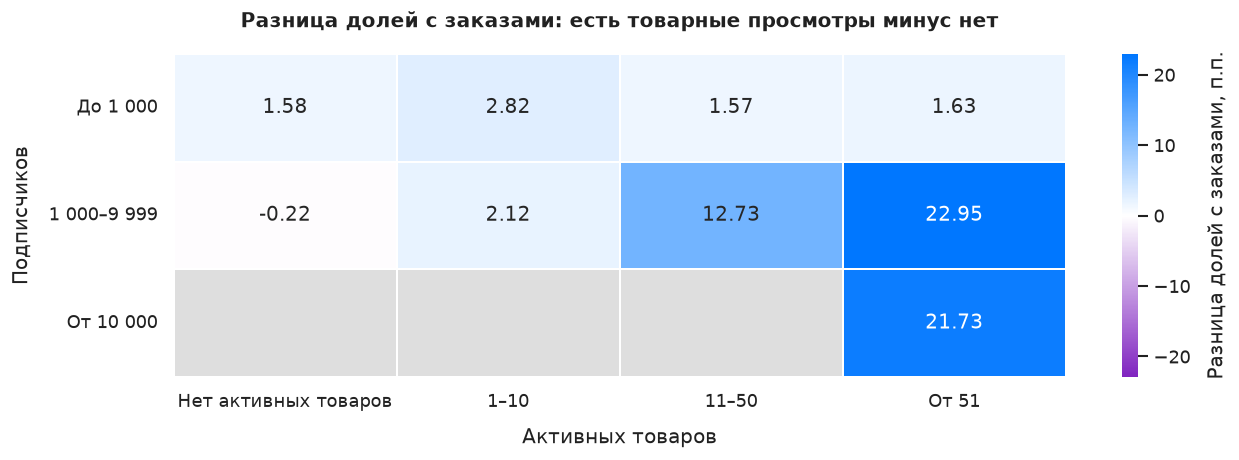

In [18]:
differences = catalog_table[("Разница, п.п.", "")].unstack("Размер каталога")
enough_data = catalog_table[("Не менее 30 с каждой стороны", "")].unstack("Размер каталога").fillna(False)
limit = differences.where(enough_data).abs().max().max()
fig, ax = plt.subplots(figsize=(11, 4))
ax.set_facecolor("#DEDEDE")
sns.heatmap(differences, mask=~enough_data, annot=True, fmt=".2f", cmap=DIVERGING_CMAP,
            center=0, vmin=-limit, vmax=limit, linewidths=1,
            cbar_kws={"label": "Разница долей с заказами, п.п."}, ax=ax)
ax.set(title="Разница долей с заказами: есть товарные просмотры минус нет",
       xlabel="Активных товаров", ylabel="Подписчиков")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

На карте цветом показаны сравнения, где есть **не менее 30 бизнесов с товарными просмотрами и 30 без них**. Серые ячейки означают, что хотя бы в одной из двух групп меньше 30 бизнесов; это не нулевая разница.

**Почему 30:** это условный порог для первого обзора, чтобы не делать основной акцент на сравнениях очень малочисленных групп. В маленькой группе даже один бизнес с заказами может заметно изменить долю. Число 30 не рассчитано по этим данным и не гарантирует статистическую надёжность: важны также число бизнесов с заказами и неопределённость разницы. Например, при 30 бизнесах один дополнительный бизнес с заказами меняет долю примерно на 3,33 процентного пункта. Группы ниже порога остаются в таблице.

**Выводы:**

- **После разделения по аудитории и каталогу у бизнесов с товарными просмотрами заказы обычно встречаются чаще.** Из 12 строк таблицы в 9 есть хотя бы по 30 бизнесов с просмотрами и без них. В 8 из этих 9 строк доля бизнесов с заказами выше при наличии товарных просмотров.
- **Самые большие положительные различия среди этих 9 строк видим у средней аудитории с каталогом от 51 товара и у большой аудитории с таким же каталогом:** 37,78% против 14,83% (**+22,95 п.п.**) и 64,29% против 42,55% (**+21,73 п.п.**) соответственно. У средней аудитории с 11–50 товарами различие также заметно: 19,17% против 6,44% (**+12,73 п.п.**). Это описательные сравнения, а не доказанная разница эффекта просмотров между группами.
- **При малой аудитории положительные различия скромнее:** для каталогов 1–10, 11–50 и от 51 товара они составляют **+2,82, +1,57 и +1,63 п.п.** соответственно.

**Отдельно про −0,22 п.п.:** это строка с аудиторией 1 000–9 999 и без активных товаров. Среди бизнесов с товарными просмотрами заказы есть у **0 из 40 (0%)**, без товарных просмотров — у **1 из 462 (0,22%)**. Поэтому разница равна 0% − 0,22% = **−0,22 п.п.**

Численно это небольшая разница, основанная всего на одном бизнесе с заказами. **Она не даёт оснований заключить, что товарные просмотры мешают продажам.** Но и отсутствие различий мы здесь не доказали: заказов слишком мало для уверенного вывода.

**Что это означает:** даже после разделения по аудитории и каталогу товарные просмотры в большинстве рассмотренных групп чаще встречаются вместе с заказами. Поэтому их стоит учитывать при выборе групп для дальнейшего анализа и стратегии. Однако **просмотры не обязательно определяют заказы**: мы не знаем, какие просмотры предшествовали покупкам, а бизнесы могут различаться рекламой, ценами и другими особенностями. Размеры групп по аудитории и каталогу также учтены лишь приблизительно, через интервалы.

**Переход к следующему шагу:** Помимо просмотров, рассмотрим характеристику самого контента. Связана ли его оригинальность с наличием заказов?

### Шаг 9. Оригинальность контента и заказы

**Вопрос:** Связана ли оценка оригинальности контента с наличием заказов?

Проверяем новый возможный признак различий. Продолжаем исследовать бизнесы с чекаутом внутри групп по аудитории. В подготовленном датасете 1 — положительная оценка оригинальности, 0 — отрицательная, 2 — отсутствие оценки. **Это оценка модели, а не доказанное свойство каждой публикации.** Бизнесы без оценки сохраняем отдельной группой.

В таблице также показываем медиану числа публикаций: оригинальность и наличие оценки могут быть связаны с активностью, которую нельзя автоматически считать эффектом оригинальности.

In [19]:
originality_order = ["Положительная", "Отрицательная", "Нет оценки"]
df_checkout["Оценка оригинальности"] = df_checkout["Автор оригинального контента (оценка модели)"].map(
    {1: "Положительная", 0: "Отрицательная", 2: "Нет оценки"})
originality_orders = df_checkout.groupby(["Размер аудитории", "Оценка оригинальности"], observed=True).agg(**{
    "Бизнесов": ("ID бизнеса", "size"),
    "С заказами": ("Есть заказы", "sum"),
    "Публикации, медиана": ("Публикаций за месяц", "median"),
})
originality_orders["Доля с заказами, %"] = originality_orders["С заказами"] / originality_orders["Бизнесов"] * 100
display(originality_orders.round(2))

Бизнесов  С заказами  \
Размер аудитории Оценка оригинальности                         
До 1 000         Нет оценки                 1013          13   
                 Отрицательная              1746          36   
                 Положительная               869          24   
1 000–9 999      Нет оценки                  410          18   
                 Отрицательная              1179          82   
                 Положительная               266          41   
От 10 000        Нет оценки                   27           5   
                 Отрицательная               123          29   
                 Положительная               104          36   

                                        Публикации, медиана  \
Размер аудитории Оценка оригинальности                        
До 1 000         Нет оценки                             0.0   
                 Отрицательная                          4.0   
                 Положительная                          6.0   
1 000–9 999      Нет оценки                             0.0   
                 Отрицательная                          9.0   
                 Положительная                         10.0   
От 10 000        Нет оценки                             0.0   
                 Отрицательная                         21.0   
                 Положительная                         32.5   

                                        Доля с заказами, %  
Размер аудитории Оценка оригинальности                      
До 1 000         Нет оценки                           1.28  
                 Отрицательная                        2.06  
                 Положительная                        2.76  
1 000–9 999      Нет оценки                           4.39  
                 Отрицательная                        6.96  
                 Положительная                       15.41  
От 10 000        Нет оценки                          18.52  
                 Отрицательная                       23.58  
                 Положительная                       34.62

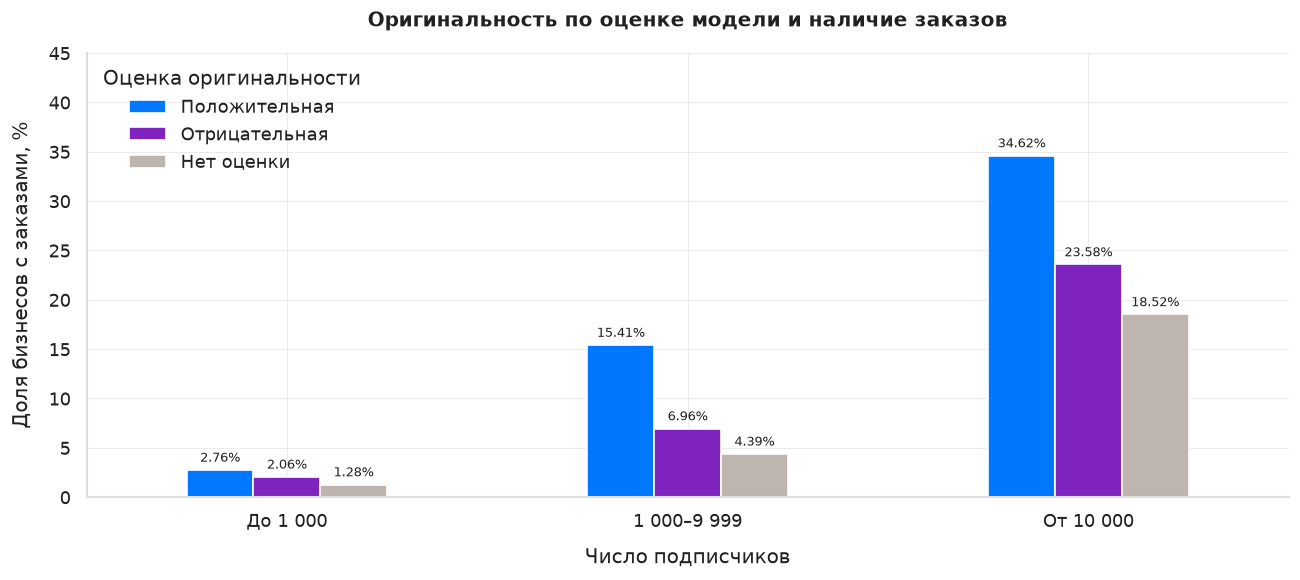

In [20]:
originality_rates = originality_orders["Доля с заказами, %"].unstack("Оценка оригинальности")
ax = originality_rates[originality_order].plot.bar(
    figsize=(11, 5), rot=0, color=["#0077FF", "#8024C0", "#BEB6AE"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=8)
ax.set(title="Оригинальность по оценке модели и наличие заказов",
       xlabel="Число подписчиков", ylabel="Доля бизнесов с заказами, %")
ax.set_ylim(0, originality_rates.max().max() * 1.3)
ax.legend(title="Оценка оригинальности")
plt.tight_layout()
plt.show()

**Выводы:**

- **При положительной оценке оригинальности доля бизнесов с заказами выше, чем при отрицательной, в каждой из трёх групп по аудитории.** При малой аудитории — 2,76% против 2,06%, при средней — 15,41% против 6,96%, при большой — 34,62% против 23,58%.
- **При положительной оценке оригинальности также выше медиана публикаций — во всех трёх группах по аудитории.** У сообществ с малой аудиторией — 6 публикаций против 4 при отрицательной оценке, со средней — 10 против 9, с большой — 32,5 против 21. То есть различие наблюдаем отдельно среди малых, средних и крупных сообществ.
- **«Нет оценки» означает отсутствие информации об оригинальности.** Эту категорию не считаем ни худшей, ни промежуточной по оригинальности и не приравниваем к отрицательной оценке.

**Что это означает:** у бизнесов с положительной оценкой оригинальности чаще есть заказы, но они также активнее публикуют контент. Оба различия видны внутри каждой группы по размеру аудитории. Поэтому дальше сравним бизнесы с похожими аудиторией и числом публикаций: сохраняется ли различие в доле бизнесов с заказами? Наличие различий во всех трёх интервалах ещё не доказывает полной независимости от точного числа подписчиков.

**Переход к следующему шагу:** Оценка оригинальности может быть связана с частотой публикаций. Сохраняется ли различие при похожей публикационной активности?

### Шаг 10. Оригинальность при похожей публикационной активности

**Вопрос:** Сохраняется ли связь оригинальности с наличием заказов при учёте публикационной активности?

В каждой группе по аудитории выделяем сообщества без новых публикаций, с 1–5, 6–15 и от 16 публикациями за месяц. Сравниваем только положительную и отрицательную оценки. **Бизнесы без оценки остаются в общей таблице, но не входят в эту проверку.** Оценка могла относиться к старому контенту, поэтому отсутствие новых публикаций не отменяет её.

В каждой строке — бизнесы с похожими аудиторией и числом публикаций. В столбцах с оценкой указано: **бизнесов с заказами из общего числа (доля с заказами)**. Например, «27 из 72 (37,50%)» — у 27 из 72 бизнесов этой группы есть заказы. **Разница, п.п.** — доля с заказами при положительной оценке минус доля при отрицательной.

In [21]:
MIN_ORIGINALITY_SIDE = 30
evaluated_checkout = df_checkout.loc[df_checkout["Оценка оригинальности"].isin(["Положительная", "Отрицательная"])].copy()
evaluated_checkout["Группа активности"] = pd.cut(
    evaluated_checkout["Публикаций за месяц"], bins=[0, 1, 6, 16, float("inf")], right=False,
    labels=["Нет новых публикаций", "1–5", "6–15", "От 16"])
originality_detail = evaluated_checkout.groupby(
    ["Размер аудитории", "Группа активности", "Оценка оригинальности"], observed=True).agg(**{
        "Бизнесов": ("ID бизнеса", "size"), "С заказами": ("Есть заказы", "sum"),
    })
originality_detail["Доля с заказами, %"] = originality_detail["С заказами"] / originality_detail["Бизнесов"] * 100
originality_control = originality_detail.unstack("Оценка оригинальности")
originality_control[("Разница, п.п.", "")] = (
    originality_control[("Доля с заказами, %", "Положительная")] - originality_control[("Доля с заказами, %", "Отрицательная")])
originality_control[("Достаточная численность", "")] = (
    originality_control[("Бизнесов", "Положительная")].ge(MIN_ORIGINALITY_SIDE)
    & originality_control[("Бизнесов", "Отрицательная")].ge(MIN_ORIGINALITY_SIDE))
originality_readable = pd.DataFrame(index=originality_control.index)
for rating in ["Положительная", "Отрицательная"]:
    values = originality_control.xs(rating, axis=1, level="Оценка оригинальности")
    originality_readable[rating + " оценка"] = [
        f"{int(orders)} из {int(total)} ({rate:.2f}%)".replace(".", ",")
        for orders, total, rate in values[["С заказами", "Бизнесов", "Доля с заказами, %"]].itertuples(index=False, name=None)]
originality_readable["Разница, п.п."] = originality_control[("Разница, п.п.", "")].round(2)
originality_readable = originality_readable.reset_index().rename(
    columns={"Размер аудитории": "Подписчиков", "Группа активности": "Публикаций за месяц"})
display(originality_readable)

,Подписчиков,Публикаций за месяц,Положительная оценка,Отрицательная оценка,"Разница, п.п."
0,До 1 000,Нет новых публикаций,"2 из 66 (3,03%)","7 из 248 (2,82%)",0.21
1,До 1 000,1–5,"10 из 364 (2,75%)","16 из 730 (2,19%)",0.56
2,До 1 000,6–15,"2 из 288 (0,69%)","8 из 502 (1,59%)",-0.90
3,До 1 000,От 16,"10 из 151 (6,62%)","5 из 266 (1,88%)",4.74
4,1 000–9 999,Нет новых публикаций,"1 из 20 (5,00%)","7 из 113 (6,19%)",-1.19
5,1 000–9 999,1–5,"11 из 68 (16,18%)","16 из 316 (5,06%)",11.11
6,1 000–9 999,6–15,"14 из 80 (17,50%)","28 из 369 (7,59%)",9.91
7,1 000–9 999,От 16,"15 из 98 (15,31%)","31 из 381 (8,14%)",7.17
8,От 10 000,Нет новых публикаций,"1 из 3 (33,33%)","1 из 6 (16,67%)",16.67
9,От 10 000,1–5,"2 из 11 (18,18%)","6 из 22 (27,27%)",-9.09


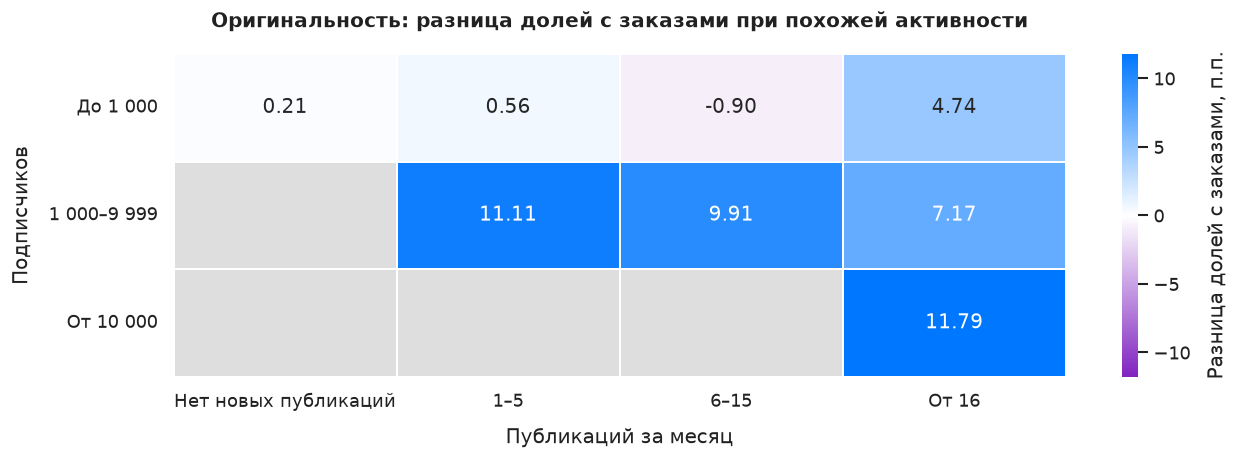

In [22]:
originality_diff = originality_control[("Разница, п.п.", "")].unstack("Группа активности")
originality_support = originality_control[("Достаточная численность", "")].unstack("Группа активности").fillna(False)
limit = originality_diff.where(originality_support).abs().max().max()
fig, ax = plt.subplots(figsize=(11, 4))
ax.set_facecolor("#DEDEDE")
sns.heatmap(originality_diff, mask=~originality_support, annot=True, fmt=".2f", cmap=DIVERGING_CMAP,
            center=0, vmin=-limit, vmax=limit, linewidths=1,
            cbar_kws={"label": "Разница долей с заказами, п.п."}, ax=ax)
ax.set(title="Оригинальность: разница долей с заказами при похожей активности",
       xlabel="Публикаций за месяц", ylabel="Подписчиков")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

**Пример:** берём сообщества с аудиторией от 10 000 подписчиков и от 16 публикациями за месяц. При положительной оценке оригинальности заказы есть у **27 из 72 бизнесов (37,50%)**, при отрицательной — у **18 из 70 (25,71%)**.

Разница **+11,79 п.п.** означает: если представить обе группы по 100 бизнесов с такими же долями, то с заказами было бы примерно **38 бизнесов при положительной оценке и 26 при отрицательной** — примерно на 12 больше. Это пересчёт наблюдаемых долей для удобства сравнения, а не прогноз прироста от изменения контента.

**Положительное значение** на карте означает более высокую долю бизнесов с заказами при положительной оценке оригинальности. **Отрицательное** — более низкую. Серые ячейки — меньше 30 бизнесов хотя бы в одной из двух групп; порог условный и не гарантирует надёжность сравнения.

**Выводы:** сравниваем бизнесы с похожим числом подписчиков и публикаций за месяц. **В большинстве таких групп при положительной оценке оригинальности заказы встречаются чаще, чем при отрицательной.** Среди 8 групп, где есть хотя бы 30 бизнесов с каждой оценкой, это наблюдаем в 7.

Например, у сообществ с аудиторией от 10 000 и от 16 публикациями за месяц доля бизнесов с заказами составляет **37,50% при положительной оценке против 25,71% при отрицательной**. Разница — **+11,79 п.п.**

Есть исключение: при аудитории до 1 000 и 6–15 публикациях доля с заказами ниже при положительной оценке — **0,69% против 1,59%**, разница **−0,90 п.п.** Здесь заказы есть у 2 из 288 бизнесов с положительной оценкой и у 8 из 502 с отрицательной. Поэтому не утверждаем, что положительная оценка всегда сопровождается большей долей бизнесов с заказами.

**Что это означает:** в предыдущем шаге бизнесы с положительной оценкой не только чаще имели заказы, но и больше публиковали. Теперь мы сравнили бизнесы, которые публикуют примерно одинаковое количество контента, и в большинстве групп различие по оригинальности осталось. **Значит, оригинальность стоит учитывать дальше как ещё один признак, по которому различаются бизнесы с заказами и без них.**

Количество публикаций в этом шаге используем для более сопоставимого сравнения. Плюс или минус в таблице показывает различие между оценками оригинальности, а не влияние числа публикаций. Мы пока не доказали, что именно оригинальность приводит к заказам.

**Переход к следующему шагу:** Мы рассмотрели оригинальность и заказы. Связана ли оригинальность также с просмотрами при похожих аудитории и активности?

### Шаг 11. Оригинальность и просмотры при похожей активности

**Вопрос:** Как связаны оригинальность и просмотры при похожих аудитории и активности?

Используем те же группы, что в предыдущем шаге. Для обычного контента сравниваем медиану просмотров, включая нули. Для товарного — число и долю бизнесов с положительными просмотрами. Оценка относится к оригинальности контента сообщества в целом, а не отдельно к товарным публикациям. **Просмотры могут приходить на старый контент; просмотры одной новой публикации здесь не оцениваем.**

#### Обычный контент

В столбцах с оценками — **медиана обычных просмотров**. Отношение медиан показывает, во сколько раз значение при положительной оценке отличается от значения при отрицательной.

In [23]:
originality_views = evaluated_checkout.groupby(
    ["Размер аудитории", "Группа активности", "Оценка оригинальности"], observed=True).agg(**{
        "Бизнесов": ("ID бизнеса", "size"),
        "Обычные просмотры, медиана": ("Просмотры обычного контента", "median"),
        "С товарными просмотрами": ("Просмотры товарного контента", lambda x: x.gt(0).sum()),
    })
originality_views["С товарными просмотрами, %"] = originality_views["С товарными просмотрами"] / originality_views["Бизнесов"] * 100
view_effects = originality_views.unstack("Оценка оригинальности")
view_effects[("Отношение обычных просмотров", "")] = (
    view_effects[("Обычные просмотры, медиана", "Положительная")]
    / view_effects[("Обычные просмотры, медиана", "Отрицательная")].replace(0, float("nan")))
view_effects[("Разница товарных просмотров, п.п.", "")] = (
    view_effects[("С товарными просмотрами, %", "Положительная")]
    - view_effects[("С товарными просмотрами, %", "Отрицательная")])
views_support = (view_effects[("Бизнесов", "Положительная")].ge(MIN_ORIGINALITY_SIDE)
                 & view_effects[("Бизнесов", "Отрицательная")].ge(MIN_ORIGINALITY_SIDE))
view_comparison = view_effects.loc[views_support, [("Отношение обычных просмотров", ""),
                                                 ("Разница товарных просмотров, п.п.", "")]].droplevel(1, axis=1)
ordinary_views_table = view_effects.loc[views_support, "Обычные просмотры, медиана"].reindex(
    columns=["Положительная", "Отрицательная"]).rename(
    columns={"Положительная": "Положительная оценка", "Отрицательная": "Отрицательная оценка"})
ordinary_views_table["Отношение медиан"] = view_comparison["Отношение обычных просмотров"]
ordinary_views_table = ordinary_views_table.rename_axis(columns=None).reset_index().rename(
    columns={"Размер аудитории": "Подписчиков", "Группа активности": "Публикаций за месяц"})
display(ordinary_views_table.round(2))

,Подписчиков,Публикаций за месяц,Положительная оценка,Отрицательная оценка,Отношение медиан
0,До 1 000,Нет новых публикаций,240.0,405.0,0.59
1,До 1 000,1–5,620.0,770.0,0.81
2,До 1 000,6–15,1950.0,2100.0,0.93
3,До 1 000,От 16,4900.0,4900.0,1.00
4,1 000–9 999,1–5,2450.0,3100.0,0.79
5,1 000–9 999,6–15,8300.0,8500.0,0.98
6,1 000–9 999,От 16,18000.0,22000.0,0.82
7,От 10 000,От 16,235000.0,105000.0,2.24


**Вывод по обычному контенту:** положительная оценка оригинальности не всегда сопровождается большим числом просмотров. В нашей таблице **только в одной группе** медиана просмотров выше при положительной оценке; в остальных она ниже или такая же, как при отрицательной.

При этом среди малых и средних сообществ **те группы, которые больше публикуют, обычно получают больше обычных просмотров** — при обеих оценках оригинальности. То есть здесь видим различия по активности, а общего преимущества оригинального контента по просмотрам не наблюдаем.

#### Товарный контент

В столбцах с оценками — **сколько бизнесов имеют товарные просмотры из общего числа (их доля)**. Разница в процентных пунктах рассчитана как доля при положительной оценке минус доля при отрицательной.

In [24]:
product_views_table = pd.DataFrame(index=view_comparison.index)
for rating in ["Положительная", "Отрицательная"]:
    values = originality_views.xs(rating, level="Оценка оригинальности").reindex(product_views_table.index)
    product_views_table[rating + " оценка"] = [
        f"{int(viewed)} из {int(total)} ({rate:.2f}%)".replace(".", ",")
        for viewed, total, rate in values[["С товарными просмотрами", "Бизнесов", "С товарными просмотрами, %"]].itertuples(index=False, name=None)]
product_views_table["Разница, п.п."] = view_comparison["Разница товарных просмотров, п.п."].round(2)
product_views_table = product_views_table.reset_index().rename(
    columns={"Размер аудитории": "Подписчиков", "Группа активности": "Публикаций за месяц"})
display(product_views_table)

,Подписчиков,Публикаций за месяц,Положительная оценка,Отрицательная оценка,"Разница, п.п."
0,До 1 000,Нет новых публикаций,"19 из 66 (28,79%)","46 из 248 (18,55%)",10.24
1,До 1 000,1–5,"91 из 364 (25,00%)","104 из 730 (14,25%)",10.75
2,До 1 000,6–15,"69 из 288 (23,96%)","87 из 502 (17,33%)",6.63
3,До 1 000,От 16,"51 из 151 (33,77%)","44 из 266 (16,54%)",17.23
4,1 000–9 999,1–5,"28 из 68 (41,18%)","66 из 316 (20,89%)",20.29
5,1 000–9 999,6–15,"36 из 80 (45,00%)","78 из 369 (21,14%)",23.86
6,1 000–9 999,От 16,"44 из 98 (44,90%)","89 из 381 (23,36%)",21.54
7,От 10 000,От 16,"29 из 72 (40,28%)","20 из 70 (28,57%)",11.71


**Вывод по товарному контенту:** во всех 8 показанных группах **при положительной оценке оригинальности выше доля бизнесов, у которых есть товарные просмотры**. Разница составляет от **6,63 до 23,86 п.п.** — она сохраняется при сравнении бизнесов с похожими аудиторией и числом публикаций.

Например, среди сообществ с 1 000–9 999 подписчиками и 6–15 публикациями за месяц товарные просмотры есть у **45,00% бизнесов с положительной оценкой и у 21,14% с отрицательной**. Разница — **23,86 п.п.**

**Результат отличается от обычного контента:** общего преимущества положительной оценки по медиане обычных просмотров мы не видели, а по наличию товарных просмотров различие есть во всех показанных группах. При этом здесь считаем наличие товарных просмотров у бизнеса, а не их количество; оригинальность оценена для контента сообщества в целом, а не отдельно для товарных публикаций. Это наблюдаемое различие, а не доказательство причинного эффекта оригинальности.

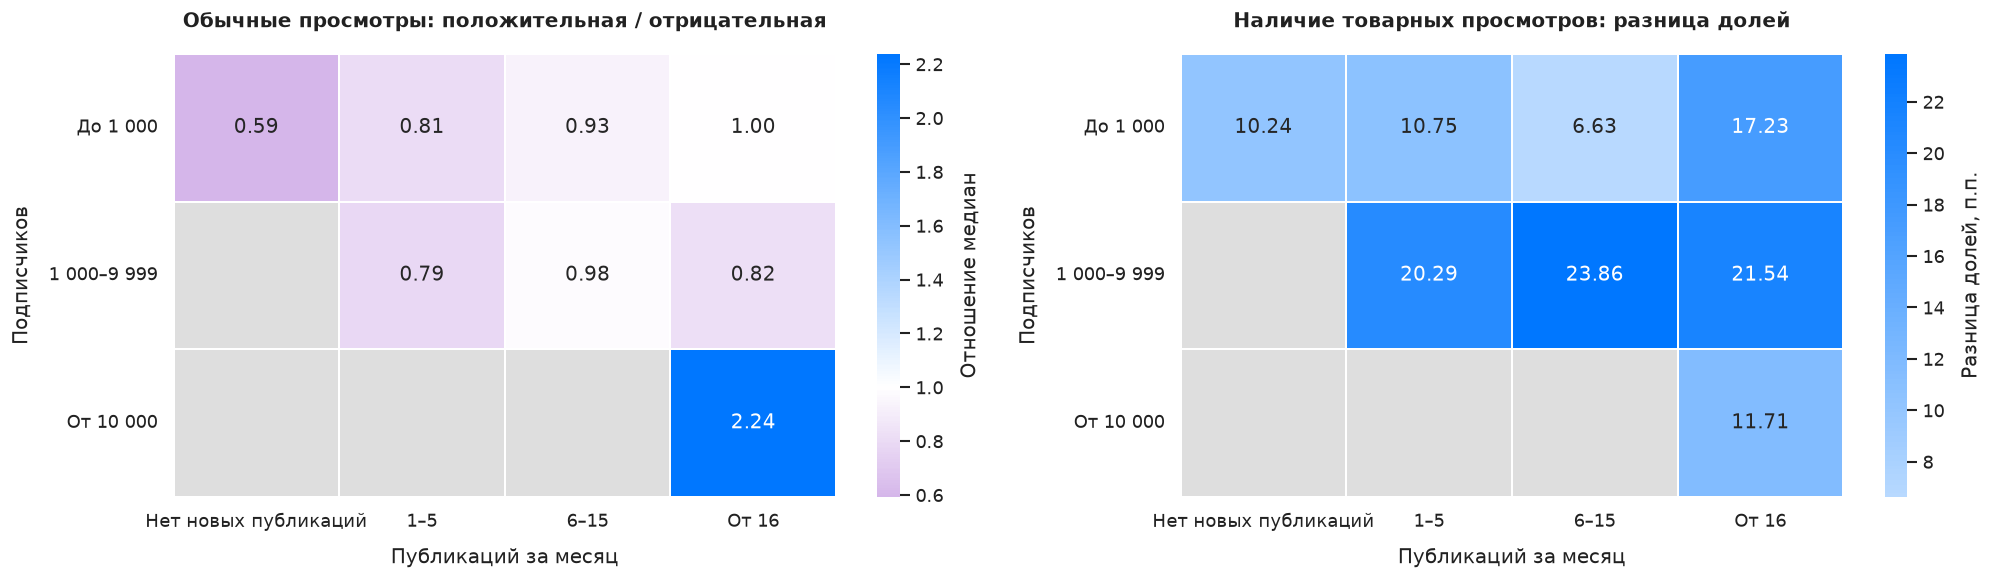

In [25]:
ordinary_ratio = view_effects[("Отношение обычных просмотров", "")].unstack("Группа активности")
product_difference = view_effects[("Разница товарных просмотров, п.п.", "")].unstack("Группа активности")
supported_views = views_support.unstack("Группа активности").fillna(False)
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax in axes:
    ax.set_facecolor("#DEDEDE")
sns.heatmap(ordinary_ratio, mask=~supported_views, annot=True, fmt=".2f", cmap=DIVERGING_CMAP, center=1,
            linewidths=1, cbar_kws={"label": "Отношение медиан"}, ax=axes[0])
sns.heatmap(product_difference, mask=~supported_views, annot=True, fmt=".2f", cmap=DIVERGING_CMAP, center=0,
            linewidths=1, cbar_kws={"label": "Разница долей, п.п."}, ax=axes[1])
for ax, title in zip(axes, ["Обычные просмотры: положительная / отрицательная", "Наличие товарных просмотров: разница долей"]):
    ax.set(title=title, xlabel="Публикаций за месяц", ylabel="Подписчиков")
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

**Слева:** отношение медиан обычных просмотров. 1 — одинаково; больше 1 — выше при положительной оценке; меньше 1 — ниже.

**Справа:** разница долей бизнесов с товарными просмотрами. Плюс — доля выше при положительной оценке, минус — ниже. Серые ячейки на обеих картах — меньше 30 бизнесов хотя бы с одной оценкой.

**Выводы:**

- **Обычный контент:** при положительной оценке оригинальности медиана просмотров не обязательно выше. Среди 8 показанных групп она выше только в одной, в шести — ниже, в одной — такая же, как при отрицательной оценке.
- **Товарный контент:** при положительной оценке оригинальности **во всех 8 группах выше доля бизнесов, у которых есть товарные просмотры**. Разница с отрицательной оценкой — от 6,63 до 23,86 п.п. Например, при аудитории 1 000–9 999 и 6–15 публикациях за месяц — 45,00% против 21,14%.

**Что это означает:** положительная оценка оригинальности не означает, что обычный контент будут смотреть больше. Но среди бизнесов с такой оценкой чаще есть просмотры товарного контента — даже при похожих аудитории и числе публикаций. **Поэтому оригинальность стоит учитывать при анализе товарного контента, а ожидать от неё большего числа обычных просмотров по этим результатам оснований нет.**

Для двух видов контента здесь использованы разные показатели: у обычного сравниваем число просмотров, у товарного — долю бизнесов, у которых просмотры вообще есть. Мы пока не доказали, что именно оригинальность вызывает эти различия.

**Переход к следующему шагу:** Мы рассмотрели публикации, просмотры и оригинальность. Но бизнесы могут отличаться ещё и рекламными расходами, которые пока отдельно не учитывали. Поэтому дальше посмотрим: как различаются наличие заказов и GMV через чекаут у бизнесов с расходами на рекламу и без них?

### Шаг 12. Рекламные расходы, заказы и GMV

**Вопрос:** Как различаются заказы и GMV у бизнесов с рекламными расходами и без них?

Продолжаем сравнивать бизнесы с чекаутом внутри групп по аудитории. Поле расходов содержит общие рекламные траты; разбивки по публикациям и каналам в данных нет. **GMV учитывает только чекаут, не является прибылью и не может автоматически считаться результатом рекламы.** Для GMV отдельно показываем общую сумму и медиану среди положительных значений.

**Ограничение данных:** мы знаем общую сумму рекламных расходов, но не знаем, что именно рекламировали, как выглядели объявления, где они размещались, кому показывались и как пользователи на них реагировали. Одинаковый бюджет может давать разные результаты в зависимости от содержания рекламы, места размещения и интереса аудитории.

**Поэтому нельзя считать, что больше расходов автоматически означает больше привлечённых покупателей или заказов.** Для проверки нужны данные по отдельным кампаниям: содержание и размещение объявлений, показы, переходы и связанные с ними заказы. В текущем датасете этих данных нет; здесь сравниваем результаты бизнесов с разными расходами, а не оцениваем качество и эффективность конкретной рекламы.

**Перед сравнением GMV проверяем нули.** Выборка — только бизнесы с подключённым чекаутом.

In [26]:
orders = df_checkout["Заказы через чекаут"]
gmv = df_checkout["GMV через чекаут, ₽"]
gmv_check = pd.DataFrame({
    "Ситуация": ["Нет заказов, GMV = 0", "Есть заказы, GMV = 0", "Есть заказы, GMV > 0"],
    "Бизнесов": [(orders.eq(0) & gmv.eq(0)).sum(),
                 (orders.gt(0) & gmv.eq(0)).sum(), (orders.gt(0) & gmv.gt(0)).sum()],
})
display(gmv_check)

,Ситуация,Бизнесов
0,"Нет заказов, GMV = 0",5453
1,"Есть заказы, GMV = 0",7
2,"Есть заказы, GMV > 0",277


**Нулевой GMV не всегда означает отсутствие данных:** у 5 453 бизнесов нет заказов через чекаут, и GMV равен нулю. У 7 бизнесов заказы есть, но GMV равен нулю и средний чек неизвестен; причину по данным определить нельзя.

Поэтому отдельно показываем медиану **среди бизнесов с GMV больше нуля**: она описывает типичный денежный объём заказов в этой группе. Это не медиана для всех бизнесов и не для всех бизнесов с заказами. Рядом указываем число бизнесов, по которым она рассчитана. Нулевые значения сохраняем в общих суммах и в проверке наличия заказов.

In [27]:
AD_SPEND = "Траты на рекламу всего, ₽"
GMV = "GMV через чекаут, ₽"
df_checkout["Реклама"] = df_checkout[AD_SPEND].gt(0).map({True: "Есть расходы", False: "Нет расходов"})
df_checkout["Положительный GMV"] = df_checkout[GMV].where(df_checkout[GMV].gt(0))
ad_results = df_checkout.groupby(["Размер аудитории", "Реклама"], observed=True).agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "С заказами": ("Есть заказы", "sum"),
    "Заказов": ("Заказы через чекаут", "sum"), "GMV, ₽": (GMV, "sum"),
    "С положительным GMV": ("Положительный GMV", "count"),
    "GMV положительных, медиана, ₽": ("Положительный GMV", "median"),
})
ad_results.insert(2, "Доля с заказами, %", ad_results["С заказами"] / ad_results["Бизнесов"] * 100)
display(ad_results.round(2))

Бизнесов  С заказами  Доля с заказами, %  \
Размер аудитории Реклама                                                  
До 1 000         Есть расходы       117           8                6.84   
                 Нет расходов      3511          65                1.85   
1 000–9 999      Есть расходы       161          14                8.70   
                 Нет расходов      1694         127                7.50   
От 10 000        Есть расходы        56          18               32.14   
                 Нет расходов       198          52               26.26   

                               Заказов   GMV, ₽  С положительным GMV  \
Размер аудитории Реклама                                               
До 1 000         Есть расходы       10    86040                    6   
                 Нет расходов      155   757460                   61   
1 000–9 999      Есть расходы       32   917540                   14   
                 Нет расходов     1407  3211823                  126   
От 10 000        Есть расходы      262  1927993                   18   
                 Нет расходов     1567  2618471                   52   

                               GMV положительных, медиана, ₽  
Размер аудитории Реклама                                      
До 1 000         Есть расходы                         4035.0  
                 Нет расходов                         4190.0  
1 000–9 999      Есть расходы                         6205.0  
                 Нет расходов                         5530.0  
От 10 000        Есть расходы                        48065.0  
                 Нет расходов                        15690.0

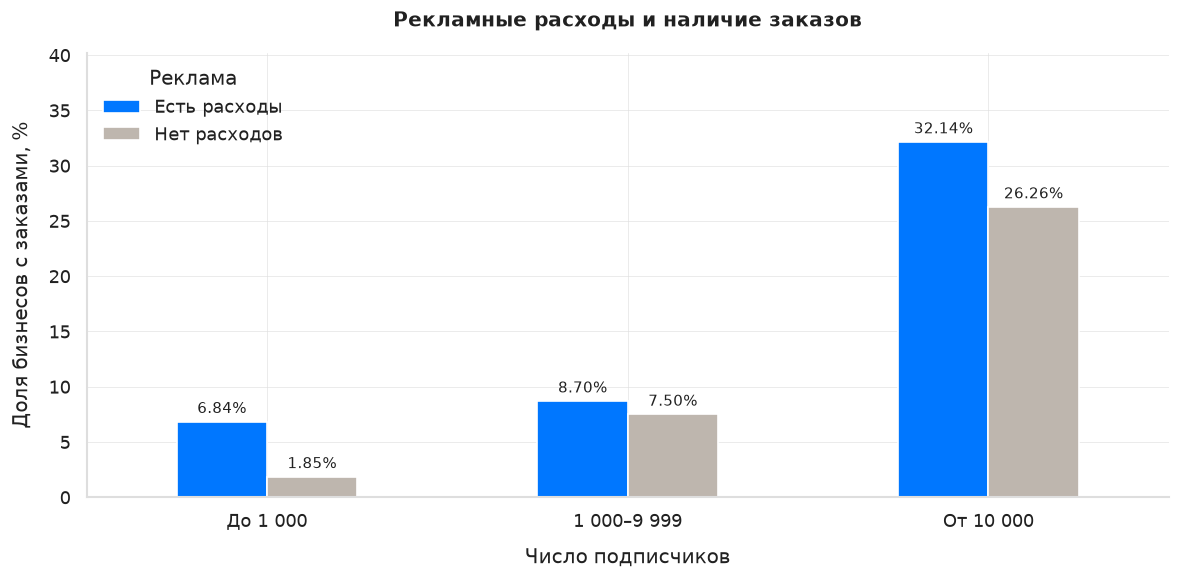

In [28]:
ad_order_rates = ad_results["Доля с заказами, %"].unstack("Реклама")
ax = ad_order_rates[["Есть расходы", "Нет расходов"]].plot.bar(
    figsize=(10, 5), rot=0, color=["#0077FF", "#BEB6AE"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", padding=3, fontsize=9)
ax.set(title="Рекламные расходы и наличие заказов", xlabel="Число подписчиков",
       ylabel="Доля бизнесов с заказами, %")
ax.set_ylim(0, ad_order_rates.max().max() * 1.25)
ax.legend(title="Реклама")
plt.tight_layout()
plt.show()

**Выводы:**

- **Во всех трёх группах по аудитории у бизнесов с рекламными расходами выше доля тех, у кого есть заказы через чекаут.**
- **Суммарные заказы и GMV напрямую не сравниваем:** бизнесов без рекламных расходов намного больше, поэтому их общие суммы могут быть выше за счёт численности. Для сравнения результатов используем доли и показатели на один бизнес; медиану положительного GMV рассматриваем только среди бизнесов с GMV больше нуля.

**Отдельно смотрим тратящих на рекламу:** сколько они расходуют и у какой части нет заказов через чекаут. Отсутствие таких заказов не доказывает неэффективность рекламы: покупки могли завершаться другими способами, а реклама могла решать другие задачи.

In [29]:
advertisers = df_checkout.loc[df_checkout[AD_SPEND].gt(0)].copy()
advertisers["Нет заказов"] = ~advertisers["Есть заказы"]
ad_spending = advertisers.groupby("Размер аудитории", observed=True).agg(**{
    "Тратят на рекламу": ("ID бизнеса", "size"),
    "Расходы, сумма, ₽": (AD_SPEND, "sum"), "Расходы, медиана, ₽": (AD_SPEND, "median"),
    "Без заказов через чекаут": ("Нет заказов", "sum"),
})
ad_spending["Без заказов через чекаут, %"] = ad_spending["Без заказов через чекаут"] / ad_spending["Тратят на рекламу"] * 100
display(ad_spending.round(2))

,Тратят на рекламу,"Расходы, сумма, ₽","Расходы, медиана, ₽",Без заказов через чекаут,"Без заказов через чекаут, %"
Размер аудитории,,,,,
До 1 000,117,5704104,21000.0,109,93.16
1 000–9 999,161,15965699,49000.0,147,91.30
От 10 000,56,39686400,210000.0,38,67.86


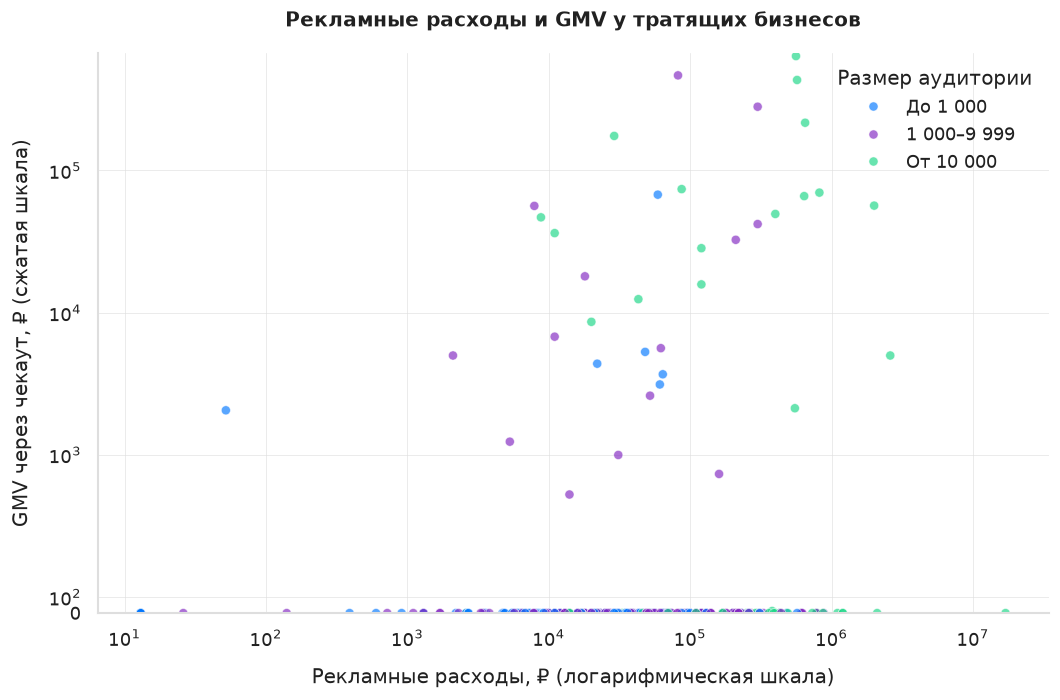

In [30]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=advertisers, x=AD_SPEND, y=GMV, hue="Размер аудитории",
                palette=CHART_PALETTE[:3], alpha=.65, s=30, ax=ax)
ax.set_xscale("log")
ax.set_yscale("symlog", linthresh=1000)
ax.set_ylim(bottom=0)
ax.set(title="Рекламные расходы и GMV у тратящих бизнесов",
       xlabel="Рекламные расходы, ₽ (логарифмическая шкала)",
       ylabel="GMV через чекаут, ₽ (сжатая шкала)")
plt.tight_layout()
plt.show()

Каждая точка — **один бизнес с рекламными расходами**. Чем правее точка, тем больше расходы; чем выше — тем больше GMV через чекаут. Цвет обозначает размер аудитории. Точки внизу — бизнесы с нулевым GMV. Оси сжаты, чтобы показать и небольшие, и очень большие суммы.

**Выводы:**

- **Среди рекламодателей в группах с большей аудиторией выше медианные расходы:** 21 000 ₽ у малых сообществ, 49 000 ₽ у средних и 210 000 ₽ у крупных.
- **У большинства рекламодателей нет заказов через чекаут:** у 93,16% малых, 91,30% средних и 67,86% крупных сообществ.
- **На графике много бизнесов с нулевым GMV при самых разных рекламных расходах, в том числе больших.** Значит, большие расходы сами по себе не гарантируют ненулевой GMV через чекаут.
- **Среди бизнесов с ненулевым GMV точки сильно разбросаны:** расходы одного порядка могут сочетаться с разным GMV. По графику нельзя уверенно сказать, какой GMV ожидать при определённом бюджете. Визуальный разброс сам по себе не доказывает отсутствия корреляции — для этого нужен отдельный расчёт.

**Что это означает:** мы не видим простой зависимости «чем больше потратили, тем больше получили GMV через чекаут». Результаты могут зависеть от содержания рекламы, размещения, выбранной аудитории, ассортимента и других особенностей бизнеса. Кроме того, реклама могла приводить к продажам в сообщениях или на сайте либо решать задачи, не связанные с непосредственным заказом.

**Поэтому нулевой GMV через чекаут не означает, что реклама бесполезна, а высокий GMV не доказывает, что его принесла реклама.** В данных нет содержания и результатов отдельных кампаний и связи конкретных заказов с рекламой, поэтому объяснения остаются предположениями.

**Гипотеза:** у малых и средних сообществ могут быть трудности с превращением привлечённого рекламой интереса в заказы через чекаут. Реклама может привлекать внимание, но покупатели не завершают покупку этим способом или оформляют её в другом канале.

**Основание для проверки:** среди тратящих на рекламу нет заказов через чекаут у 93,16% малых и 91,30% средних сообществ. Это наблюдение за период, а не вероятность того, что будущая рекламная кампания не принесёт результата.

**Что нужно для проверки:** данные по рекламным кампаниям с целью продаж, переходам, этапам оформления заказа и покупкам через чекаут, в сообщениях и на сайте. **В текущем датасете этих данных нет, поэтому гипотеза не проверена.** Отсутствие заказов через чекаут не означает отсутствия всех продаж внутри ВКонтакте.

**Переход к следующему шагу:** Наличие заказов и масштаб продаж — разные показатели. Среди уже продающих бизнесов у рекламодателей больше заказов и выше GMV?

### Шаг 13. Реклама и масштаб продаж среди продающих бизнесов

**Вопрос:** Среди бизнесов, у которых уже есть заказы, насколько различается масштаб продаж у тех, кто тратит на рекламу, и тех, кто не тратит?

**Выборка: бизнесы с подключённым чекаутом и хотя бы одним заказом за период.** Сравниваем рекламодателей и бизнесы без рекламных расходов отдельно внутри каждой группы по аудитории.

Смотрим **медиану числа заказов на бизнес** и **медиану GMV среди бизнесов с GMV больше нуля**. Так сравниваем результаты отдельных бизнесов, а не общие суммы групп разной численности. Дополнительно показываем медиану известного среднего чека.

Бизнесы с заказами и нулевым GMV остаются в расчёте числа заказов. Средний чек используем только при статусе «Чек указан». Число бизнесов для каждого расчёта указано в таблице.

In [31]:
selling_checkout = df_checkout.loc[df_checkout["Есть заказы"]].copy()
selling_checkout["Известный чек"] = selling_checkout["Средний чек, ₽"].where(selling_checkout["Статус среднего чека"].eq("Чек указан"))
selling_ad_results = selling_checkout.groupby(["Размер аудитории", "Реклама"], observed=True).agg(**{
    "Бизнесов с заказами": ("ID бизнеса", "size"),
    "Заказов на бизнес, медиана": ("Заказы через чекаут", "median"),
    "С положительным GMV": ("Положительный GMV", "count"),
    "GMV положительных, медиана, ₽": ("Положительный GMV", "median"),
    "Известных чеков": ("Известный чек", "count"),
    "Средний чек, медиана известных, ₽": ("Известный чек", "median"),
})
display(selling_ad_results.round(2))

Бизнесов с заказами  \
Размер аудитории Реклама                             
До 1 000         Есть расходы                    8   
                 Нет расходов                   65   
1 000–9 999      Есть расходы                   14   
                 Нет расходов                  127   
От 10 000        Есть расходы                   18   
                 Нет расходов                   52   

                               Заказов на бизнес, медиана  \
Размер аудитории Реклама                                    
До 1 000         Есть расходы                         1.0   
                 Нет расходов                         1.0   
1 000–9 999      Есть расходы                         1.5   
                 Нет расходов                         2.0   
От 10 000        Есть расходы                         5.5   
                 Нет расходов                         5.5   

                               С положительным GMV  \
Размер аудитории Реклама                             
До 1 000         Есть расходы                    6   
                 Нет расходов                   61   
1 000–9 999      Есть расходы                   14   
                 Нет расходов                  126   
От 10 000        Есть расходы                   18   
                 Нет расходов                   52   

                               GMV положительных, медиана, ₽  Известных чеков  \
Размер аудитории Реклама                                                        
До 1 000         Есть расходы                         4035.0                6   
                 Нет расходов                         4190.0               61   
1 000–9 999      Есть расходы                         6205.0               14   
                 Нет расходов                         5530.0              126   
От 10 000        Есть расходы                        48065.0               18   
                 Нет расходов                        15690.0               52   

                               Средний чек, медиана известных, ₽  
Размер аудитории Реклама                                          
До 1 000         Есть расходы                             2886.5  
                 Нет расходов                             1801.0  
1 000–9 999      Есть расходы                             3015.0  
                 Нет расходов                             2080.0  
От 10 000        Есть расходы                             5641.0  
                 Нет расходов                             2007.5

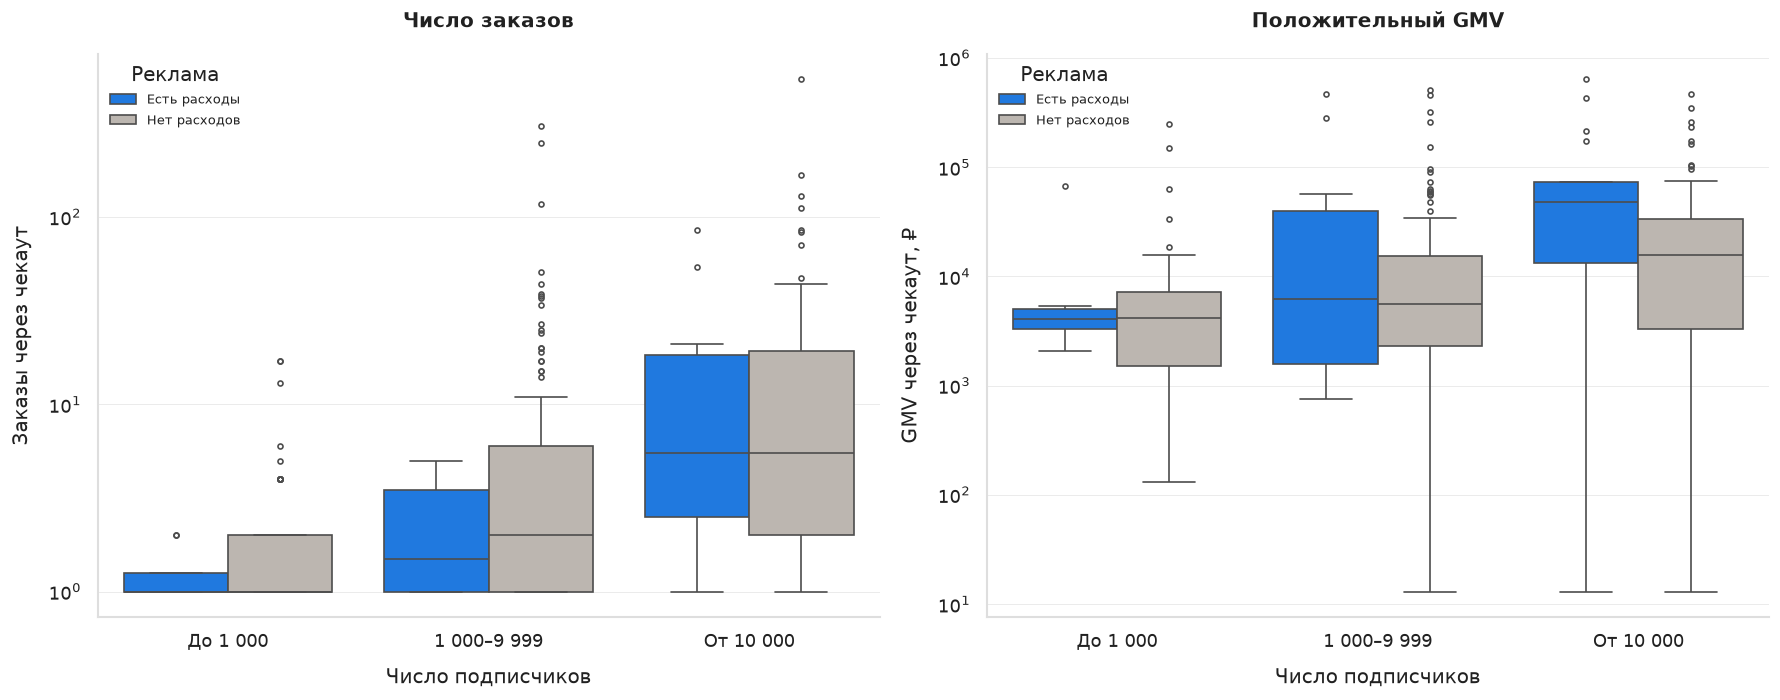

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, column, title in zip(axes, ["Заказы через чекаут", GMV], ["Число заказов", "Положительный GMV"]):
    plot_data = selling_checkout.loc[selling_checkout[column].gt(0)]
    sns.boxplot(data=plot_data, x="Размер аудитории", y=column, hue="Реклама",
                hue_order=["Есть расходы", "Нет расходов"], palette=["#0077FF", "#BEB6AE"],
                fliersize=3, ax=ax)
    ax.set_yscale("log")
    ax.set(title=title, xlabel="Число подписчиков")
    ax.legend(title="Реклама", fontsize=8)
plt.tight_layout()
plt.show()

**На обоих графиках вертикальная шкала логарифмическая:** одинаковое расстояние по ней означает увеличение значения в одинаковое число раз, а не на одинаковую величину. Это позволяет показать небольшие и большие значения вместе. На графике GMV учитываем только бизнесы с GMV больше нуля.

**Выводы:**

- **Малая аудитория:** медиана числа заказов одинакова — **1 заказ** у бизнесов с рекламными расходами и без них. Медиана положительного GMV также близка: **4 035 ₽ с рекламными расходами и 4 190 ₽ без них**. Большего масштаба продаж у рекламодателей здесь не наблюдаем.
- **Средняя аудитория:** у рекламодателей медиана числа заказов ниже — **1,5 против 2** у бизнесов без рекламных расходов. При этом медиана положительного GMV немного выше — **6 205 ₽ против 5 530 ₽**. Больший денежный объём здесь не сопровождается большим числом заказов.
- **Большая аудитория:** медиана числа заказов одинакова — **5,5 заказа**, но медиана положительного GMV у рекламодателей выше — **48 065 ₽ против 15 690 ₽**. Медиана известного среднего чека тоже выше: **5 641 ₽ против 2 007,50 ₽**. То есть главное наблюдаемое различие здесь — в денежном объёме и стоимости покупок, а не в типичном числе заказов.

**Выводы по графикам:**

- **Число заказов:** у рекламодателей не видим общего преимущества. Медианы близки или совпадают, распределения двух групп пересекаются. Бизнесы с большим числом заказов встречаются и без рекламных расходов.
- **GMV:** наиболее заметное различие — среди крупных сообществ: у рекламодателей медиана выше. Но распределения также пересекаются, а высокие значения есть в обеих группах. Поэтому преимущество не относится к каждому бизнесу.

**Что это означает:** среди бизнесов, у которых уже есть заказы, наличие рекламных расходов не сопровождается большим типичным числом заказов. При этом у крупных рекламодателей денежный объём выше и средний чек тоже выше. **Поэтому больше GMV здесь не означает больше заказов.**

Возможное объяснение — различия в стоимости и составе покупок. Но мы не установили, что дело именно в цене товара или рекламе: ассортимент, тематика и другие особенности бизнесов могут различаться. Кроме того, продающих рекламодателей немного — 8, 14 и 18 в трёх группах по аудитории, поэтому выводы не стоит распространять на всех продавцов.

**Переход к следующему шагу:** Мы рассмотрели рекламу как способ привлечения покупателей. Теперь перейдём к условиям самой покупки: посмотрим, чаще ли есть заказы у товарных бизнесов с подключённой доставкой, чем без неё, при похожих аудитории и размере каталога.

### Шаг 14. Доставка и наличие заказов

**Вопрос:** Чаще ли есть заказы у бизнесов с доставкой при похожих аудитории и каталоге?

Берём бизнесы с чекаутом и хотя бы одним активным товаром. Сравниваем внутри уже заданных интервалов аудитории и каталога. Это подгруппа для конкретного вопроса: остальные бизнесы остаются в общей таблице. Наличие товаров само по себе не доказывает, что каждому бизнесу нужна доставка. **Текущий статус инструмента не позволяет установить, был ли он подключён до получения заказов.**

В столбцах с доставкой — **сколько бизнесов с заказами из общего числа (их доля)**. Например, «26 из 42 (61,90%)». Разница — доля с заказами при подключённой доставке минус доля без доставки.

In [33]:
MIN_DELIVERY_SIDE = 30
delivery_checkout = df_checkout.loc[df_checkout["Число активных товаров в каталоге"].gt(0)].copy()
delivery_checkout["Доставка"] = delivery_checkout["Подключена доставка"].map({1: "Подключена", 0: "Не подключена"})
delivery_groups = delivery_checkout.groupby(["Размер аудитории", "Размер каталога", "Доставка"], observed=True).agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "С заказами": ("Есть заказы", "sum"),
})
delivery_groups["Доля с заказами, %"] = delivery_groups["С заказами"] / delivery_groups["Бизнесов"] * 100
delivery_comparison = delivery_groups.unstack("Доставка")
delivery_comparison[("Разница, п.п.", "")] = (
    delivery_comparison[("Доля с заказами, %", "Подключена")] - delivery_comparison[("Доля с заказами, %", "Не подключена")])
delivery_comparison[("Достаточная численность", "")] = (
    delivery_comparison[("Бизнесов", "Подключена")].ge(MIN_DELIVERY_SIDE)
    & delivery_comparison[("Бизнесов", "Не подключена")].ge(MIN_DELIVERY_SIDE))
delivery_readable = pd.DataFrame(index=delivery_comparison.index)
for status in ["Подключена", "Не подключена"]:
    values = delivery_comparison.xs(status, axis=1, level="Доставка")
    delivery_readable["Доставка " + status.lower()] = [
        f"{int(orders)} из {int(total)} ({rate:.2f}%)".replace(".", ",")
        for orders, total, rate in values[["С заказами", "Бизнесов", "Доля с заказами, %"]].itertuples(index=False, name=None)]
delivery_readable["Разница, п.п."] = delivery_comparison[("Разница, п.п.", "")].round(2)
delivery_readable = delivery_readable.reset_index().rename(
    columns={"Размер аудитории": "Подписчиков", "Размер каталога": "Активных товаров"})
display(delivery_readable)

,Подписчиков,Активных товаров,Доставка подключена,Доставка не подключена,"Разница, п.п."
0,До 1 000,1–10,"6 из 104 (5,77%)","17 из 1021 (1,67%)",4.10
1,До 1 000,11–50,"6 из 136 (4,41%)","13 из 509 (2,55%)",1.86
2,До 1 000,От 51,"17 из 117 (14,53%)","9 из 193 (4,66%)",9.87
3,1 000–9 999,1–10,"5 из 46 (10,87%)","7 из 521 (1,34%)",9.53
4,1 000–9 999,11–50,"15 из 90 (16,67%)","27 из 325 (8,31%)",8.36
5,1 000–9 999,От 51,"45 из 166 (27,11%)","41 из 205 (20,00%)",7.11
6,От 10 000,1–10,"0 из 2 (0,00%)","5 из 54 (9,26%)",-9.26
7,От 10 000,11–50,"3 из 16 (18,75%)","15 из 47 (31,91%)",-13.16
8,От 10 000,От 51,"26 из 42 (61,90%)","21 из 47 (44,68%)",17.22


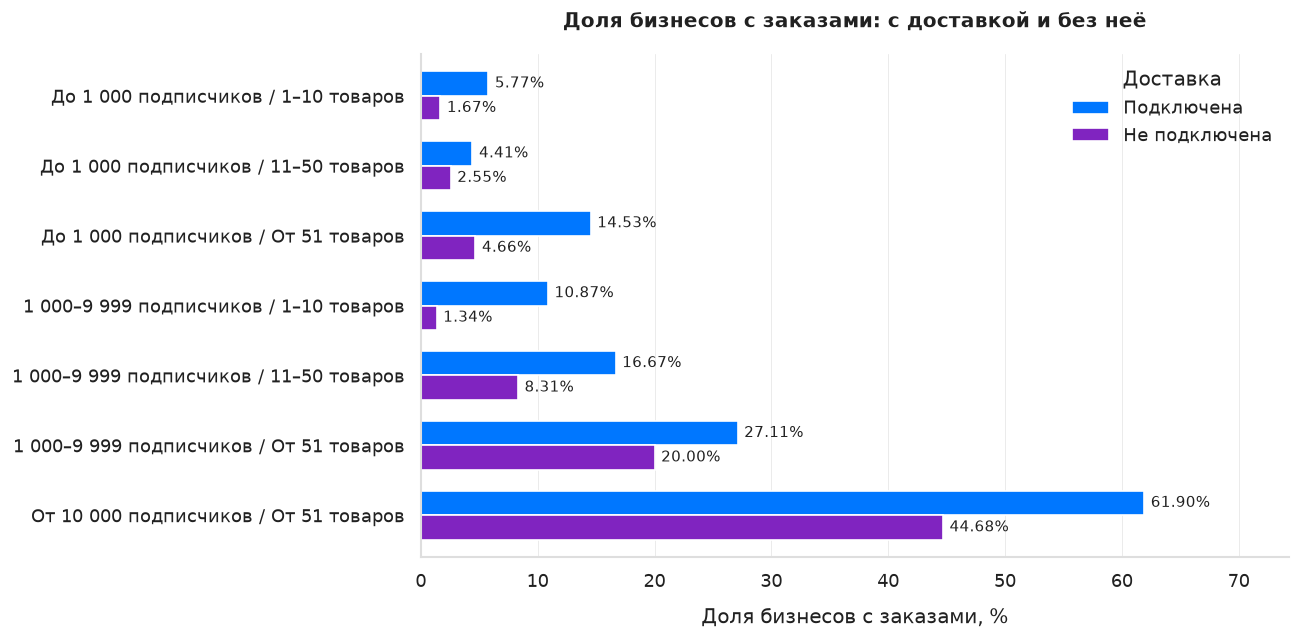

In [34]:
delivery_plot = delivery_comparison.loc[delivery_comparison[("Достаточная численность", "")]]
delivery_rates = delivery_plot["Доля с заказами, %"][["Подключена", "Не подключена"]].copy()
delivery_rates.index = [f"{audience} подписчиков / {catalog} товаров" for audience, catalog in delivery_rates.index]
ax = delivery_rates.plot.barh(figsize=(11, 5.5), color=[PRIMARY_COLOR, SECONDARY_COLOR], width=.7)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", padding=4, fontsize=9)
ax.invert_yaxis()
ax.set(title="Доля бизнесов с заказами: с доставкой и без неё",
       xlabel="Доля бизнесов с заказами, %", ylabel="",
       xlim=(0, delivery_rates.max().max() * 1.2))
ax.legend(title="Доставка")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

На графике показаны группы, где есть **хотя бы 30 бизнесов с доставкой и 30 без неё**. Все 9 сочетаний аудитории и каталога остаются в таблице. Порог 30 — условный ориентир для обзора, а не гарантия надёжности.

**Выводы:**

- **Среди малых и средних сообществ во всех группах по размеру каталога при подключённой доставке выше доля бизнесов с заказами.** Разница составляет от **+1,86 до +9,87 п.п.** Например, при малой аудитории и каталоге от 51 товара — 14,53% с доставкой против 4,66% без неё (**+9,87 п.п.**).
- **Среди крупных сообществ с каталогом от 51 товара результат такой же:** с доставкой заказы есть у 61,90% бизнесов, без доставки — у 44,68%. Разница — **+17,22 п.п.**
- **Во всех 7 группах, где есть хотя бы по 30 бизнесов с доставкой и без неё, доля с заказами выше при подключённой доставке.** Размер разницы неодинаков; положительный знак сам по себе не доказывает статистическую значимость.

**Отдельно про отрицательные разницы:** они встречаются среди крупных сообществ с небольшим каталогом.

- **1–10 товаров:** с доставкой заказы есть у **0 из 2 бизнесов (0%)**, без неё — у **5 из 54 (9,26%)**. Разница — **−9,26 п.п.**
- **11–50 товаров:** с доставкой заказы есть у **3 из 16 бизнесов (18,75%)**, без неё — у **15 из 47 (31,91%)**. Разница — **−13,16 п.п.**

В этих двух строках бизнесов с доставкой мало. Поэтому отрицательные значения сохраняем в таблице, но **не делаем по ним вывод, что доставка мешает получать заказы**. Эти строки не показаны на графике из-за порога численности.

**Что это означает:** при похожих аудитории и размере каталога у бизнесов с подключённой доставкой заказы в большинстве групп встречаются чаще. Поэтому доставку стоит учитывать как ещё один признак для дальнейшего анализа. Но мы не знаем, появились ли заказы благодаря доставке или её чаще подключают уже продающие бизнесы. Также могут различаться тематика, цены, реклама и характер товара.

**Переход к следующему шагу:** Мы рассмотрели доставку. Как связано с наличием заказов подключение оплаты при похожих аудитории и каталоге?

### Шаг 15. Оплата и наличие заказов

**Вопрос:** Чаще ли есть заказы у бизнесов с оплатой при похожих аудитории и каталоге?

Как и для доставки, рассматриваем бизнесы с чекаутом и активными товарами. Сначала показываем общую численность подключивших и не подключивших оплату, затем — сравнения внутри групп по аудитории и каталогу. **Общие доли описательные: состав двух групп может различаться.** Текущий статус оплаты не устанавливает, была ли она подключена до получения заказов.

Первая таблица — общая сводка по оплате. Во второй сравниваем бизнесы внутри групп по аудитории и каталогу: **бизнесов с заказами из общего числа (доля с заказами)**. Разница — доля при подключённой оплате минус доля без неё.

In [35]:
MIN_PAYMENT_SIDE = 30
payment_checkout = df_checkout.loc[df_checkout["Число активных товаров в каталоге"].gt(0)].copy()
payment_checkout["Оплата"] = payment_checkout["Подключена оплата"].map({1: "Подключена", 0: "Не подключена"})
payment_groups = payment_checkout.groupby(["Размер аудитории", "Размер каталога", "Оплата"], observed=True).agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "С заказами": ("Есть заказы", "sum"),
})
payment_groups["Доля с заказами, %"] = payment_groups["С заказами"] / payment_groups["Бизнесов"] * 100
payment_comparison = payment_groups.unstack("Оплата")
payment_comparison[("Разница, п.п.", "")] = (
    payment_comparison[("Доля с заказами, %", "Подключена")] - payment_comparison[("Доля с заказами, %", "Не подключена")])
payment_comparison[("Достаточная численность", "")] = (
    payment_comparison[("Бизнесов", "Подключена")].ge(MIN_PAYMENT_SIDE)
    & payment_comparison[("Бизнесов", "Не подключена")].ge(MIN_PAYMENT_SIDE))
payment_totals = payment_groups.groupby(level="Оплата")[["Бизнесов", "С заказами"]].sum()
payment_totals["Доля бизнесов подгруппы, %"] = payment_totals["Бизнесов"] / len(payment_checkout) * 100
payment_totals["Доля с заказами, %"] = payment_totals["С заказами"] / payment_totals["Бизнесов"] * 100
display(payment_totals.round(2))
payment_readable = pd.DataFrame(index=payment_comparison.index)
for status in ["Подключена", "Не подключена"]:
    values = payment_comparison.xs(status, axis=1, level="Оплата")
    payment_readable["Оплата " + status.lower()] = [
        f"{int(orders)} из {int(total)} ({rate:.2f}%)".replace(".", ",") if pd.notna(total) else "Нет бизнесов"
        for orders, total, rate in values[["С заказами", "Бизнесов", "Доля с заказами, %"]].itertuples(index=False, name=None)]
payment_readable["Разница, п.п."] = payment_comparison[("Разница, п.п.", "")].round(2)
payment_readable = payment_readable.reset_index().rename(
    columns={"Размер аудитории": "Подписчиков", "Размер каталога": "Активных товаров"})
display(payment_readable)

,Бизнесов,С заказами,"Доля бизнесов подгруппы, %","Доля с заказами, %"
Оплата,,,,
Не подключена,3441,252,94.51,7.32
Подключена,200,26,5.49,13.00


,Подписчиков,Активных товаров,Оплата подключена,Оплата не подключена,"Разница, п.п."
0,До 1 000,1–10,"2 из 25 (8,00%)","21 из 1100 (1,91%)",6.09
1,До 1 000,11–50,"2 из 27 (7,41%)","17 из 618 (2,75%)",4.66
2,До 1 000,От 51,"2 из 30 (6,67%)","24 из 280 (8,57%)",-1.90
3,1 000–9 999,1–10,"2 из 31 (6,45%)","10 из 536 (1,87%)",4.59
4,1 000–9 999,11–50,"1 из 20 (5,00%)","41 из 395 (10,38%)",-5.38
5,1 000–9 999,От 51,"8 из 42 (19,05%)","78 из 329 (23,71%)",-4.66
6,От 10 000,1–10,"0 из 5 (0,00%)","5 из 51 (9,80%)",-9.80
7,От 10 000,11–50,"2 из 9 (22,22%)","16 из 54 (29,63%)",-7.41
8,От 10 000,От 51,"7 из 11 (63,64%)","40 из 78 (51,28%)",12.35


**Выводы по таблицам:**

- Оплата подключена у **200 из 3 641 бизнеса** с чекаутом и активными товарами. В общей сводке доля бизнесов с заказами выше при оплате: **13,00% против 7,32%** без неё.
- Но после разделения по аудитории и каталогу результат неодинаков. Для сравнения с порогом 30 бизнесов с каждой стороны подходят только **3 из 9 строк**: в одной доля с заказами выше при оплате, в двух — ниже. Поэтому общую разницу нельзя автоматически переносить на все группы.

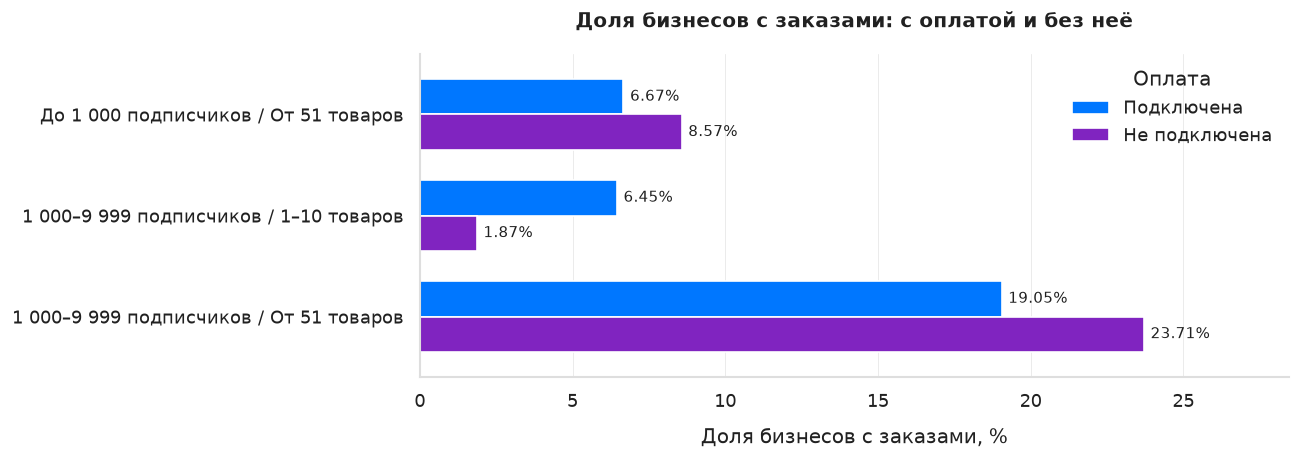

In [36]:
payment_plot = payment_comparison.loc[payment_comparison[("Достаточная численность", "")]]
payment_rates = payment_plot["Доля с заказами, %"][["Подключена", "Не подключена"]].copy()
payment_rates.index = [f"{audience} подписчиков / {catalog} товаров" for audience, catalog in payment_rates.index]
ax = payment_rates.plot.barh(figsize=(11, 4), color=[PRIMARY_COLOR, SECONDARY_COLOR], width=.7)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f%%", padding=4, fontsize=9)
ax.invert_yaxis()
ax.set(title="Доля бизнесов с заказами: с оплатой и без неё",
       xlabel="Доля бизнесов с заказами, %", ylabel="",
       xlim=(0, payment_rates.max().max() * 1.2))
ax.legend(title="Оплата")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

На графике показаны группы, где есть **хотя бы 30 бизнесов с подключённой оплатой и 30 без неё**. Все 9 сочетаний аудитории и каталога остаются во второй таблице. Порог 30 — условный ориентир для обзора, а не гарантия надёжности.

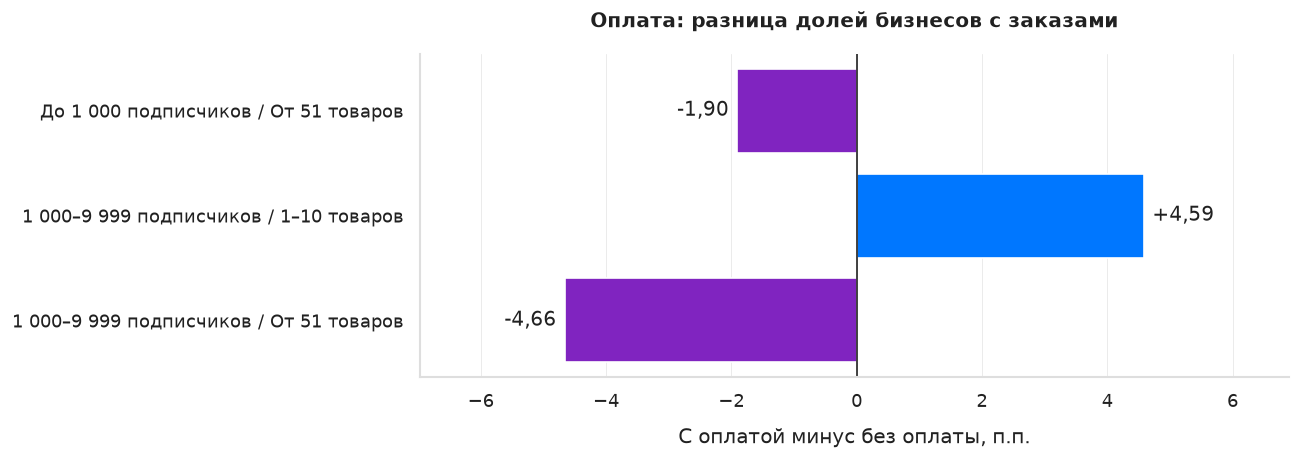

In [37]:
payment_difference = payment_plot[("Разница, п.п.", "")]
labels = [f"{audience} подписчиков / {catalog} товаров" for audience, catalog in payment_difference.index]
fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.barh(labels, payment_difference,
               color=[PRIMARY_COLOR if value >= 0 else SECONDARY_COLOR for value in payment_difference])
ax.bar_label(bars, labels=[f"{value:+.2f}".replace(".", ",") for value in payment_difference], padding=5)
ax.axvline(0, color="#212121", linewidth=1)
ax.invert_yaxis()
ax.margins(x=.25)
ax.set(title="Оплата: разница долей бизнесов с заказами",
       xlabel="С оплатой минус без оплаты, п.п.", ylabel="")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Разница = доля бизнесов с заказами при подключённой оплате минус доля без неё.** Столбец справа от нуля — при оплате доля выше, слева — ниже. Показаны те же три группы, что на предыдущем графике.

**Выводы по графикам:**

- **Малая аудитория, от 51 товара:** с оплатой заказы есть у 6,67% бизнесов, без оплаты — у 8,57%. Разница **−1,90 п.п.**
- **Средняя аудитория, 1–10 товаров:** с оплатой — 6,45%, без неё — 1,87%. Разница **+4,59 п.п.**
- **Средняя аудитория, от 51 товара:** с оплатой — 19,05%, без неё — 23,71%. Разница **−4,66 п.п.**

Разница на втором графике рассчитана по исходным долям до округления.

**Что это означает:** в отличие от доставки, **у оплаты нет одного и того же направления различий во всех показанных группах**. Где-то при подключённой оплате заказы встречаются чаще, где-то — реже. Поэтому по этим данным нельзя выбрать оплату как универсальный признак более высокой доли бизнесов с заказами.

При этом мы не доказали, что оплата не нужна или мешает продажам. Сравнений мало, а бизнесы могут различаться доставкой, тематикой и другими особенностями. Дальше посмотрим на оплату и доставку вместе.

**Переход к следующему шагу:** Доставка и оплата могут быть подключены одновременно. Как различаются результаты при разных сочетаниях этих инструментов?

### Шаг 16. Сочетания доставки и оплаты

**Вопрос:** Как различаются результаты при разных сочетаниях доставки и оплаты?

Сохраняем подгруппу с чекаутом и активными товарами. Сначала показываем четыре сочетания инструментов. **Эта общая сводка ещё не учитывает различия аудитории, каталога и тематики.** Затем проверяем, хватает ли наблюдений для сравнения оплаты при одинаковом статусе доставки, аудитории и каталоге.

In [38]:
tool_checkout = df_checkout.loc[df_checkout["Число активных товаров в каталоге"].gt(0)].copy()
tool_combinations = tool_checkout.groupby(["Подключена доставка", "Подключена оплата"]).agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "С заказами": ("Есть заказы", "sum"),
})
tool_combinations["Доля с заказами, %"] = tool_combinations["С заказами"] / tool_combinations["Бизнесов"] * 100
tool_combinations = tool_combinations.rename(index={0: "Нет", 1: "Есть"})
tool_combinations.index.names = ["Доставка", "Оплата"]
display(tool_combinations.round(2))

Бизнесов  С заказами  Доля с заказами, %
Доставка Оплата                                          
Нет      Нет         2816         145                5.15
         Есть         106          10                9.43
Есть     Нет          625         107               17.12
         Есть          94          16               17.02

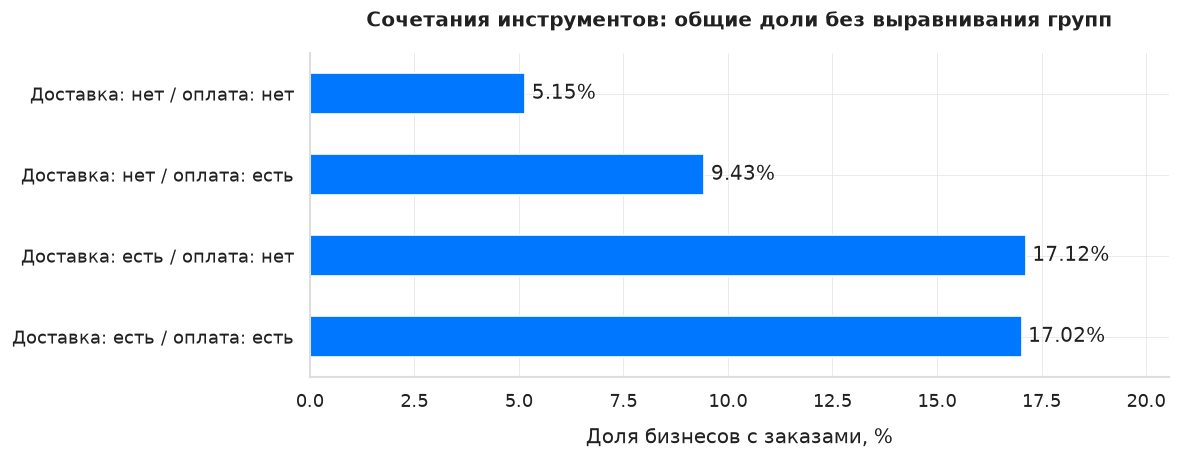

In [39]:
tool_rates = tool_combinations["Доля с заказами, %"].copy()
tool_rates.index = [f"Доставка: {delivery.lower()} / оплата: {payment.lower()}" for delivery, payment in tool_rates.index]
ax = tool_rates.iloc[::-1].plot.barh(figsize=(10, 4), color="#0077FF")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.margins(x=.2)
ax.set(title="Сочетания инструментов: общие доли без выравнивания групп",
       xlabel="Доля бизнесов с заказами, %", ylabel="")
plt.tight_layout()
plt.show()

**Выводы по общей сводке:**

- **При подключённой доставке доля бизнесов с заказами выше при обоих статусах оплаты.** Без оплаты — **17,12% с доставкой против 5,15% без неё**. При подключённой оплате — **17,02% с доставкой против 9,43% без неё**.
- **У оплаты одинакового результата в обеих подгруппах не видим.** Среди бизнесов без доставки доля с заказами выше при оплате: **9,43% против 5,15%**. Среди бизнесов с доставкой доли практически одинаковы: **17,02% с оплатой и 17,12% без оплаты**.

**Что это означает:** в общей сводке различие по доставке видно и у бизнесов с оплатой, и без неё. А наличие оплаты не всегда сопровождается более высокой долей бизнесов с заказами. Пока это сравнение без учёта аудитории и каталога; ниже проверяем, хватает ли бизнесов для более сопоставимых групп.

**Гипотеза 1. Недоверие к встроенной оплате.** Некоторые покупатели могут не доверять оплате внутри ВКонтакте и предпочитать другой способ расчёта. Поэтому подключение оплаты может не сопровождаться более высокой долей бизнесов с заказами.

**Для проверки** нужны данные об отказах на этапе оплаты, используемых способах расчёта и опросы покупателей. В текущем датасете этих данных нет.

**Гипотеза 2. Доверие к знакомым службам доставки.** Если доставка организована через известные покупателям внешние сервисы, доверие к ним может снижать опасения при покупке и помогать покупателям решиться на заказ. Это одно из возможных объяснений более высокой доли бизнесов с заказами при подключённой доставке.

**Для проверки** нужны сведения об используемых службах доставки, отношении покупателей к ним и оформлении заказов. В датасете есть только признак подключения доставки: мы не знаем, какие сервисы используются и доверяют ли им покупатели. Гипотеза не проверена.

Бизнесы без подключённой доставки

In [40]:
payment_coverage = tool_checkout.groupby(
    ["Размер аудитории", "Размер каталога", "Подключена доставка", "Подключена оплата"], observed=True).size().unstack("Подключена оплата", fill_value=0)
payment_coverage = payment_coverage.rename(columns={0: "Без оплаты", 1: "С оплатой"})
payment_coverage = payment_coverage.rename(index={0: "Нет", 1: "Есть"}, level="Подключена доставка")
payment_coverage.index.names = ["Подписчиков", "Активных товаров", "Доставка"]
payment_coverage["Не менее 30 с обеих сторон"] = payment_coverage[["Без оплаты", "С оплатой"]].ge(30).all(axis=1)
coverage_without_delivery = payment_coverage.xs("Нет", level="Доставка")[["Без оплаты", "С оплатой"]]
coverage_without_delivery = coverage_without_delivery.rename_axis(columns=None).reset_index().rename(
    columns={"Без оплаты": "Без оплаты, бизнесов", "С оплатой": "С оплатой, бизнесов"})
display(coverage_without_delivery)

,Подписчиков,Активных товаров,"Без оплаты, бизнесов","С оплатой, бизнесов"
0,До 1 000,1–10,1006,15
1,До 1 000,11–50,495,14
2,До 1 000,От 51,185,8
3,1 000–9 999,1–10,494,27
4,1 000–9 999,11–50,315,10
5,1 000–9 999,От 51,188,17
6,От 10 000,1–10,49,5
7,От 10 000,11–50,44,3
8,От 10 000,От 51,40,7


Бизнесы с подключённой доставкой

In [41]:
coverage_with_delivery = payment_coverage.xs("Есть", level="Доставка")[["Без оплаты", "С оплатой"]]
coverage_with_delivery = coverage_with_delivery.rename_axis(columns=None).reset_index().rename(
    columns={"Без оплаты": "Без оплаты, бизнесов", "С оплатой": "С оплатой, бизнесов"})
display(coverage_with_delivery)

,Подписчиков,Активных товаров,"Без оплаты, бизнесов","С оплатой, бизнесов"
0,До 1 000,1–10,94,10
1,До 1 000,11–50,123,13
2,До 1 000,От 51,95,22
3,1 000–9 999,1–10,42,4
4,1 000–9 999,11–50,80,10
5,1 000–9 999,От 51,141,25
6,От 10 000,1–10,2,0
7,От 10 000,11–50,10,6
8,От 10 000,От 51,38,4


Ни в одной строке обеих таблиц нет хотя бы 30 бизнесов с оплатой и 30 без неё.

**Переход к следующему шагу:** Мы рассмотрели, как различается наличие заказов у бизнесов с разными сочетаниями доставки и оплаты. Теперь посмотрим на сами товары: чаще ли встречаются заказы у бизнесов с недорогим или дорогим ассортиментом? Для этого сравним группы по медианной цене товара.

### Шаг 17. Цена товара и наличие заказов

**Вопрос:** Как различается доля бизнесов с заказами при разном ценовом уровне каталога?

Используем медианную цену товара, а не средний чек заказа. Берём бизнесы с чекаутом и активными товарами. **Для сравнения цен оставляем только статус «Цена указана»**: технические нули при неизвестной цене не считаем дешёвыми товарами. Значения 0 со статусом известной цены сохраняем. Сначала показываем, сколько бизнесов имеют известную и неизвестную цену.

In [42]:
price_catalog = df_checkout.loc[df_checkout["Число активных товаров в каталоге"].gt(0)].copy()
price_availability = price_catalog["Статус цены"].value_counts().rename("Бизнесов").to_frame()
price_availability["Доля подгруппы, %"] = price_availability["Бизнесов"] / len(price_catalog) * 100
display(price_availability.round(2))

,Бизнесов,"Доля подгруппы, %"
Статус цены,,
Цена указана,3533,97.03
Цена неизвестна,108,2.97


Разделяем известные цены на три диапазона: до 1 000 ₽, 1 000–4 999 ₽ и от 5 000 ₽. Границы условные, для обзора.

В каждой строке — одна группа по аудитории и каталогу. Три последних столбца — ценовые диапазоны; в каждой ячейке указано **сколько бизнесов с заказами из общего числа (их доля)**. Например, «44 из 149 (29,53%)».

In [43]:
MIN_PRICE_SIZE = 30
price_order = ["До 1 000 ₽", "1 000–4 999 ₽", "От 5 000 ₽"]
priced_checkout = price_catalog.loc[price_catalog["Статус цены"].eq("Цена указана")].copy()
priced_checkout["Цена товара"] = pd.cut(priced_checkout["Медианная цена товара, ₽"],
    bins=[0, 1000, 5000, float("inf")], labels=price_order, right=False)
price_orders = priced_checkout.groupby(["Размер аудитории", "Размер каталога", "Цена товара"], observed=True).agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "С заказами": ("Есть заказы", "sum"),
})
price_orders["Доля с заказами, %"] = price_orders["С заказами"] / price_orders["Бизнесов"] * 100
price_orders["Не менее 30 бизнесов"] = price_orders["Бизнесов"].ge(MIN_PRICE_SIZE)
price_readable = price_orders.assign(Результат=[
    f"{int(orders)} из {int(total)} ({rate:.2f}%)".replace(".", ",")
    for orders, total, rate in price_orders[["С заказами", "Бизнесов", "Доля с заказами, %"]].itertuples(index=False, name=None)])
price_readable = price_readable["Результат"].unstack("Цена товара").reindex(columns=price_order)
price_readable = price_readable.rename_axis(columns=None).reset_index().rename(
    columns={"Размер аудитории": "Подписчиков", "Размер каталога": "Активных товаров"})
display(price_readable)

,Подписчиков,Активных товаров,До 1 000 ₽,1 000–4 999 ₽,От 5 000 ₽
0,До 1 000,1–10,"7 из 320 (2,19%)","10 из 494 (2,02%)","5 из 266 (1,88%)"
1,До 1 000,11–50,"6 из 223 (2,69%)","11 из 272 (4,04%)","2 из 138 (1,45%)"
2,До 1 000,От 51,"14 из 103 (13,59%)","12 из 148 (8,11%)","0 из 56 (0,00%)"
3,1 000–9 999,1–10,"2 из 153 (1,31%)","5 из 215 (2,33%)","5 из 172 (2,91%)"
4,1 000–9 999,11–50,"23 из 131 (17,56%)","14 из 154 (9,09%)","5 из 120 (4,17%)"
5,1 000–9 999,От 51,"44 из 149 (29,53%)","34 из 127 (26,77%)","8 из 91 (8,79%)"
6,От 10 000,1–10,"1 из 15 (6,67%)","2 из 20 (10,00%)","2 из 16 (12,50%)"
7,От 10 000,11–50,"6 из 20 (30,00%)","8 из 24 (33,33%)","4 из 19 (21,05%)"
8,От 10 000,От 51,"20 из 29 (68,97%)","21 из 37 (56,76%)","6 из 21 (28,57%)"


На каждой карте — один размер каталога. Строки — аудитория, столбцы — цена. В ячейках показаны доля с заказами и «с заказами / всего». **Шкала цвета одинакова на всех картах.** Серые ячейки содержат меньше 30 бизнесов и не используются для уверенных самостоятельных выводов; даже при большей численности нужно учитывать число заказов и неопределённость.

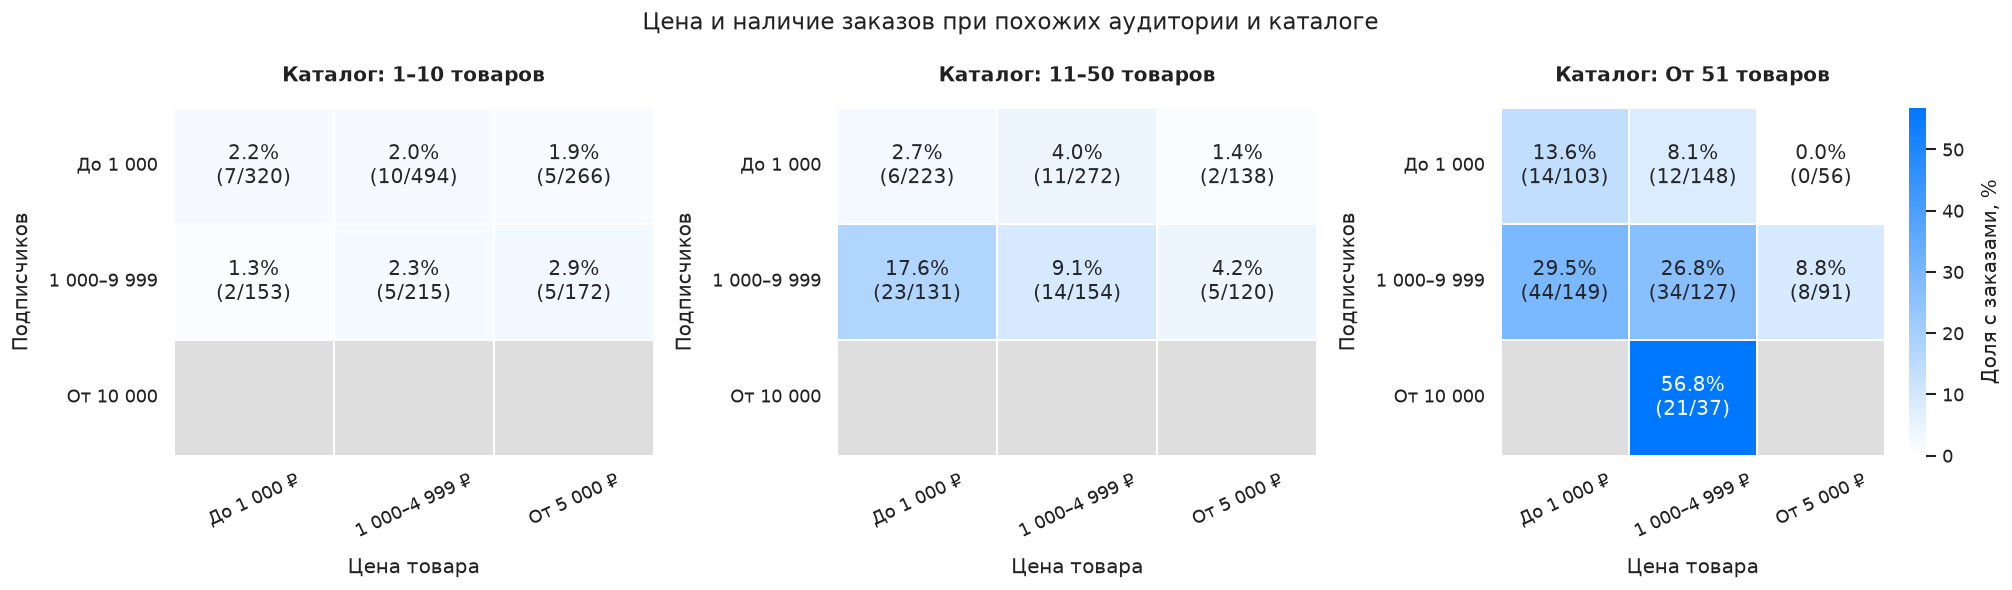

In [44]:
catalog_order = ["1–10", "11–50", "От 51"]
audience_order = df_checkout["Размер аудитории"].cat.categories
vmax = price_orders.loc[price_orders["Не менее 30 бизнесов"], "Доля с заказами, %"].max()
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for i, (ax, catalog) in enumerate(zip(axes, catalog_order)):
    group = price_orders.xs(catalog, level="Размер каталога")
    rates = group["Доля с заказами, %"].unstack("Цена товара").reindex(index=audience_order, columns=price_order)
    counts = group["Бизнесов"].unstack("Цена товара").reindex(index=audience_order, columns=price_order)
    orders = group["С заказами"].unstack("Цена товара").reindex(index=audience_order, columns=price_order)
    labels = rates.round(1).astype(str) + "%" + chr(10) + "(" + orders.astype(str) + "/" + counts.astype(str) + ")"
    ax.set_facecolor("#DEDEDE")
    sns.heatmap(rates, mask=counts.lt(MIN_PRICE_SIZE) | counts.isna(), annot=labels, fmt="", cmap=SEQUENTIAL_CMAP,
                vmin=0, vmax=vmax, linewidths=1, cbar=i == 2,
                cbar_kws={"label": "Доля с заказами, %"}, ax=ax)
    ax.set(title=f"Каталог: {catalog} товаров", xlabel="Цена товара", ylabel="Подписчиков")
    ax.tick_params(axis="y", rotation=0)
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Цена и наличие заказов при похожих аудитории и каталоге", fontsize=14)
plt.tight_layout()
plt.show()

**Выводы:**

- **В 5 из 6 групп малой и средней аудитории при цене товара от 5 000 ₽ доля бизнесов с заказами самая низкая.** Например, при средней аудитории и каталоге от 51 товара: **29,53%** при цене до 1 000 ₽, **26,77%** при цене 1 000–4 999 ₽ и **8,79%** при цене от 5 000 ₽. В каждом ценовом диапазоне этих шести групп есть хотя бы 30 бизнесов.
- **Есть исключения:** при средней аудитории и каталоге 1–10 товаров доля с заказами, наоборот, растёт по ценовым диапазонам: **1,31% → 2,33% → 2,91%**. Но заказы есть всего у **2, 5 и 5 бизнесов** соответственно. Поэтому правило «дешевле — чаще есть заказы» не универсальное.
- **Каталог важно учитывать вместе с ценой.** Среди сообществ со средней аудиторией и ценой до 1 000 ₽ доля с заказами составляет **1,31%** при 1–10 товарах, **17,56%** при 11–50 и **29,53%** при каталоге от 51 товара.
- **По крупным сообществам данных для уверенного сравнения ценовых диапазонов мало:** из 9 ценовых ячеек только одна содержит хотя бы 30 бизнесов, в остальных — от 15 до 29. Поэтому общую закономерность для крупных сообществ здесь не формулируем.

**Что это означает:** ценовой уровень стоит учитывать при выборе и сравнении групп. Среди малых и средних сообществ дорогой ассортимент чаще сопровождается более низкой долей бизнесов с заказами, но результат зависит также от размера каталога и имеет исключения.

**Это не рекомендация снижать цены.** Мы сравниваем разные бизнесы, а не продажи одного бизнеса до и после изменения цены. Медианная цена каталога не равна цене купленного товара или среднему чеку; тематика, ассортимент, реклама и условия покупки тоже могут объяснять различия.

**Гипотеза:** малым и средним сообществам с дорогим ассортиментом может не хватать доверия покупателей и информации для решения о покупке. Отзывы, подробные обзоры товаров и понятные условия оплаты, доставки и возврата могут помочь увеличить число заказов через чекаут.

**Для проверки** нужно изучить причины отказа от покупки и провести эксперимент с такими материалами и условиями в сопоставимых группах бизнесов. В текущем датасете нет данных о доверии покупателей, причинах отказов и содержании карточек товаров, поэтому гипотеза пока не проверена.

**Переход к следующему шагу:** Теперь учтём аудиторию, размер каталога и цену. Различается ли наличие заказов между тематиками при более близких условиях?

### Шаг 18. Тематики сообществ и заказы

**Вопрос:** Какие тематики представлены среди товарных бизнесов и как различаются их результаты?

**Выборка обзора: бизнесы с подключённым чекаутом и хотя бы одним активным товаром.** Сначала отдельно смотрим тематики с наибольшим числом бизнесов и с наибольшим числом заказов. Это общие показатели; они пока не учитывают различия аудитории, каталога и цены.

**Тематики с наибольшим числом бизнесов**

In [45]:
topic_businesses = df_checkout.loc[df_checkout["Число активных товаров в каталоге"].gt(0)].copy()
topic_summary = topic_businesses.groupby("Тематика").agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "С заказами": ("Есть заказы", "sum"),
    "Заказов": ("Заказы через чекаут", "sum"), "GMV, ₽": ("GMV через чекаут, ₽", "sum"),
})
topic_summary["Доля с заказами, %"] = topic_summary["С заказами"] / topic_summary["Бизнесов"] * 100
topic_summary["С заказами, бизнесов"] = [
    f"{int(sellers)} из {int(total)} ({rate:.2f}%)".replace(".", ",")
    for sellers, total, rate in topic_summary[["С заказами", "Бизнесов", "Доля с заказами, %"]].itertuples(index=False, name=None)]
topic_summary["Доля всех бизнесов, %"] = topic_summary["Бизнесов"] / len(topic_businesses) * 100
topics_by_size = topic_summary.sort_values(["Бизнесов", "Заказов"], ascending=False).head(8)
display(topics_by_size[["Бизнесов", "Доля всех бизнесов, %", "С заказами, бизнесов"]].round(2).reset_index())

,Тематика,Бизнесов,"Доля всех бизнесов, %","С заказами, бизнесов"
0,Кулинария и еда,420,11.54,"63 из 420 (15,00%)"
1,Красота и здоровье,379,10.41,"12 из 379 (3,17%)"
2,Дом и ремонт,346,9.50,"10 из 346 (2,89%)"
3,Творчество и хендмейд,268,7.36,"26 из 268 (9,70%)"
4,Товары и магазины,246,6.76,"38 из 246 (15,45%)"
5,Мода и стиль,233,6.40,"19 из 233 (8,15%)"
6,Транспорт,198,5.44,"13 из 198 (6,57%)"
7,Путешествия и отдых,182,5.00,"7 из 182 (3,85%)"


**Тематики с наибольшим числом заказов**

Рядом с числом заказов показываем, сколько бизнесов их получили. Большое число заказов у нескольких продавцов не означает, что вся тематика одинаково успешна.

In [46]:
topics_by_orders = topic_summary.sort_values(["Заказов", "Бизнесов"], ascending=False).head(8)
display(topics_by_orders[["Бизнесов", "С заказами, бизнесов", "Заказов", "GMV, ₽"]].reset_index())

,Тематика,Бизнесов,"С заказами, бизнесов",Заказов,"GMV, ₽"
0,Кулинария и еда,420,"63 из 420 (15,00%)",1180,2393650
1,Игры,21,"3 из 21 (14,29%)",549,362320
2,Товары и магазины,246,"38 из 246 (15,45%)",336,1582270
3,Творчество и хендмейд,268,"26 из 268 (9,70%)",331,263090
4,Образование,172,"17 из 172 (9,88%)",325,314280
5,Транспорт,198,"13 из 198 (6,57%)",175,1222410
6,Мода и стиль,233,"19 из 233 (8,15%)",152,574731
7,Красота и здоровье,379,"12 из 379 (3,17%)",56,432130


**Выводы по первым двум таблицам:**

- **«Кулинария и еда» лидирует и по числу бизнесов, и по числу заказов:** 420 бизнесов, у 63 есть заказы (15,00%), суммарно — 1 180 заказов. Здесь продажи наблюдаются у большего числа бизнесов, чем в остальных показанных тематиках.
- **Много бизнесов в тематике не означает, что большая их доля получает заказы.** В «Красоте и здоровье» 379 бизнесов, но с заказами только 12 (3,17%); в «Доме и ремонте» — 346 бизнесов и 10 с заказами (2,89%). Для сравнения, в «Товарах и магазинах» бизнесов меньше — 246, но с заказами 38 (15,45%).
- **Высокое место по общему числу заказов может быть результатом нескольких продавцов.** В тематике «Игры» 549 заказов, но они есть лишь у 3 из 21 бизнеса. Поэтому при выборе тематики смотрим не только общее число заказов, но и сколько бизнесов их получают.

**Один пример при похожих условиях**

Оставляем один пример из доступных сравнений: бизнесы с чекаутом, **до 1 000 подписчиков, 11–50 активными товарами и медианной ценой 1 000–4 999 ₽**. Сравниваем три тематики. Это иллюстрация, а не общий рейтинг тематик.

In [47]:
MIN_THEME_SIZE = 30
theme_cells = priced_checkout.groupby(
    ["Размер аудитории", "Размер каталога", "Цена товара", "Тематика"], observed=True).agg(**{
        "Бизнесов": ("ID бизнеса", "size"), "С заказами": ("Есть заказы", "sum"),
    })
theme_cells["Доля с заказами, %"] = theme_cells["С заказами"] / theme_cells["Бизнесов"] * 100
theme_dense = theme_cells.loc[theme_cells["Бизнесов"].ge(MIN_THEME_SIZE)].copy()
theme_dense["Тематик в срезе"] = theme_dense.groupby(level=[0, 1, 2], observed=True)["Бизнесов"].transform("size")
theme_matches = theme_dense.loc[theme_dense["Тематик в срезе"].ge(2)]
theme_coverage = pd.DataFrame({"Бизнесов": [len(priced_checkout), theme_matches["Бизнесов"].sum()]},
    index=["С чекаутом, активными товарами и известной ценой", "В доступных тематических сравнениях"])
theme_coverage["Доля подгруппы, %"] = theme_coverage["Бизнесов"] / len(priced_checkout) * 100

theme_example = theme_matches.loc[("До 1 000", "11–50", "1 000–4 999 ₽")].copy()
theme_example = theme_example[["Бизнесов", "С заказами", "Доля с заказами, %"]].sort_values(
    "Доля с заказами, %", ascending=False).reset_index()
display(theme_example.round(2))

,Тематика,Бизнесов,С заказами,"Доля с заказами, %"
0,Товары и магазины,31,4,12.90
1,Творчество и хендмейд,30,1,3.33
2,Кулинария и еда,39,1,2.56


**Вывод по примеру:** в «Товарах и магазинах» заказы есть у **4 из 31 бизнеса (12,90%)**, в «Творчестве и хендмейде» — у **1 из 30 (3,33%)**, в «Кулинарии и еде» — у **1 из 39 (2,56%)**.

**Что это означает:** даже при похожих аудитории, каталоге и цене результаты тематик могут различаться. Но здесь всего несколько бизнесов с заказами, поэтому этот пример не позволяет уверенно назвать одну тематику лучшей. Общие топы выше помогают выбрать темы для изучения, а не доказывают, что сама тематика обеспечивает продажи.

**Переход к следующему шагу:** В тематических сравнениях не везде хватает наблюдений. Вернёмся к товарным просмотрам: чем различаются их отсутствие и небольшой положительный объём?

### Шаг 19. Нулевые и небольшие товарные просмотры

**Вопрос:** Чем различаются бизнесы с нулевыми и небольшими положительными товарными просмотрами?

Продолжаем анализ бизнесов с чекаутом и активными товарами. Диапазоны 0, 1–100, 101–1 000 и от 1 001 служат описанию данных и не являются универсальными нормами качества. Внутри групп по аудитории показываем заказы и открытия карточек. Число просмотров не равно числу уникальных покупателей.

В таблице сравниваем группы по аудитории и числу товарных просмотров. В столбцах с заказами и открытиями — **сколько бизнесов имеют такой результат из общего числа (их доля)**. Медиану активных товаров оставляем, чтобы видеть различия в размере каталога.

In [48]:
import numpy as np

analysis = df.assign(
    Публикаций=df[["Посты за 30 дней", "Клипы за 30 дней", "Посты с товаром за 30 дней", "Клипы с товаром за 30 дней"]].sum(axis=1),
    Есть_заказы=df["Заказы через чекаут"].gt(0), Есть_товары=df["Число активных товаров в каталоге"].gt(0),
    Есть_услуги=df["Число активных услуг"].gt(0), Есть_просмотры=df["Просмотры товарного контента"].gt(0),
    Есть_открытия=df["Открытия карточки товара из контента"].gt(0), Есть_реклама=df["Траты на рекламу всего, ₽"].gt(0))
analysis["Аудитория"] = pd.cut(analysis["Число подписчиков"], [0, 1000, 10000, np.inf], right=False,
                               labels=["До 1 000", "1 000–9 999", "От 10 000"])
analysis["Каталог"] = pd.cut(analysis["Число активных товаров в каталоге"], [0, 1, 11, 51, np.inf], right=False,
                             labels=["Нет товаров", "1–10", "11–50", "От 51"])
commerce = analysis.loc[analysis["Подключён чекаут"].eq(1) & analysis["Есть_товары"]].copy()
commerce["Просмотры"] = pd.cut(commerce["Просмотры товарного контента"], [0, 1, 101, 1001, np.inf], right=False,
                              labels=["Нет", "1–100", "101–1 000", "От 1 001"])
view_bands = commerce.groupby(["Аудитория", "Просмотры"], observed=True).agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "С заказами": ("Есть_заказы", "sum"),
    "С открытиями карточек": ("Есть_открытия", "sum"), "Активные товары, медиана": ("Число активных товаров в каталоге", "median")})
view_bands["С заказами, %"] = view_bands["С заказами"] / view_bands["Бизнесов"] * 100
view_bands_readable = pd.DataFrame(index=view_bands.index)
for column in ["С заказами", "С открытиями карточек"]:
    view_bands_readable[column] = [
        f"{int(count)} из {int(total)} ({count / total * 100:.2f}%)".replace(".", ",")
        for count, total in view_bands[[column, "Бизнесов"]].itertuples(index=False, name=None)]
view_bands_readable["Товаров, медиана"] = view_bands["Активные товары, медиана"]
view_bands_readable = view_bands_readable.reset_index().rename(
    columns={"Аудитория": "Подписчиков", "Просмотры": "Товарных просмотров"})
display(view_bands_readable)

,Подписчиков,Товарных просмотров,С заказами,С открытиями карточек,"Товаров, медиана"
0,До 1 000,Нет,"39 из 1529 (2,55%)","4 из 1529 (0,26%)",8.0
1,До 1 000,1–100,"10 из 338 (2,96%)","35 из 338 (10,36%)",13.0
2,До 1 000,101–1 000,"11 из 166 (6,63%)","66 из 166 (39,76%)",21.0
3,До 1 000,От 1 001,"8 из 47 (17,02%)","38 из 47 (80,85%)",32.0
4,1 000–9 999,Нет,"62 из 994 (6,24%)","6 из 994 (0,60%)",12.0
5,1 000–9 999,1–100,"28 из 182 (15,38%)","7 из 182 (3,85%)",22.0
6,1 000–9 999,101–1 000,"26 из 94 (27,66%)","36 из 94 (38,30%)",32.0
7,1 000–9 999,От 1 001,"24 из 83 (28,92%)","72 из 83 (86,75%)",52.0
8,От 10 000,Нет,"31 из 129 (24,03%)","5 из 129 (3,88%)",26.0
9,От 10 000,1–100,"11 из 30 (36,67%)","6 из 30 (20,00%)",51.5


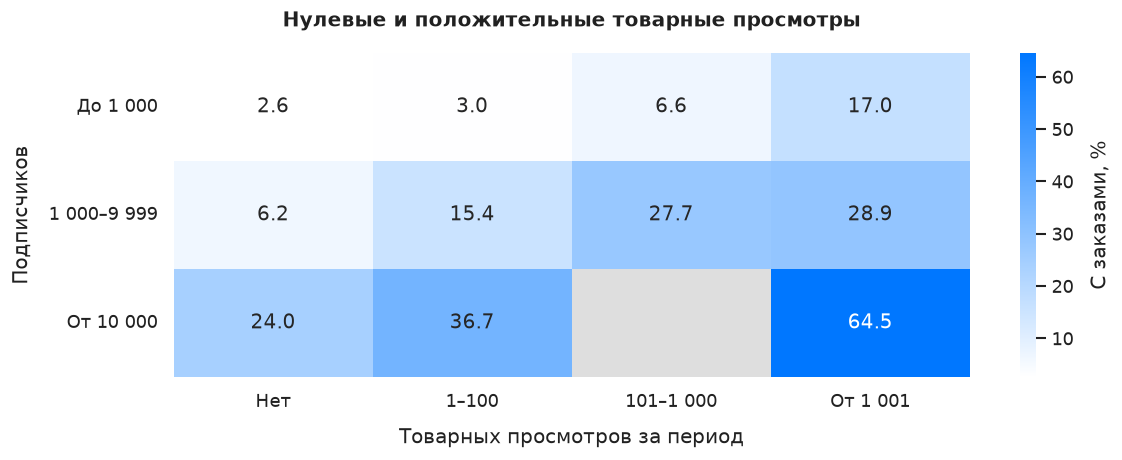

In [49]:
rates = view_bands["С заказами, %"].unstack("Просмотры")
counts = view_bands["Бизнесов"].unstack("Просмотры")
fig, ax = plt.subplots(figsize=(10, 4))
ax.set_facecolor("#DEDEDE")
sns.heatmap(rates, mask=counts.lt(30) | counts.isna(), annot=True, fmt=".1f", cmap=SEQUENTIAL_CMAP,
            cbar_kws={"label": "С заказами, %"}, ax=ax)
ax.set(title="Нулевые и положительные товарные просмотры", xlabel="Товарных просмотров за период", ylabel="Подписчиков")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

**Выводы:**

- **В группах с большим числом товарных просмотров выше доля бизнесов с заказами — при каждом размере аудитории.** Среди малых сообществ она составляет **2,55% → 2,96% → 6,63% → 17,02%** по диапазонам просмотров. Среди средних — **6,24% → 15,38% → 27,66% → 28,92%**, среди крупных — **24,03% → 36,67% → 44,44% → 64,52%**. Это доля бизнесов с заказами, а не число заказов.
- **Доля бизнесов с открытиями карточек также выше в группах с большими просмотрами.** Между отсутствием товарных просмотров и диапазоном от 1 001 просмотра она различается от **0,26% до 80,85%** у малых сообществ, от **0,60% до 86,75%** у средних и от **3,88% до 90,32%** у крупных. Сравниваем доли, поскольку численность групп разная.
- **В группах с большими просмотрами обычно больше и активных товаров.** У малых сообществ медиана каталога — **8 → 13 → 21 → 32 товара**, у средних — **12 → 22 → 32 → 52**. У крупных общий рисунок похож, но есть исключение: **26 → 51,5 → 44 → 149**. Поэтому нельзя говорить, что каталог увеличивается строго в каждом следующем диапазоне.

**Что это означает:** бизнесы с большими товарными просмотрами чаще имеют заказы и открытия карточек, но обычно отличаются ещё и большим каталогом. Поэтому товарные просмотры рассматриваем вместе с размером ассортимента и аудитории. Это сравнение разных бизнесов за один период: оно не означает, что мы наблюдали рост просмотров и последующий рост заказов у одного и того же бизнеса. Группу крупных сообществ со 101–1 000 просмотрами оцениваем осторожно — в ней только 18 бизнесов.

**Переход к следующему шагу:** Просмотры не обязательно сопровождаются действиями и заказами. Какие сочетания просмотров, открытий карточек и заказов наблюдаются у бизнесов?

### Шаг 20. Разрывы между интересом и заказами

**Вопрос:** Какие сочетания просмотров, открытий карточек и заказов наблюдаются у бизнесов?

Выделяем непересекающиеся состояния среди бизнесов с чекаутом и активными товарами. **Это не пользовательская воронка:** действия и заказы не связаны на уровне людей, а заказы могли приходить из других источников. Состояние с заказами имеет приоритет при классификации.

**«Доля бизнесов, %» считается от всех 3 641 бизнеса с чекаутом и активными товарами.** Например, 233 бизнеса с открытиями карточек, но без заказов — это 6,40% этой выборки. «Бизнесов с рекламой» — число бизнесов с рекламными расходами внутри соответствующей строки.

**«Доля с рекламой, %» считается внутри строки:** число бизнесов с рекламными расходами делим на общее число бизнесов этой группы. Это другой знаменатель, чем у доли группы во всей выборке.

,Бизнесов,"Доля бизнесов, %",Бизнесов с рекламой,"Доля с рекламой, %","Подписчики, медиана","Активные товары, медиана"
Состояние,,,,,,
Есть заказы,278,7.64,40,14.39,3300.0,65.0
"Есть открытия, нет заказов",233,6.40,36,15.45,820.0,20.0
"Есть просмотры, нет открытий и заказов",623,17.11,45,7.22,540.0,18.0
"Нет товарных просмотров, открытий и заказов",2507,68.85,115,4.59,670.0,9.0


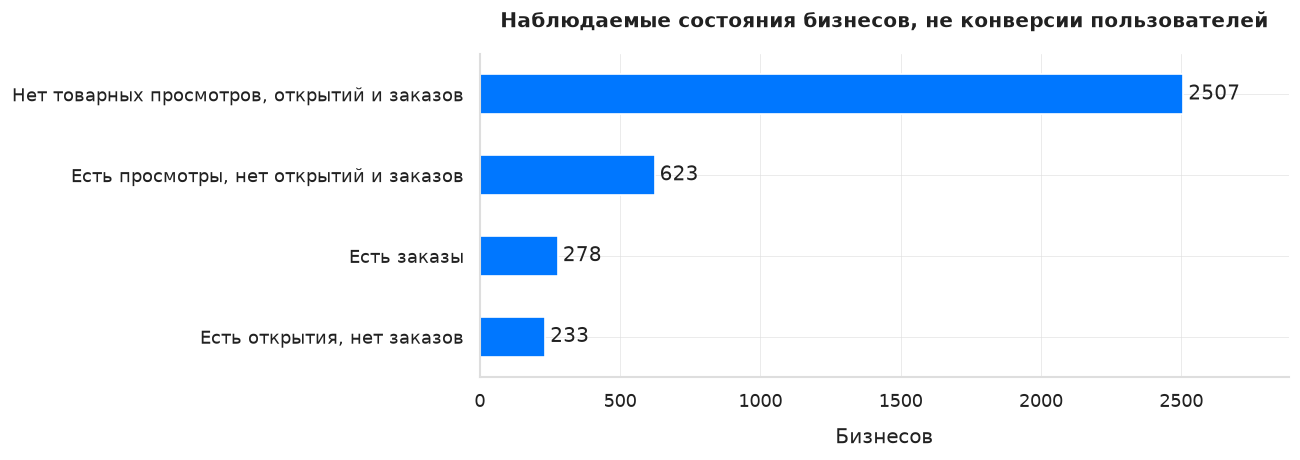

In [50]:
commerce["Состояние"] = np.select(
    [commerce["Есть_заказы"], commerce["Есть_открытия"], commerce["Есть_просмотры"]],
    ["Есть заказы", "Есть открытия, нет заказов", "Есть просмотры, нет открытий и заказов"],
    default="Нет товарных просмотров, открытий и заказов")
commerce_states = commerce.groupby("Состояние").agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "Подписчики, медиана": ("Число подписчиков", "median"),
    "Активные товары, медиана": ("Число активных товаров в каталоге", "median"), "С рекламой": ("Есть_реклама", "sum")})
commerce_states["Доля, %"] = commerce_states["Бизнесов"] / len(commerce) * 100
commerce_states["С рекламой, %"] = commerce_states["С рекламой"] / commerce_states["Бизнесов"] * 100
commerce_states_display = commerce_states[["Бизнесов", "Доля, %", "С рекламой", "С рекламой, %",
                                            "Подписчики, медиана", "Активные товары, медиана"]].rename(
    columns={"Доля, %": "Доля бизнесов, %", "С рекламой": "Бизнесов с рекламой", "С рекламой, %": "Доля с рекламой, %"})
display(commerce_states_display.round(2))
ax = commerce_states["Бизнесов"].sort_values().plot.barh(figsize=(11, 4), color="#0077FF")
ax.bar_label(ax.containers[0], padding=3, fmt="%.0f")
ax.set(title="Наблюдаемые состояния бизнесов, не конверсии пользователей", xlabel="Бизнесов", ylabel="")
ax.margins(x=.15)
plt.tight_layout()
plt.show()

**Выводы:**

- **У 233 бизнесов карточки товаров открывают, но заказов через чекаут нет.** Это **6,40%** рассматриваемой выборки. Для сравнения, заказы есть у **278 бизнесов (7,64%)**.
- **У бизнесов с открытиями без заказов меньше аудитория и каталог, чем у бизнесов с заказами:** медиана подписчиков — **820 против 3 300**, активных товаров — **20 против 65**.
- **Доля рекламодателей в группе с открытиями без заказов немного выше:** **15,45% против 14,39%** у бизнесов с заказами. Это доля бизнесов с рекламными расходами, а не величина бюджета. Значит, наличие рекламных расходов и открытий карточек само по себе не гарантирует заказов через чекаут.
- **Самая большая группа — без товарных просмотров, открытий карточек и заказов:** **2 507 бизнесов, или 68,85%** выборки. Её ситуация отличается от бизнесов, где карточки уже открывают, но заказов нет.

**Что это означает:** наличие чекаута, рекламных расходов и открытий карточек не гарантирует заказов через чекаут. Бизнесы, у которых карточки открывают, но заказов нет, отличаются от бизнесов с заказами меньшими аудиторией и каталогом. **Поэтому сам факт интереса к товарам ещё не означает, что покупка состоится именно через чекаут.** Причину этого различия по текущей таблице установить нельзя; продажи могли оформляться и другими способами.

**Гипотеза. Объём и состав каталога.** У части бизнесов с открытиями карточек, но без заказов небольшой ассортимент может ограничивать выбор: покупатель интересуется товаром, но не находит подходящий вариант. Расширение каталога востребованными товарами может помочь увеличить число заказов через чекаут.

**Как проверить:** сначала сравнить бизнесы с разным размером каталога при похожих аудитории, тематике, цене и рекламной активности. Затем проверить расширение ассортимента в пилоте с контрольной группой. Текущая таблица не устанавливает ни причину отказа покупателей, ни эффект увеличения каталога; гипотеза пока не проверена.

### Основные выводы по части 2

**Главный результат:** подключение чекаута само по себе не означает, что через него будут оформлять заказы. Среди подключивших чекаут заказы есть у 284 из 5 737 бизнесов; у **95,05% заказов нет**. При этом бизнесы с заказами и без них отличаются сразу по нескольким признакам (шаг 1).

**Чем отличаются бизнесы с заказами**

- **Больше аудитория.** Медиана подписчиков у бизнесов с заказами — **3 150**, без заказов — **490**. Поэтому аудиторию учитываем при остальных сравнениях (шаги 2–3).
- **Активнее ведут контент.** В каждой группе по аудитории у бизнесов с заказами выше медиана публикаций и больше доля тех, кто публиковал товарный контент. При положительной оценке оригинальности заказы также чаще встречаются в большинстве групп с похожими аудиторией и активностью (шаги 4–5, 9–10).
- **Чаще есть товарные просмотры.** Различие сохраняется после разделения по аудитории и каталогу. Например, при 1 000–9 999 подписчиках и каталоге от 51 товара заказы есть у **37,78%** бизнесов с товарными просмотрами и у **14,83%** без них (шаги 7–8).
- **При подключённой доставке заказы встречаются чаще.** Во всех **7** сравнениях, прошедших порог численности, с доставкой доля бизнесов с заказами выше. У оплаты такой единой картины нет: результат различается между группами (шаги 14–16).
- **Важны ассортимент и цена.** У товарных бизнесов с заказами медиана каталога — **65 товаров**, а в группе с открытиями карточек без заказов — **20**. Среди малых и средних сообществ в **5 из 6** сопоставимых групп у дорогого ассортимента самая низкая доля бизнесов с заказами (шаги 17, 20).
- **Реклама чаще соседствует с наличием заказов, но не с большим типичным их числом.** Среди рекламодателей доля бизнесов с заказами выше во всех группах по аудитории. Однако среди уже продающих медиана числа заказов у рекламодателей не выше; при этом более **90%** малых и средних рекламодателей остаются без заказов через чекаут (шаги 12–13).

Тематика тоже задаёт контекст: например, «Кулинария и еда» лидирует по числу бизнесов и заказов, а в «Играх» большое число заказов приходится всего на 3 бизнеса. Поэтому общий объём заказов тематики не заменяет оценку того, сколько бизнесов реально продают (шаг 18).

**Возможные причины различий**

- **Меньше потенциальных покупателей и внимания к товарам:** небольшая аудитория, низкая активность или слабая заметность товарного контента могут ограничивать продажи.
- **Ограниченный выбор:** небольшой ассортимент может не давать покупателю подходящего товара или варианта.
- **Барьеры при покупке:** для дорогих товаров могут быть особенно важны доверие, отзывы, подробные описания и понятные условия доставки и оплаты.
- **Другой способ завершения покупки:** интерес к товарам и реклама могут приводить к заказам в сообщениях, на сайте или через другой канал, а не через чекаут.

Это возможные объяснения, сформулированные в гипотезах шагов 1, 6, 12, 16–17 и 20.

**Что это означает**

У бизнесов без заказов нет одной общей ситуации. Среди товарных бизнесов с чекаутом у **2 507** нет ни товарных просмотров, ни открытий карточек, ни заказов, а у **233** карточки открывают, но заказов нет. **В первом случае разрыв начинается с внимания к товарам; во втором интерес уже есть, но он не сопровождается заказами через чекаут.** Поэтому наличие чекаута само по себе не делает бизнесы одинаково готовыми к продажам (шаг 20).

## Часть 3. Бизнесы без подключённого чекаута

Рассматриваем **4 017 бизнесов, у которых чекаут выключен на конец периода**. Сначала описываем каталог и активность, затем выделяем бизнесы с активными товарами и признаками интереса покупателей. Возможные причины неподключения отделяем от наблюдаемых различий.

### Шаг 21. Профиль бизнесов без чекаута

**Вопрос:** Что есть у бизнесов без подключённого чекаута?

Делим их на четыре непересекающиеся группы по состоянию каталога. **Доля группы считается от всех 4 017 бизнесов без чекаута.** В показателях активности показываем число бизнесов из группы и их долю. Заказы за период могут быть и при выключенном сейчас чекауте: статус подключения зафиксирован на конец периода.

,Профиль каталога,Бизнесов,"Доля, %","Подписчики, медиана",С заказами за период
0,Есть активные товары,320,7.97,1300.0,7
1,Нет активного каталога,3043,75.75,340.0,0
2,"Товары загружены, но неактивны",625,15.56,1200.0,7
3,Только активные услуги,29,0.72,320.0,0


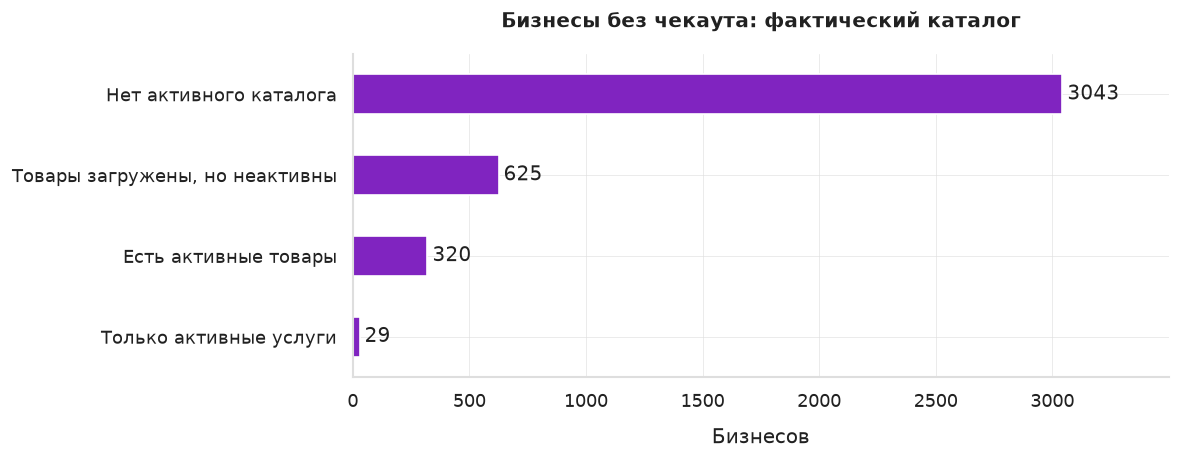

In [51]:
no_checkout = analysis.loc[analysis["Подключён чекаут"].eq(0)].copy()
no_checkout["Профиль каталога"] = np.select(
    [no_checkout["Есть_товары"], no_checkout["Есть_услуги"], no_checkout["Товары загружены"].gt(0)],
    ["Есть активные товары", "Только активные услуги", "Товары загружены, но неактивны"], default="Нет активного каталога")
no_checkout_profile = no_checkout.groupby("Профиль каталога").agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "Подписчики, медиана": ("Число подписчиков", "median"),
    "Публикуют": ("Публикаций", lambda x: x.gt(0).sum()), "С товарными просмотрами": ("Есть_просмотры", "sum"),
    "С открытиями": ("Есть_открытия", "sum"), "С рекламой": ("Есть_реклама", "sum"), "С заказами за период": ("Есть_заказы", "sum")})
no_checkout_profile["Доля, %"] = no_checkout_profile["Бизнесов"] / len(no_checkout) * 100
no_checkout_summary = no_checkout_profile[["Бизнесов", "Доля, %", "Подписчики, медиана", "С заказами за период"]].reset_index()
display(no_checkout_summary.round(2))
ax = no_checkout_profile["Бизнесов"].sort_values().plot.barh(figsize=(10, 4), color="#8024C0")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set(title="Бизнесы без чекаута: фактический каталог", xlabel="Бизнесов", ylabel="")
ax.margins(x=.15)
plt.tight_layout()
plt.show()

**Активность внутри каждой группы**

In [52]:
no_checkout_activity = pd.DataFrame(index=no_checkout_profile.index)
for column in ["Публикуют", "С товарными просмотрами", "С открытиями", "С рекламой"]:
    no_checkout_activity[column] = [
        f"{int(count)} из {int(total)} ({count / total * 100:.2f}%)".replace(".", ",")
        for count, total in no_checkout_profile[[column, "Бизнесов"]].itertuples(index=False, name=None)]
display(no_checkout_activity.reset_index())

,Профиль каталога,Публикуют,С товарными просмотрами,С открытиями,С рекламой
0,Есть активные товары,"259 из 320 (80,94%)","128 из 320 (40,00%)","55 из 320 (17,19%)","29 из 320 (9,06%)"
1,Нет активного каталога,"2285 из 3043 (75,09%)","59 из 3043 (1,94%)","32 из 3043 (1,05%)","130 из 3043 (4,27%)"
2,"Товары загружены, но неактивны","486 из 625 (77,76%)","38 из 625 (6,08%)","12 из 625 (1,92%)","45 из 625 (7,20%)"
3,Только активные услуги,"21 из 29 (72,41%)","3 из 29 (10,34%)","1 из 29 (3,45%)","4 из 29 (13,79%)"


**Выводы:**

- **У большинства бизнесов без чекаута нет активного каталога:** 3 043 бизнеса, или 75,75%. Ещё у 625 (15,56%) товары загружены, но неактивны.
- **Активные товары есть только у 320 бизнесов (7,97%).** Их медиана аудитории — 1 300 подписчиков; у группы без активного каталога — 340.
- Среди этих 320 бизнесов **259 публикуют контент (80,94%)**, у 128 есть товарные просмотры (40,00%), у 55 — открытия карточек (17,19%). То есть отсутствие чекаута не означает отсутствия активности.
- У 14 бизнесов за период были заказы: 7 с активными товарами и 7 с загруженными неактивными товарами. Это совместимо с выключенным чекаутом на конец периода.

**Что это означает:** бизнесы без чекаута находятся в разных ситуациях. У большинства нет активной витрины, у части каталог неактивен, а у небольшой группы товары уже получают внимание покупателей. Поэтому отсутствие подключения нельзя объяснять одной общей причиной.

**Переход к следующему шагу:** Отдельно рассмотрим бизнесы с активными товарами: в каких группах по аудитории и каталогу чекаут подключён, а в каких ещё нет?

### Шаг 22. Подключение чекаута при похожих аудитории и каталоге

**Вопрос:** В каких группах товарных бизнесов чекаут ещё не подключён?

**Выборка: все 3 961 бизнеса с активными товарами**, с чекаутом и без него. Сравниваем внутри групп по аудитории и размеру каталога. В таблице доля без чекаута считается от общего числа бизнесов соответствующей строки; на карте — число неподключённых бизнесов.

,Подписчиков,Активных товаров,Всего бизнесов,Без чекаута,"Без чекаута, %"
0,До 1 000,1–10,1177,52,4.42
1,До 1 000,11–50,696,51,7.33
2,До 1 000,От 51,346,36,10.40
3,1 000–9 999,1–10,615,48,7.80
4,1 000–9 999,11–50,458,43,9.39
5,1 000–9 999,От 51,414,43,10.39
6,От 10 000,1–10,67,11,16.42
7,От 10 000,11–50,75,12,16.00
8,От 10 000,От 51,113,24,21.24


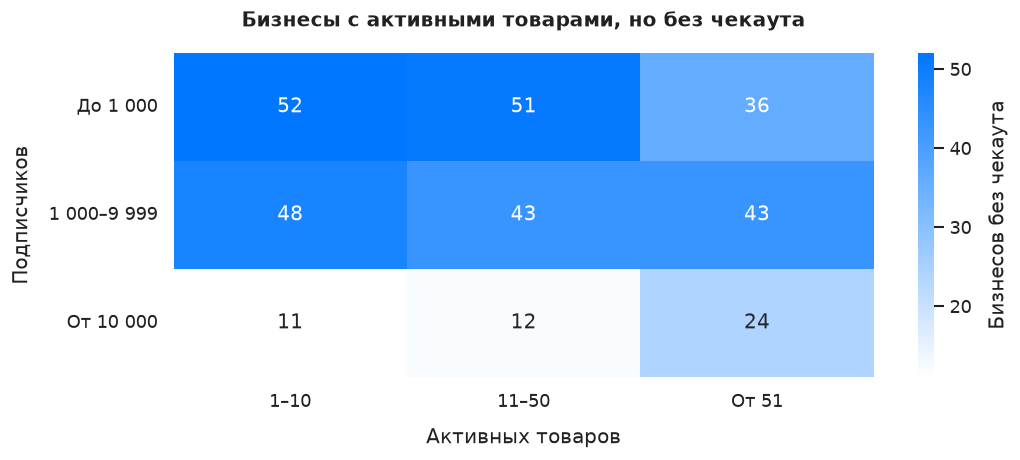

In [53]:
goods_businesses = analysis.loc[analysis["Есть_товары"]].copy()
goods_businesses["Есть чекаут"] = goods_businesses["Подключён чекаут"].eq(1)
adoption = goods_businesses.groupby(["Аудитория", "Каталог"], observed=True).agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "С чекаутом": ("Есть чекаут", "sum")})
adoption["Без чекаута"] = adoption["Бизнесов"] - adoption["С чекаутом"]
adoption["Подключён, %"] = adoption["С чекаутом"] / adoption["Бизнесов"] * 100
adoption["Без чекаута, %"] = adoption["Без чекаута"] / adoption["Бизнесов"] * 100
adoption_readable = adoption[["Бизнесов", "Без чекаута", "Без чекаута, %"]].reset_index().rename(
    columns={"Аудитория": "Подписчиков", "Каталог": "Активных товаров", "Бизнесов": "Всего бизнесов"})
display(adoption_readable.round(2))
fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(adoption["Без чекаута"].unstack("Каталог"), annot=True, fmt=".0f", cmap=SEQUENTIAL_CMAP,
            cbar_kws={"label": "Бизнесов без чекаута"}, ax=ax)
ax.set(title="Бизнесы с активными товарами, но без чекаута", xlabel="Активных товаров", ylabel="Подписчиков")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

**Выводы:**

- Среди бизнесов с активными товарами **320 из 3 961 не подключили чекаут — 8,08%**. Остальные 3 641 уже подключены.
- **Неподключённые есть во всех девяти группах.** Больше всего по числу — среди малых сообществ с 1–10 товарами (52 бизнеса) и 11–50 товарами (51).
- **Наибольшая доля без чекаута — у крупных сообществ с каталогом от 51 товара:** 24 из 113, или 21,24%. Среди малых сообществ с 1–10 товарами — 52 из 1 177, или 4,42%.

**Что это означает:** большая аудитория и большой каталог не означают автоматического подключения чекаута. При этом крупнейшая доля неподключённых и крупнейшее абсолютное число неподключённых находятся в разных группах.

**Переход к следующему шагу:** Мы определили базу неподключённых товарных бизнесов. У кого из них уже есть просмотры товаров или открытия карточек?

### Шаг 23. Признаки торговой активности без чекаута

**Вопрос:** У каких бизнесов без чекаута товары уже получают внимание?

Сначала смотрим признаки активности **среди 320 бизнесов с активными товарами**. Признаки пересекаются: один бизнес может иметь и просмотры, и открытия, и рекламу. Затем отдельно считаем уникальные бизнесы с просмотрами или открытиями карточек и без заказов за период. Их нельзя суммировать по отдельным признакам.

In [54]:
readiness_masks = {
    "Есть активные товары": no_checkout["Есть_товары"],
    "Товары и товарные просмотры": no_checkout["Есть_товары"] & no_checkout["Есть_просмотры"],
    "Товары и открытия карточек": no_checkout["Есть_товары"] & no_checkout["Есть_открытия"],
    "Товары и реклама": no_checkout["Есть_товары"] & no_checkout["Есть_реклама"],
    "Только активные услуги": ~no_checkout["Есть_товары"] & no_checkout["Есть_услуги"],
}
readiness = pd.DataFrame({name: {
    "Бизнесов": int(mask.sum()), "Подписчики, медиана": no_checkout.loc[mask, "Число подписчиков"].median(),
    "С заказами за период": int(no_checkout.loc[mask, "Есть_заказы"].sum()),
} for name, mask in readiness_masks.items()}).T
goods_signals = readiness.loc[["Есть активные товары", "Товары и товарные просмотры", "Товары и открытия карточек", "Товары и реклама"], ["Бизнесов", "Подписчики, медиана"]].copy()
goods_signals["Доля от 320 бизнесов, %"] = goods_signals["Бизнесов"] / readiness.loc["Есть активные товары", "Бизнесов"] * 100
goods_signals["Бизнесов"] = goods_signals["Бизнесов"].astype(int)
display(goods_signals.round(2).rename_axis("Признак").reset_index())
connection_candidates = no_checkout.loc[no_checkout["Есть_товары"] & ~no_checkout["Есть_заказы"]
    & (no_checkout["Есть_просмотры"] | no_checkout["Есть_открытия"])].copy()
candidate_topics = connection_candidates.groupby("Тематика").agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "Подписчики, медиана": ("Число подписчиков", "median")}).sort_values("Бизнесов", ascending=False)
candidate_topics["Доля кандидатов, %"] = candidate_topics["Бизнесов"] / len(connection_candidates) * 100
candidate_summary = pd.DataFrame({"Бизнесов": [len(connection_candidates)],
    "Доля от 320 бизнесов с товарами, %": [len(connection_candidates) / readiness.loc["Есть активные товары", "Бизнесов"] * 100]})
display(candidate_summary.round(2))
display(candidate_topics.head(6).round(2).reset_index())

,Признак,Бизнесов,"Подписчики, медиана","Доля от 320 бизнесов, %"
0,Есть активные товары,320,1300.0,100.00
1,Товары и товарные просмотры,128,1350.0,40.00
2,Товары и открытия карточек,55,1900.0,17.19
3,Товары и реклама,29,8000.0,9.06


,Бизнесов,"Доля от 320 бизнесов с товарами, %"
0,124,38.75


,Тематика,Бизнесов,"Подписчики, медиана","Доля кандидатов, %"
0,Кулинария и еда,16,1035.0,12.90
1,Мода и стиль,16,3950.0,12.90
2,Образование,12,2400.0,9.68
3,Творчество и хендмейд,12,1100.0,9.68
4,Красота и здоровье,11,1000.0,8.87
5,Товары и магазины,9,550.0,7.26


**Выводы:**

- Из 320 бизнесов с активными товарами у **128 есть товарные просмотры (40,00%)**, у 55 — открытия карточек (17,19%), у 29 — рекламные расходы (9,06%).
- **124 уникальных бизнеса** одновременно имеют активные товары, просмотры или открытия карточек, но не имеют чекаута и заказов за период. Это **38,75%** неподключённых бизнесов с активными товарами.
- В этой группе больше всего бизнесов из тематик **«Кулинария и еда» и «Мода и стиль» — по 16**, затем «Образование» и «Творчество и хендмейд» — по 12.

**Что это означает:** внутри неподключённых есть отдельная группа, где товарный сценарий уже используется и интерес к товарам наблюдается. Это отличается от отсутствия активного каталога; само неподключение ещё не объясняет мотив продавца.

**Возможные барьеры неподключения — гипотезы**

Каталог может быть неактуальным или не подготовленным для продаж; продавец может не видеть перспектив заказов через чекаут либо предпочитать привычное оформление покупки в сообщениях или на сайте. Эти объяснения не приравниваем к измеренным мотивам.

### Основные выводы по части 3

- **Широкая база без чекаута — 4 017 бизнесов, но активные товары есть только у 320.** Большинство остальных находится в другом состоянии каталога.
- **625 бизнесов уже загружали товары, но сейчас они неактивны.** Это отдельная ситуация от полного отсутствия активной витрины.
- **Большая аудитория и каталог не гарантируют подключения:** среди крупных сообществ с каталогом от 51 товара без чекаута остаются 21,24%.
- **У 124 бизнесов уже есть активные товары и товарные просмотры или открытия, но нет чекаута и заказов за период.** Это самостоятельная группа внутри товарных бизнесов, а не все неподключённые продавцы.

**Что это означает:** отсутствие чекаута объединяет разные ситуации — от отсутствия активного каталога до уже работающего товарного контента. Возможные причины и задачи этих групп различаются.

**Переход к следующей части:** Мы описали бизнесы с чекаутом и без него. Теперь проверим, насколько устойчивы найденные различия и какие признаки помогают различать бизнесы с заказами при совместном учёте.

## Часть 4. Совместная проверка признаков

Проверяем, сохраняются ли наблюдения при изменении состава выборки и при одновременном учёте нескольких характеристик бизнеса.

### Шаг 24. Устойчивость результата и реферальная программа

**Вопрос:** Сохраняется ли связь товарных просмотров с заказами при проверках чувствительности?

Участие остаётся признаком, основной набор данных не сокращаем. Дополнительные расчёты — проверки чувствительности. Сравниваем разницы долей только в тех сочетаниях аудитории и каталога, где во всех вариантах осталось хотя бы по 30 бизнесов с просмотрами и без них.

In [55]:
referral_profile = analysis.groupby("Участие в реферальной программе").agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "С товарными просмотрами": ("Есть_просмотры", "sum"),
    "С заказами": ("Есть_заказы", "sum"), "Товарных просмотров": ("Просмотры товарного контента", "sum"),
    "GMV, ₽": ("GMV через чекаут, ₽", "sum")})
referral_readable = referral_profile[["Бизнесов", "С товарными просмотрами", "С заказами", "GMV, ₽"]].rename(
    index={0: "Не участвует", 1: "Участвует"}).rename_axis("Реферальная программа").reset_index()
display(referral_readable)

def view_order_difference(data):
    table = data.groupby(["Аудитория", "Каталог", "Есть_просмотры"], observed=True).agg(
        n=("ID бизнеса", "size"), orders=("Есть_заказы", "sum")).unstack("Есть_просмотры")
    table = table.reindex(columns=pd.MultiIndex.from_product([["n", "orders"], [False, True]]))
    enough = table["n"].ge(30).all(axis=1)
    rates = table["orders"] / table["n"] * 100
    return (rates[True] - rates[False]).loc[enough]

audience_p99 = commerce["Число подписчиков"].quantile(.99)
robust_samples = {"Все бизнесы подгруппы": commerce,
    "Без участников реферальной программы": commerce.loc[commerce["Участие в реферальной программе"].eq(0)],
    "Без верхнего 1% по аудитории": commerce.loc[commerce["Число подписчиков"].le(audience_p99)]}
robust_differences = {name: view_order_difference(sample) for name, sample in robust_samples.items()}
shared_cells = next(iter(robust_differences.values())).index
for differences in robust_differences.values():
    shared_cells = shared_cells.intersection(differences.index)
sensitivity = pd.DataFrame({name: {"Бизнесов": len(robust_samples[name]), "Общих сравнимых срезов": len(shared_cells),
    "Срезов с положительной разницей": int(differences.reindex(shared_cells).gt(0).sum()),
    "Медиана разницы долей, п.п.": differences.reindex(shared_cells).median()}
    for name, differences in robust_differences.items()}).T
sensitivity_readable = sensitivity[["Бизнесов", "Медиана разницы долей, п.п."]].copy()
sensitivity_readable["Сравнений с положительной разницей"] = [
    f"{int(positive)} из {int(total)}" for positive, total in sensitivity[
        ["Срезов с положительной разницей", "Общих сравнимых срезов"]].itertuples(index=False, name=None)]
sensitivity_readable["Бизнесов"] = sensitivity_readable["Бизнесов"].astype(int)
display(sensitivity_readable.round(2).rename_axis("Вариант проверки").reset_index())

,Реферальная программа,Бизнесов,С товарными просмотрами,С заказами,"GMV, ₽"
0,Не участвует,9553,1218,281,9252497
1,Участвует,201,98,17,720530


,Вариант проверки,Бизнесов,"Медиана разницы долей, п.п.",Сравнений с положительной разницей
0,Все бизнесы подгруппы,3641,2.82,7 из 7
1,Без участников реферальной программы,3550,3.02,7 из 7
2,Без верхнего 1% по аудитории,3605,2.82,7 из 7


**Выводы:** во всех трёх вариантах — основном, без участников реферальной программы и без верхнего 1% по аудитории — в **7 из 7 общих сравнений** доля бизнесов с заказами выше при наличии товарных просмотров. Медианная разница составляет **2,82; 3,02 и 2,82 п.п.**

**Что это означает:** наблюдение не исчезает при этих изменениях состава выборки. Основную выборку не сокращаем: реферальную программу сохраняем как признак.

**Переход к следующему шагу:** Отдельные сравнения учитывают лишь часть различий. Помогают ли характеристики бизнеса совместно различать сообщества с заказами и без них?

### Шаг 25. Совместная проверка признаков

**Вопрос:** Какие признаки помогают различать бизнесы с заказами, если учитывать их одновременно?

Берём бизнесы с чекаутом и обучаем логистическую регрессию определять наличие заказа. Аудитория, каталог, цена, тематика, контент и инструменты рассматриваются вместе. **Число заказов, GMV и средний чек в признаки не входят.** Проверяем качество на бизнесах, не использованных для обучения соответствующего расчёта; это описание связей текущего периода.

In [56]:
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, silhouette_score, adjusted_rand_score, davies_bouldin_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
OUTPUT_DIR = Path("analysis_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
model_data = analysis.loc[analysis["Подключён чекаут"].eq(1)].copy()
numeric_sources = {"Подписчики": "Число подписчиков", "Активные товары": "Число активных товаров в каталоге",
    "Активные услуги": "Число активных услуг", "Публикации": "Публикаций"}
X_model = pd.DataFrame({name: np.log1p(model_data[column]) for name, column in numeric_sources.items()}, index=model_data.index)
X_model["Цена"] = np.log1p(model_data["Медианная цена товара, ₽"].where(model_data["Статус цены"].eq("Цена указана")))
for name, column in {"Товарные просмотры": "Есть_просмотры", "Реклама": "Есть_реклама", "Доставка": "Подключена доставка", "Оплата": "Подключена оплата"}.items():
    X_model[name] = model_data[column].astype(int)
X_model["Тематика"] = model_data["Тематика"]
X_model["Оригинальность"] = model_data["Автор оригинального контента (оценка модели)"].map({0: "Отрицательная", 1: "Положительная", 2: "Нет оценки"})
X_model["Статус цены"] = model_data["Статус цены"]
categorical_model = ["Тематика", "Оригинальность", "Статус цены"]
numeric_model = X_model.columns.difference(categorical_model).tolist()
preprocessor = ColumnTransformer([
    ("Числа", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), numeric_model),
    ("Категории", OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=30), categorical_model)])
order_model = make_pipeline(preprocessor, LogisticRegression(C=.5, max_iter=2000, random_state=RANDOM_STATE))
y_model = model_data["Есть_заказы"].astype(int)
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
oof_probability = cross_val_predict(order_model, X_model, y_model, cv=cv, method="predict_proba")[:, 1]
baseline_probability = np.repeat(y_model.mean(), len(y_model))
model_quality = pd.DataFrame({name: {"ROC-AUC": roc_auc_score(y_model, prediction),
    "Average Precision": average_precision_score(y_model, prediction), "Brier, меньше лучше": brier_score_loss(y_model, prediction)}
    for name, prediction in {"Постоянная доля заказов": baseline_probability, "Модель, отложенные фолды": oof_probability}.items()}).T
display(model_quality[["Average Precision", "ROC-AUC"]].round(4))

,Average Precision,ROC-AUC
Постоянная доля заказов,0.0495,0.500
"Модель, отложенные фолды",0.4232,0.888


,Признак,Снижение Average Precision,Разброс повторов
0,Подписчики,0.2255,0.0396
1,Активные товары,0.1483,0.0260
2,Цена,0.0899,0.0286
3,Тематика,0.0805,0.0183
4,Товарные просмотры,0.0694,0.0238
5,Активные услуги,0.0287,0.0122
6,Оригинальность,0.0257,0.0136
7,Реклама,0.0108,0.0069


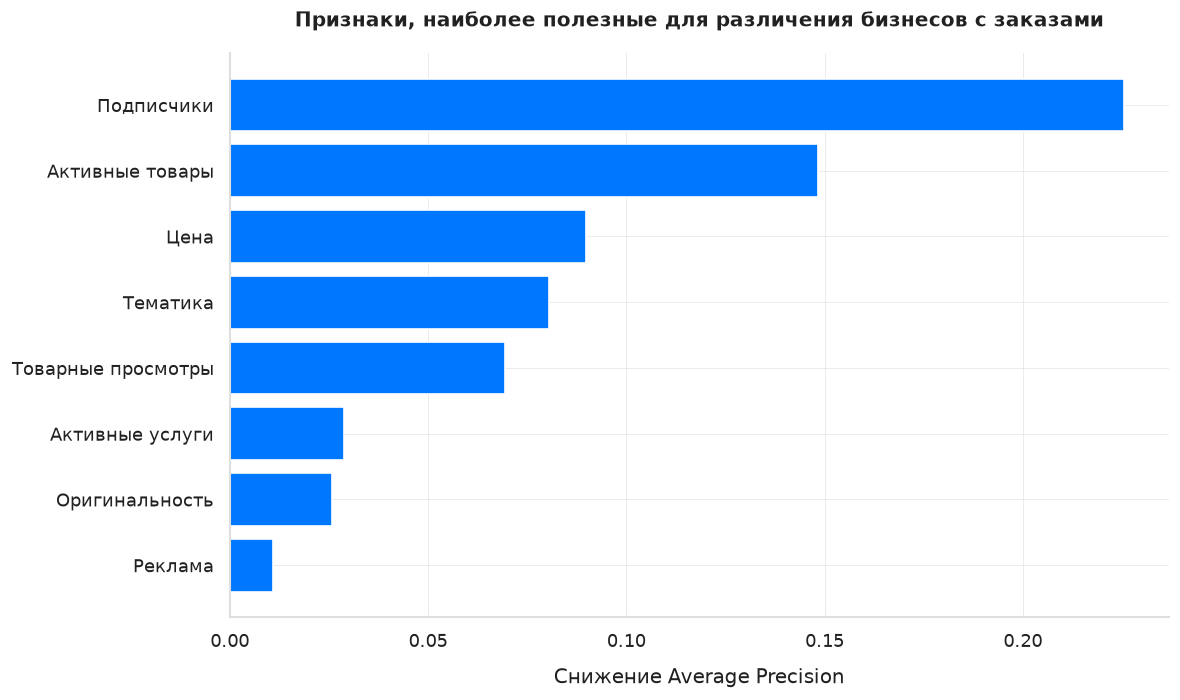

In [57]:
train_ids, test_ids = train_test_split(X_model.index, test_size=.25, stratify=y_model, random_state=RANDOM_STATE)
order_model.fit(X_model.loc[train_ids], y_model.loc[train_ids])
importance_result = permutation_importance(order_model, X_model.loc[test_ids], y_model.loc[test_ids],
    scoring="average_precision", n_repeats=10, random_state=RANDOM_STATE)
feature_importance = pd.DataFrame({"Признак": X_model.columns, "Снижение Average Precision": importance_result.importances_mean,
    "Разброс повторов": importance_result.importances_std}).sort_values("Снижение Average Precision", ascending=False)
display(feature_importance.head(8).round(4).reset_index(drop=True))
fig, ax = plt.subplots(figsize=(10, 6))
plot_importance = feature_importance.head(8).sort_values("Снижение Average Precision")
ax.barh(plot_importance["Признак"], plot_importance["Снижение Average Precision"], color="#0077FF")
ax.axvline(0, color="gray", linewidth=1)
ax.set(title="Признаки, наиболее полезные для различения бизнесов с заказами", xlabel="Снижение Average Precision", ylabel="")
plt.tight_layout()
plt.show()

На графике показаны восемь наиболее информативных признаков. Чем сильнее ухудшается качество модели при перемешивании признака, тем важнее он для этого сравнения. Это **важность для модели**, а не ожидаемый прирост заказов от изменения признака.

**Выводы:** модель различает бизнесы с заказами лучше базового ориентира: **Average Precision 0,423 против 0,050; ROC-AUC 0,888 против 0,500**. Важнейшие признаки на отдельной тестовой части — аудитория, активные товары, цена, тематика и товарные просмотры.

**Что это означает:** эти характеристики полезно рассматривать вместе. Высокая модельная важность не означает, что изменение одного признака автоматически даст больше заказов; метрики качества — не проценты покупателей или конверсия.

**Переход к следующему шагу:** Мы изучили связи отдельных признаков и их сочетаний с заказами. Какие группы предложит алгоритм, если не использовать заказы при построении кластеров?

## Часть 5. Кластеризация

Алгоритм самостоятельно группирует бизнесы по характеристикам и активности. После обучения описываем группы и смотрим на их результаты; стратегические решения рассматриваются отдельно.

### Шаг 26. Кластеризация: признаки и выбор числа групп

**Вопрос:** Какие группы бизнесов выделяет алгоритм без заранее заданных сегментов?

Используем **все 9 754 бизнеса** и KMeans. Аудитория, каталог, контент, просмотры, реклама и инструменты участвуют в разбиении. **Заказы, GMV и средний чек исключены**: результаты оцениваем после построения групп. Тематика и заявленный тип бизнеса также не определяют разбиение. Числовые показатели приводим к сопоставимому масштабу, а блоки — к сопоставимому весу.

In [58]:
cluster_numeric = pd.DataFrame({
    "Аудитория": analysis["Число подписчиков"], "Активные товары": analysis["Число активных товаров в каталоге"],
    "Активные услуги": analysis["Число активных услуг"],
    "Цена": analysis["Медианная цена товара, ₽"].where(analysis["Статус цены"].eq("Цена указана")),
    "Обычные публикации": analysis["Посты за 30 дней"] + analysis["Клипы за 30 дней"],
    "Товарные публикации": analysis["Посты с товаром за 30 дней"] + analysis["Клипы с товаром за 30 дней"],
    "Обычные просмотры": analysis["Просмотры обычного контента"], "Товарные просмотры": analysis["Просмотры товарного контента"],
    "Открытия": analysis["Открытия карточки товара из контента"], "Реклама": analysis["Траты на рекламу всего, ₽"]})
cluster_numeric["Цена"] = cluster_numeric["Цена"].fillna(cluster_numeric["Цена"].median())
cluster_blocks = {"Аудитория": ["Аудитория"], "Каталог": ["Активные товары", "Активные услуги", "Цена"],
    "Контент": ["Обычные публикации", "Товарные публикации", "Обычные просмотры", "Товарные просмотры", "Открытия"], "Реклама": ["Реклама"]}
cluster_parts = []
for columns in cluster_blocks.values():
    scaled = StandardScaler().fit_transform(np.log1p(cluster_numeric[columns]))
    cluster_parts.append(np.clip(scaled, -3, 3) / np.sqrt(len(columns)))
cluster_flags = analysis[["Подключён чекаут", "Подключена доставка", "Подключена оплата", "Участие в реферальной программе"]].astype(float)
cluster_flags["Неактивные загруженные товары"] = (analysis["Товары загружены"].gt(0) & ~analysis["Есть_товары"]).astype(float)
cluster_categories = pd.get_dummies(analysis[["Статус цены", "Автор оригинального контента (оценка модели)"]].astype(str), dtype=float)
cluster_flags = pd.concat([cluster_flags, cluster_categories], axis=1)
X_cluster = np.column_stack(cluster_parts + [cluster_flags.to_numpy() * .5])
assert np.isfinite(X_cluster).all()
cluster_feature_list = pd.DataFrame({"Блок": [name for name, columns in cluster_blocks.items() for column in columns] + ["Инструменты и статусы"] * len(cluster_flags.columns),
    "Признак": [column for columns in cluster_blocks.values() for column in columns] + cluster_flags.columns.tolist()})
cluster_feature_summary = pd.DataFrame({"Блок": ["Аудитория", "Каталог", "Контент", "Реклама", "Инструменты", "Статусы"],
    "Что учитываем": ["Число подписчиков", "Активные товары и услуги, цена",
        "Публикации, просмотры и открытия карточек", "Общие рекламные расходы",
        "Чекаут, доставка, оплата, участие в реферальной программе",
        "Оригинальность, известность цены, загруженные неактивные товары"]})
display(cluster_feature_summary)

,Блок,Что учитываем
0,Аудитория,Число подписчиков
1,Каталог,"Активные товары и услуги, цена"
2,Контент,"Публикации, просмотры и открытия карточек"
3,Реклама,Общие рекламные расходы
4,Инструменты,"Чекаут, доставка, оплата, участие в реферально..."
5,Статусы,"Оригинальность, известность цены, загруженные ..."


Проверяем от 2 до 8 кластеров. **Silhouette** показывает, насколько группы отделены друг от друга; выше — лучше. **ARI между запусками** показывает, повторяется ли разбиение; ближе к 1 — устойчивее. Выбираем лучший silhouette среди вариантов, где самый маленький кластер составляет хотя бы 2%, а ARI не ниже 0,8. Это настройки анализа; желаемое число стратегических групп алгоритму не задаём.

,Кластеров,Silhouette,"Минимальная доля, %",ARI между запусками,Выбран
0,2,0.2078,48.9235,0.9998,
1,3,0.2275,5.4644,0.9978,Да
2,4,0.1973,5.4644,0.9940,
3,5,0.2108,5.4644,0.9997,
4,6,0.1982,5.4644,0.9931,
5,7,0.1851,5.4644,0.9651,
6,8,0.2031,3.6908,0.8920,


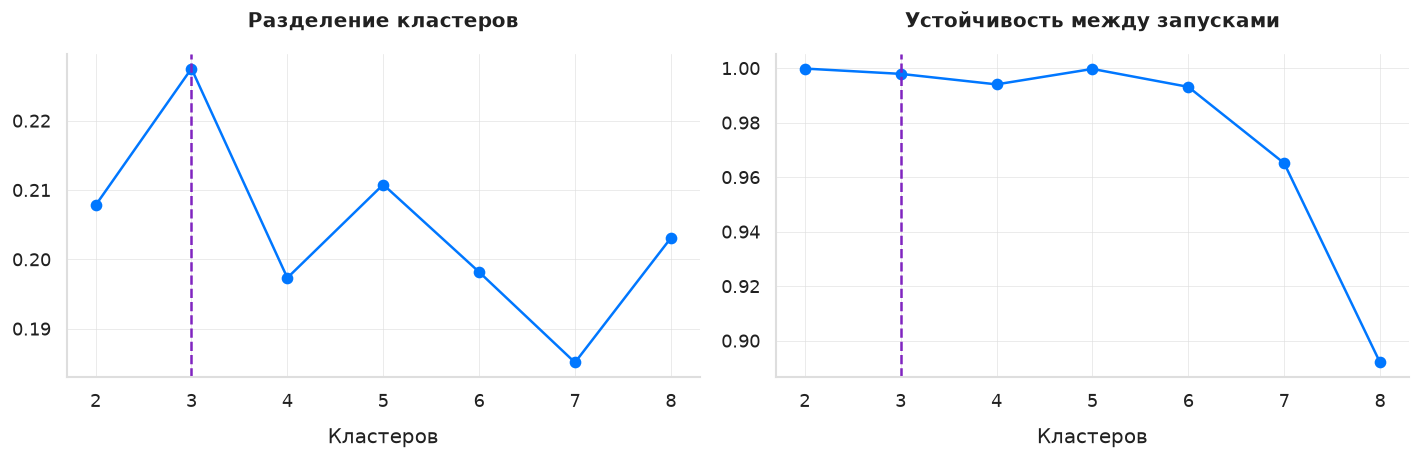

In [59]:
cluster_models, cluster_scores = {}, []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=15, random_state=RANDOM_STATE).fit(X_cluster)
    labels = model.labels_
    repeated = [KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(X_cluster) for seed in [13, 87]]
    cluster_models[k] = model
    cluster_scores.append({"Кластеров": k,
        "Silhouette": silhouette_score(X_cluster, labels, sample_size=min(2000, len(analysis)), random_state=RANDOM_STATE),
        "Davies–Bouldin": davies_bouldin_score(X_cluster, labels),
        "Минимальная доля, %": pd.Series(labels).value_counts(normalize=True).min() * 100,
        "ARI между запусками": np.mean([adjusted_rand_score(labels, other) for other in repeated])})
cluster_selection = pd.DataFrame(cluster_scores).set_index("Кластеров")
cluster_selection["Проходит ограничения"] = cluster_selection["Минимальная доля, %"].ge(2) & cluster_selection["ARI между запусками"].ge(.8)
eligible_k = cluster_selection.loc[cluster_selection["Проходит ограничения"]]
if eligible_k.empty:
    eligible_k = cluster_selection.loc[cluster_selection["Минимальная доля, %"].ge(2)]
    if eligible_k.empty:
        eligible_k = cluster_selection
selected_k = int(eligible_k["Silhouette"].idxmax())
cluster_selection["Выбран"] = cluster_selection.index == selected_k
cluster_selection_readable = cluster_selection[["Silhouette", "Минимальная доля, %", "ARI между запусками"]].copy()
cluster_selection_readable["Выбран"] = cluster_selection["Выбран"].map({True: "Да", False: ""})
display(cluster_selection_readable.round(4).reset_index())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cluster_selection["Silhouette"].plot(marker="o", ax=axes[0])
cluster_selection["ARI между запусками"].plot(marker="o", ax=axes[1])
for ax in axes:
    ax.axvline(selected_k, color="#8024C0", linestyle="--")
    ax.set_xlabel("Кластеров")
axes[0].set_title("Разделение кластеров")
axes[1].set_title("Устойчивость между запусками")
plt.tight_layout()
plt.show()

In [60]:
chosen_model = cluster_models[selected_k]
raw_labels = chosen_model.labels_
label_order = analysis.assign(raw_cluster=raw_labels).groupby("raw_cluster")["Число подписчиков"].median().sort_values().index
label_map = {label: i + 1 for i, label in enumerate(label_order)}
analysis["Кластер"] = pd.Series(raw_labels, index=analysis.index).map(label_map)
X_cluster_unweighted = np.column_stack(cluster_parts + [cluster_flags.to_numpy()])
alternative_labels = KMeans(n_clusters=selected_k, n_init=15, random_state=RANDOM_STATE).fit_predict(X_cluster_unweighted)
cluster_sensitivity = pd.DataFrame({"Проверка": ["Иной вес инструментов и статусов"],
    "ARI с основным разбиением": [adjusted_rand_score(raw_labels, alternative_labels)],
    "Бизнесов": [len(analysis)], "Кластеров": [selected_k]})
display(cluster_sensitivity.round(4))

,Проверка,ARI с основным разбиением,Бизнесов,Кластеров
0,Иной вес инструментов и статусов,0.4701,9754,3


**Выводы:** выбраны **3 кластера**. Silhouette — **0,228**, устойчивость между запусками ARI — **0,998**. При изменении веса инструментов совпадение разбиений заметно ниже — **0,470**.

**Что это означает:** при одинаковых настройках алгоритм почти повторяет результат, но состав групп зависит от выбранных весов признаков. Это найденные профили бизнесов, а не окончательный набор стратегических сегментов.

**Переход к следующему шагу:** Число кластеров выбрано, устойчивость проверена. Чем найденные группы различаются по характеристикам и результатам?

### Шаг 27. Профили найденных кластеров

**Вопрос:** Чем отличаются найденные кластеры?

Сначала показываем аудиторию, каталог и активность; затем — инструменты, заказы и основные тематики. **Все таблицы короткие: одна строка на кластер.** Доли инструментов и заказов считаются внутри кластера. Номера — обозначения групп, не рейтинг перспективности.

In [61]:
cluster_profile = analysis.groupby("Кластер").agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "Подписчики, медиана": ("Число подписчиков", "median"),
    "Активные товары, медиана": ("Число активных товаров в каталоге", "median"),
    "Активные услуги, медиана": ("Число активных услуг", "median"), "Публикации, медиана": ("Публикаций", "median"),
    "С чекаутом, %": ("Подключён чекаут", lambda x: x.mean() * 100),
    "С товарными просмотрами, %": ("Есть_просмотры", lambda x: x.mean() * 100), "С рекламой, %": ("Есть_реклама", lambda x: x.mean() * 100)})
cluster_profile.insert(1, "Доля, %", cluster_profile["Бизнесов"] / len(analysis) * 100)
cluster_results = analysis.groupby("Кластер").agg(**{
    "Бизнесов": ("ID бизнеса", "size"), "С заказами": ("Есть_заказы", "sum"),
    "Заказов": ("Заказы через чекаут", "sum"), "GMV, ₽": ("GMV через чекаут, ₽", "sum"),
    "Рекламные расходы, ₽": ("Траты на рекламу всего, ₽", "sum")})
cluster_results["С заказами, %"] = cluster_results["С заказами"] / cluster_results["Бизнесов"] * 100
cluster_results["Доля всех заказов, %"] = cluster_results["Заказов"] / analysis["Заказы через чекаут"].sum() * 100
display(cluster_profile[["Бизнесов", "Подписчики, медиана", "Активные товары, медиана", "Публикации, медиана"]].round(2).reset_index())
cluster_tools = cluster_profile[["С чекаутом, %", "С товарными просмотрами, %", "С рекламой, %"]].copy()
cluster_tools["С активными товарами, %"] = analysis.groupby("Кластер")["Есть_товары"].mean() * 100
display(cluster_tools.round(2).reset_index())
cluster_results_readable = cluster_results[["Заказов", "GMV, ₽", "Доля всех заказов, %"]].copy()
cluster_results_readable["Бизнесов с заказами"] = [
    f"{int(sellers)} из {int(total)} ({rate:.2f}%)".replace(".", ",")
    for sellers, total, rate in cluster_results[["С заказами", "Бизнесов", "С заказами, %"]].itertuples(index=False, name=None)]
display(cluster_results_readable[["Бизнесов с заказами", "Заказов", "GMV, ₽", "Доля всех заказов, %"]].round(2).reset_index())
cluster_topics = analysis.groupby(["Кластер", "Тематика"]).size().rename("Бизнесов").reset_index()
cluster_topics["Доля кластера, %"] = cluster_topics["Бизнесов"] / cluster_topics["Кластер"].map(cluster_profile["Бизнесов"]) * 100
top_cluster_topics = cluster_topics.sort_values("Бизнесов", ascending=False).groupby("Кластер").head(3).sort_values(["Кластер", "Бизнесов"], ascending=[True, False])
cluster_topics_readable = top_cluster_topics.copy()
cluster_topics_readable["Место"] = cluster_topics_readable.groupby("Кластер").cumcount() + 1
cluster_topics_readable["Тематика и бизнесов"] = cluster_topics_readable["Тематика"] + " (" + cluster_topics_readable["Бизнесов"].astype(str) + ")"
display(cluster_topics_readable.pivot(index="Кластер", columns="Место", values="Тематика и бизнесов").rename(
    columns={1: "Первая тематика", 2: "Вторая тематика", 3: "Третья тематика"}).rename_axis(columns=None).reset_index())

,Кластер,Бизнесов,"Подписчики, медиана","Активные товары, медиана","Публикации, медиана"
0,1,4519,120.0,0.0,2.0
1,2,4702,1400.0,1.0,6.0
2,3,533,2400.0,0.0,14.0


,Кластер,"С чекаутом, %","С товарными просмотрами, %","С рекламой, %","С активными товарами, %"
0,1,53.60,7.24,0.07,27.37
1,2,63.55,18.42,0.13,52.45
2,3,61.35,23.08,100.00,48.41


,Кластер,Бизнесов с заказами,Заказов,"GMV, ₽","Доля всех заказов, %"
0,1,"29 из 4519 (0,64%)",51,440090,1.47
1,2,"229 из 4702 (4,87%)",3123,6580294,89.79
2,3,"40 из 533 (7,50%)",304,2952643,8.74


,Кластер,Первая тематика,Вторая тематика,Третья тематика
0,1,Красота и здоровье (1010),Дом и ремонт (325),Кулинария и еда (278)
1,2,Красота и здоровье (628),Кулинария и еда (519),Дом и ремонт (374)
2,3,Красота и здоровье (65),Образование (55),Дом и ремонт (45)


,Компонента,"Объяснённая вариация, %"
0,1,35.07
1,2,14.94


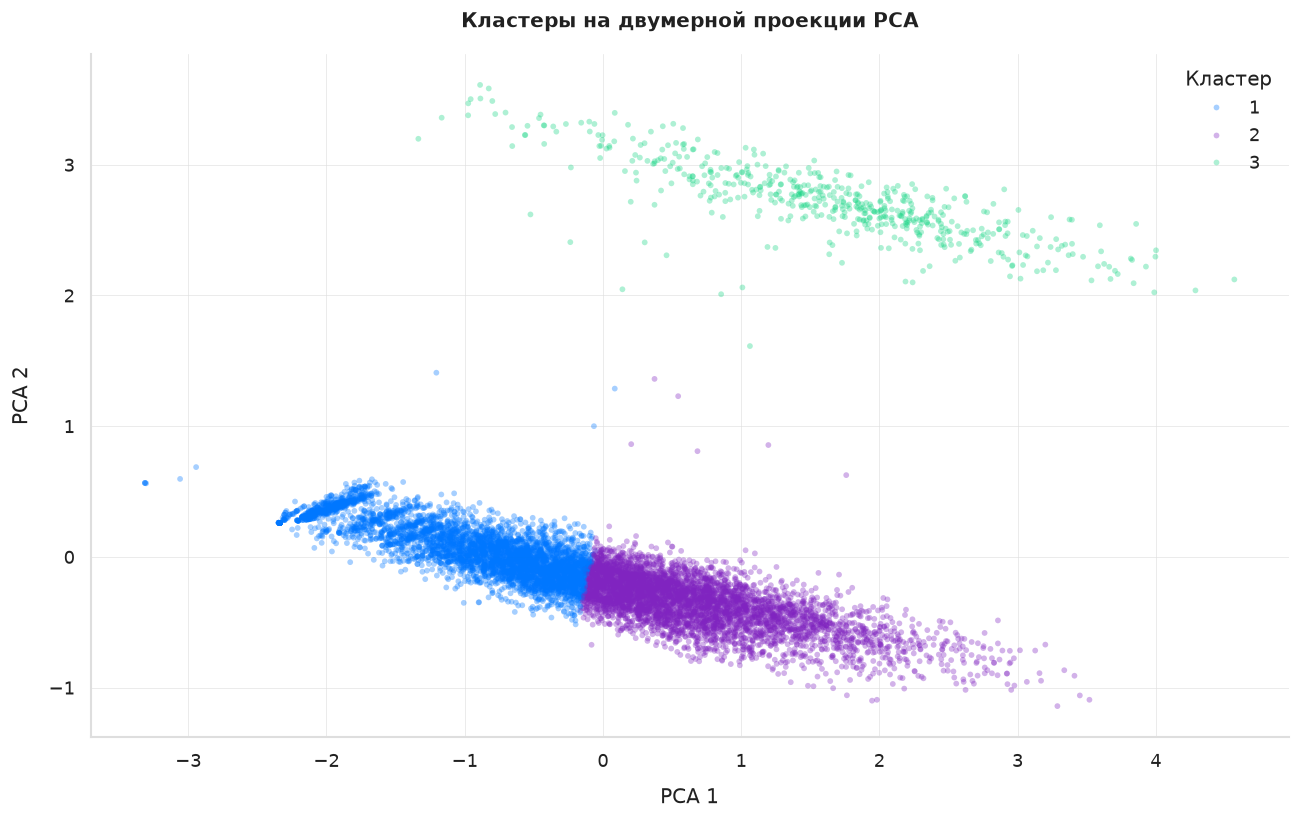

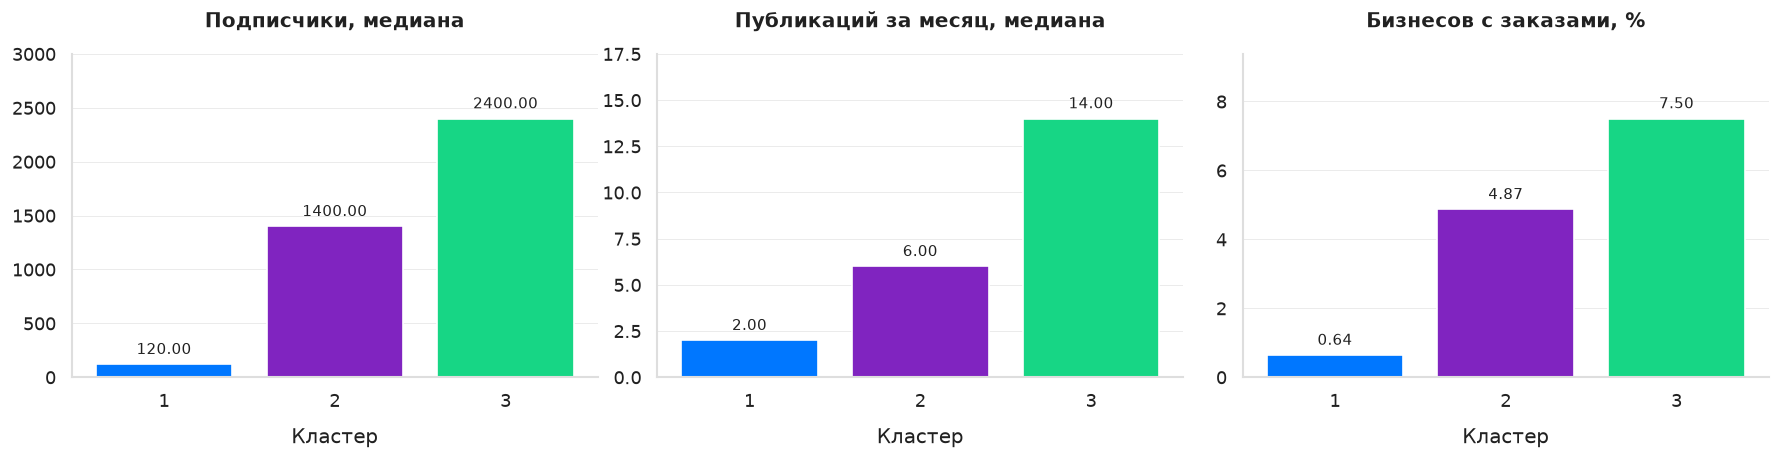

In [62]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coordinates = pca.fit_transform(X_cluster)
pca_variance = pd.DataFrame({"Компонента": [1, 2], "Объяснённая вариация, %": pca.explained_variance_ratio_ * 100})
display(pca_variance.round(2))
cluster_embedding = pd.DataFrame(coordinates, columns=["PCA 1", "PCA 2"], index=analysis.index)
cluster_embedding["Кластер"] = analysis["Кластер"].astype(str)
fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=cluster_embedding, x="PCA 1", y="PCA 2", hue="Кластер", hue_order=[str(i) for i in range(1, selected_k + 1)], palette=CHART_PALETTE[:selected_k], alpha=.35, s=12, linewidth=0, ax=ax)
ax.set(title="Кластеры на двумерной проекции PCA")
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, values, title in zip(axes,
    [cluster_profile["Подписчики, медиана"], cluster_profile["Публикации, медиана"], cluster_results["С заказами, %"]],
    ["Подписчики, медиана", "Публикаций за месяц, медиана", "Бизнесов с заказами, %"]):
    bars = ax.bar(values.index.astype(str), values, color=CHART_PALETTE[:selected_k])
    ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=9)
    ax.set(title=title, xlabel="Кластер", ylim=(0, values.max() * 1.25))
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

На точечном графике каждый бизнес показан в двумерной проекции, цвет — кластер. Две оси отображают около половины различий исходных признаков, поэтому это иллюстрация разбиения. Ниже на столбцах — исходные медианы и доли из таблиц; цвет кластеров сохранён.

**Выводы:**

- **Кластер 1 — небольшие сообщества:** 4 519 бизнесов, медиана аудитории 120, публикаций 2. Заказы есть у 29 бизнесов (0,64%), всего 51 заказ.
- **Кластер 2 — более крупные и активные сообщества:** 4 702 бизнеса, медиана аудитории 1 400, публикаций 6. Заказы есть у 229 бизнесов (4,87%); на кластер приходится 3 123 заказа — 89,79% всех заказов.
- **Кластер 3 — рекламодатели:** 533 бизнеса, медиана аудитории 2 400, публикаций 14. Все тратят на рекламу, но заказы есть у 40 (7,50%), всего 304 заказа.

**Что это означает:** алгоритм выделил различия по масштабу аудитории, активности и рекламе. Рекламный профиль не совпадает с группой, дающей наибольшее число заказов. Внутри кластеров есть и подключённые, и неподключённые бизнесы; нулевая медиана товаров не означает, что товары отсутствуют у всех.

Разбиение чувствительно к весам признаков, поэтому используем его как дополнительный взгляд на данные, сохраняя выводы о конкретных признаках из предыдущих частей.